# Đồ án Nhóm 06 Phân đoạn polyp với U-Net và U-Net++

**Mục tiêu:** hiểu nested dense skip, cài đặt U-Net++, phân đoạn Kvasir-SEG và so sánh với U-Net chuẩn.

Notebook gồm toàn bộ code cốt lõi: đọc dữ liệu, hai kiến trúc, loss, trainer, checkpoint,
khóa trước test, metric, so sánh, thống kê, phân tích head, hình và dự đoán.
Các cell định nghĩa hàm thực thi trực tiếp; không cần mở các file Python để học luồng chính.

**Đọc theo báo cáo:** Chương 1 → mục 1; Chương 3 dữ liệu/mô hình → mục 2–4;
Chương 4 thí nghiệm/đánh giá/demo → mục 5–9. Duy tích hợp và giải thích;
Khánh dữ liệu; Phúc U-Net++; Huy trainer; Trí metric và demo.

**Hai loại kết quả:** cột tham chiếu là số đã công bố trong báo cáo (A 0,6014; B 0,6682; C 0,7390).
Lượt huấn luyện mới được lưu riêng, được chọn checkpoint bằng validation trước khi test,
và không tự thay các số đã công bố. Chạy lại cùng seed không bảo đảm giống từng bit khi đổi môi trường.

## 0 Chuẩn bị và cách chạy

Mở notebook trong VS Code/Jupyter, chọn Python 3.12 của môi trường đã cài PyTorch.
Từ repo root, cài `python -m pip install -r requirements.txt -r requirements-notebook.txt`;
cài PyTorch theo README. Dữ liệu nằm ở `Kvasir-SEG/images` và `Kvasir-SEG/masks`.
`python scripts/prepare_project.py` tải checkpoint tham chiếu từ Release nếu thiếu.

Chọn **Restart Kernel → Run All**. Mặc định `TRAIN_FROM_SCRATCH=True`: huấn luyện mới cả ba
mô hình tối đa 50 epoch, seed 42, batch 8, input 256, Adam 0,001, BF16 trên GPU.
Đặt False để đánh giá lại checkpoint báo cáo mà không huấn luyện mới.
`REUSE_COMPLETED_RUN` có thể chỉ đến lượt đã huấn luyện xong để Run All đọc lại lượt đó;
đặt None để huấn luyện lượt mới. Bản đã thực thi có ghi rõ lựa chọn này trong output.
Mọi output dùng một thư mục mới theo thời gian; không ghi đè run chính thức.
Không cần bật server Streamlit để hoàn thành Run All: dự đoán và overlay xuất ngay trong notebook.

In [1]:
from __future__ import annotations
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
os.environ.setdefault('PYTHONUTF8', '1')
import ast, copy, csv, gc, hashlib, io, json, math, platform, random, shutil, subprocess, sys, time
from collections import defaultdict
from collections.abc import Sequence
from datetime import datetime, timezone, timedelta
from pathlib import Path
from typing import Any, Dict, Tuple, Union, List
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
import numpy as np
import pandas as pd
import torch
from torch import Tensor, nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display, Markdown, Image as DisplayImage
from IPython.core.pylabtools import select_figure_formats
select_figure_formats(get_ipython(), ['png'])

ROOT = next((candidate for p in [Path.cwd(), *Path.cwd().parents]
             for candidate in [p, p/'unet-vs-unetplusplus-polyp']
             if (candidate/'configs/protocol_lock.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook bên trong thư mục repo đã clone.')
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
PROJECT_ROOT = ROOT
DEFAULT_MANIFEST = ROOT/'members/khanh/works_done/dataset_splits.csv'
SPLITS = ('train', 'val', 'test')
TRAIN_FROM_SCRATCH = True
REUSE_COMPLETED_RUN = 'notebook_20261115_043920_264009'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
RUN_ID = datetime.now(timezone(timedelta(hours=7))).strftime('%Y%m%d_%H%M%S_%f')
OUTPUT = ROOT/'results'/('notebook_'+RUN_ID)
RUN_ROOT = ROOT/'runs'/('notebook_'+RUN_ID)
OUTPUT.mkdir(parents=True, exist_ok=False)
torch.set_num_threads(4)
print('Python:', platform.python_version(), '| PyTorch:', torch.__version__, '| device:', DEVICE)
print('Output:', OUTPUT.relative_to(ROOT))
if DEVICE == 'cuda': print('GPU:', torch.cuda.get_device_name(0))

Python: 3.12.14 | PyTorch: 2.11.0+cu128 | device: cuda
Output: results\notebook_20261115_052209_244321
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


## 1 Hiểu bài toán và kiến trúc

Mỗi pixel được gán polyp hoặc nền. Ảnh vào `[N,3,256,256]`; model xuất logits `[N,1,256,256]`.
Sigmoid chuyển logits thành xác suất; ngưỡng 0,5 tạo mask. Không sigmoid hai lần.

U-Net có bốn skip trực tiếp. U-Net++ thêm các node trung gian và nối mọi node trước cùng hàng:
`X(i,j) = DoubleConv(concat[X(i,0),...,X(i,j-1),Up(X(i+1,j-1))])`.
Với X(0,2), concat gồm 3×32=96 kênh; với X(0,4), gồm 5×32=160 kênh.
B chỉ có head cuối; C có bốn head và lấy trung bình bốn loss khi train.
Validation/test của cả ba mô hình dùng head cuối. Code này chưa cắt tỉa mạng khi suy luận.

Hai sơ đồ dưới đây do Duy cung cấp để chú thích cấu hình nhóm, phỏng theo bài
[U-Net](https://arxiv.org/abs/1505.04597) và [U-Net++](https://arxiv.org/abs/1807.10165).

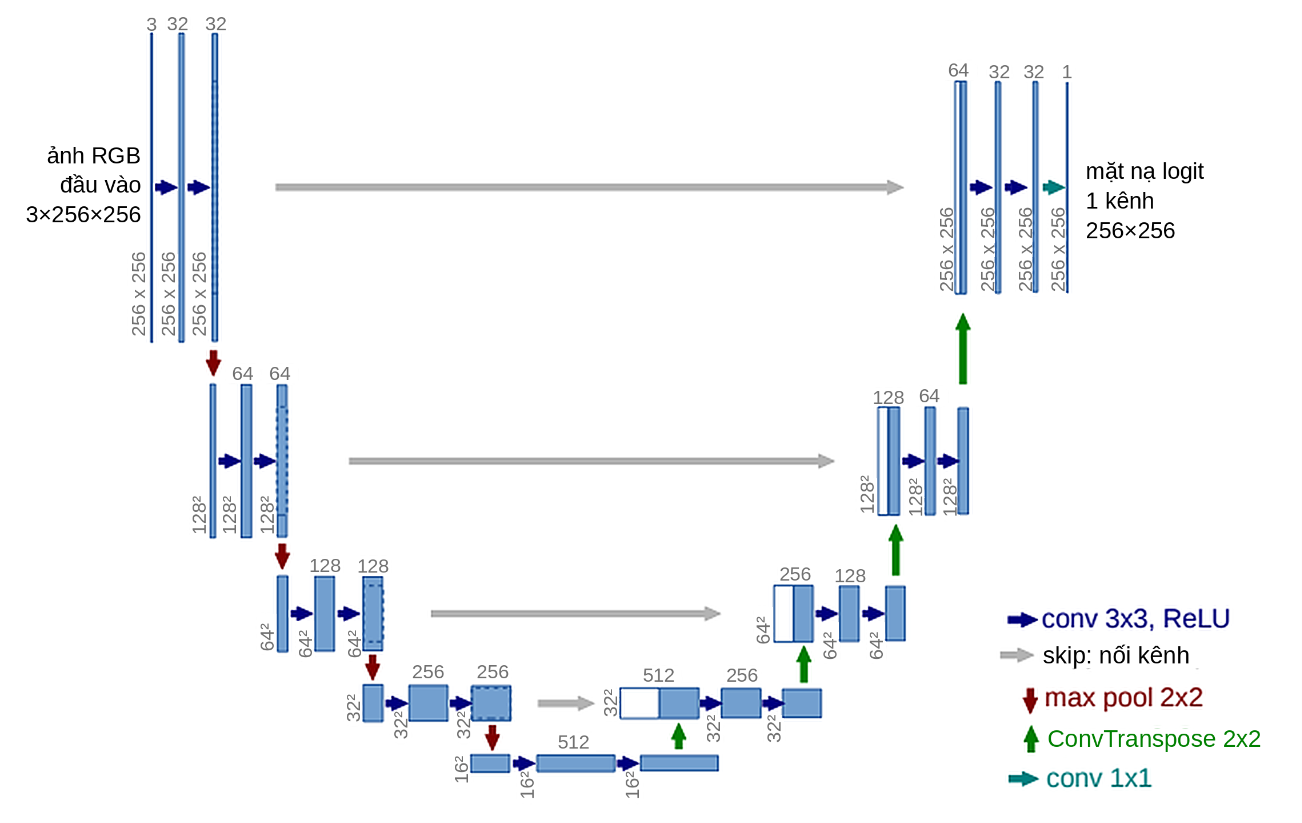

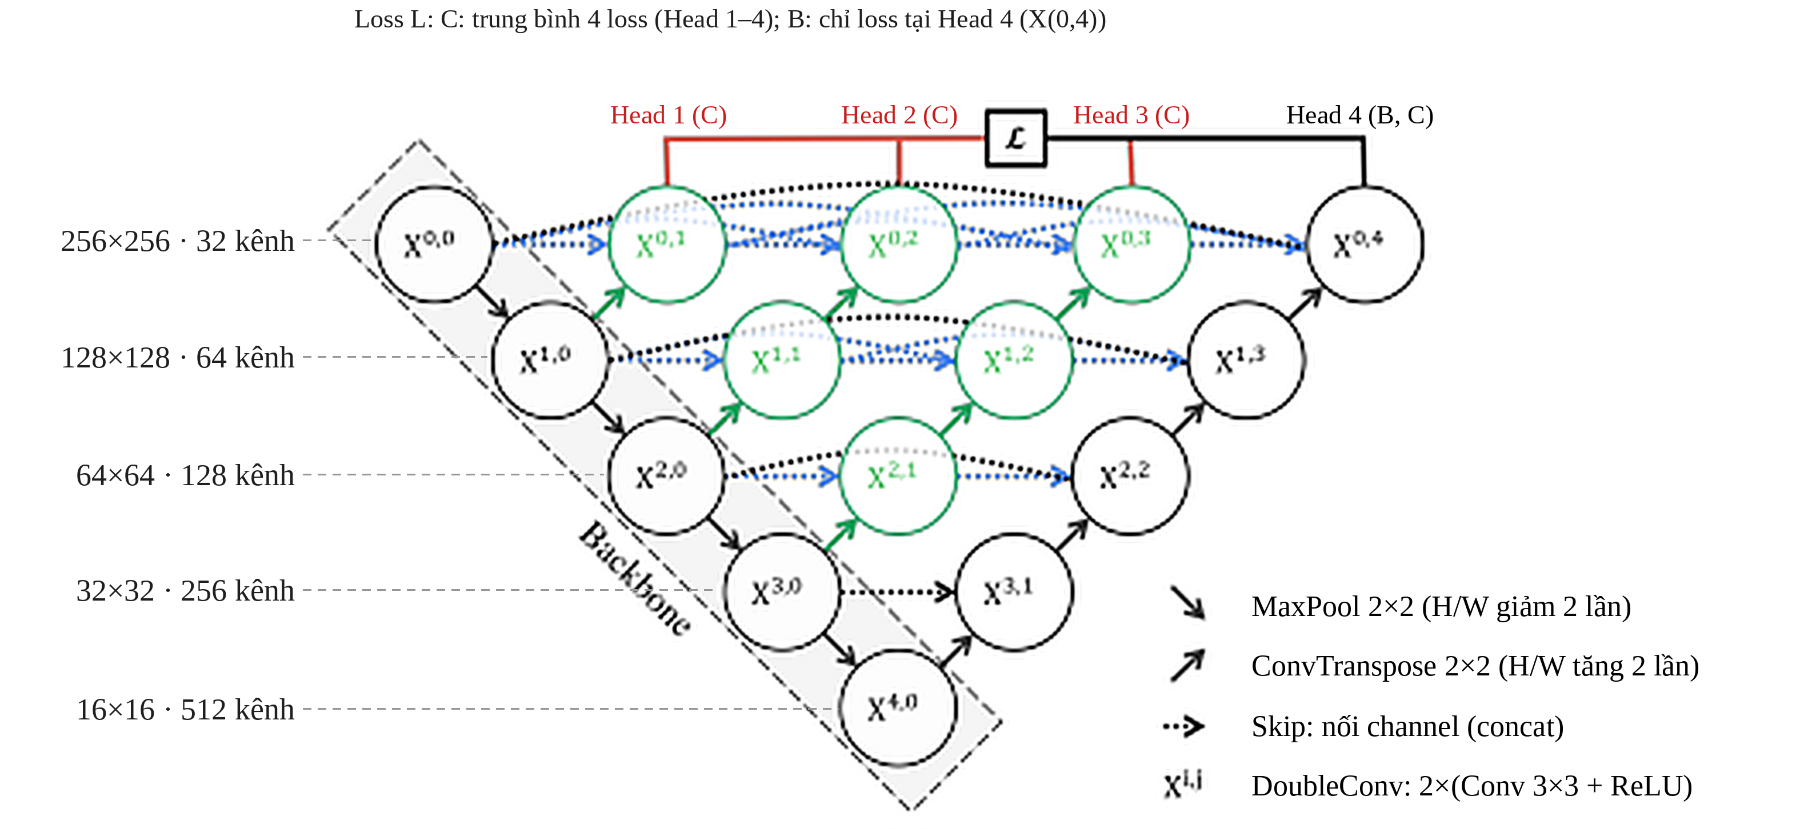

In [2]:
for name in ['unet_chu_thich.png', 'unetplusplus_chu_thich.png']:
    display(DisplayImage(filename=str(ROOT/'results/report_figures/notebook_20261115'/name), width=1000))

## 2 Dữ liệu và tiền xử lý của Khánh

Giữ manifest 700/150/150; resize mask bằng nearest, ảnh bằng linear; augmentation chỉ trên train.

### 2.1 Đọc ảnh và tạo DataLoader

Nguồn đối chiếu: `members/khanh/works_done/dataset.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [3]:
def read_image_unicode(path: Path, flags: int):
    """OpenCV giải mã byte để đọc được tên thư mục tiếng Việt trên Windows."""
    try:
        data = np.fromfile(str(path), dtype=np.uint8)
        return cv2.imdecode(data, flags) if data.size else None
    except (OSError, cv2.error):
        return None

In [4]:
def validate_manifest(frame: pd.DataFrame) -> None:
    """Kiểm tra ID/split trước khi chia loader; không tự chia lại dữ liệu."""
    required = {"image_id", "image_path", "mask_path", "split"}
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"Manifest thiếu cột: {sorted(missing)}")
    if frame.empty or frame[list(required)].isna().any().any():
        raise ValueError("Manifest rỗng hoặc có giá trị thiếu")
    if frame["image_id"].duplicated().any():
        raise ValueError("image_id bị trùng; split không độc lập theo ID")
    if not set(frame["split"]).issubset(SPLITS):
        raise ValueError("Manifest chứa split ngoài train/val/test")
    for column in ("is_corrupted", "is_shape_mismatch"):
        if column in frame and frame[column].astype(str).str.lower().eq("true").any():
            raise ValueError(f"Manifest đánh dấu lỗi {column}; sửa dữ liệu trước train")

In [5]:
def get_transforms(split: str, img_size=(256, 256), seed=42, augment=None) -> A.Compose:
    """Ảnh nội suy linear; mask nearest. Val/test luôn xử lý cố định."""
    if split not in SPLITS:
        raise ValueError(f"Split không hợp lệ: {split}")
    if len(img_size) != 2 or any(int(v) != v or v < 16 for v in img_size):
        raise ValueError("img_size phải có hai số nguyên >=16")
    use_augmentation = split == "train" if augment is None else bool(augment)
    if split != "train" and use_augmentation:
        raise ValueError("Không được augmentation ngẫu nhiên trên val/test")
    transforms = [A.Resize(height=int(img_size[0]), width=int(img_size[1]),
                           interpolation=cv2.INTER_LINEAR,
                           mask_interpolation=cv2.INTER_NEAREST)]
    if use_augmentation:
        transforms += [
            A.HorizontalFlip(p=0.5),
            A.VerticalFlip(p=0.5),
            A.RandomRotate90(p=0.5),
            # Affine thay ShiftScaleRotate: fill/fill_mask đúng Albumentations 2.
            A.Affine(scale=(0.9, 1.1),
                     translate_percent={"x": (-0.06, 0.06), "y": (-0.06, 0.06)},
                     rotate=(-15, 15), interpolation=cv2.INTER_LINEAR,
                     mask_interpolation=cv2.INTER_NEAREST, keep_ratio=True,
                     border_mode=cv2.BORDER_CONSTANT, fill=0, fill_mask=0, p=0.5),
            A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.4),
        ]
    transforms += [
        A.Normalize(mean=(0, 0, 0), std=(1, 1, 1), max_pixel_value=255),
        ToTensorV2(),
    ]
    return A.Compose(transforms, seed=int(seed))

In [6]:
class KvasirDataset(Dataset):
    """Một ảnh RGB float32 [3,H,W], mask nhị phân [1,H,W], tùy chọn ID."""

    def __init__(self, csv_path=None, split="train", project_root=None,
                 img_size=(256, 256), seed=42, return_id=False, augment=None):
        if split not in SPLITS:
            raise ValueError(f"Split không hợp lệ: {split}")
        self.project_root = Path(project_root or PROJECT_ROOT).resolve()
        self.csv_path = Path(csv_path or DEFAULT_MANIFEST)
        if not self.csv_path.is_absolute():
            self.csv_path = self.project_root / self.csv_path
        frame = pd.read_csv(self.csv_path, dtype={"image_id": str})
        validate_manifest(frame)
        self.df = frame.loc[frame["split"] == split].reset_index(drop=True)
        if self.df.empty:
            raise ValueError(f"Không có ảnh cho split {split}")
        self.split, self.seed = split, int(seed)
        self.img_size, self.return_id = tuple(img_size), bool(return_id)
        self.augment = split == "train" if augment is None else bool(augment)
        self.transform = get_transforms(split, self.img_size, self.seed, self.augment)

    def set_epoch(self, epoch: int) -> None:
        """Cùng seed/epoch → cùng chuỗi augmentation cho A/B/C và khi resume."""
        self.transform.set_random_seed((self.seed + int(epoch)) % (2 ** 32))

    def __len__(self):
        return len(self.df)

    def _path(self, relative_path):
        resolved = (self.project_root / str(relative_path).replace("\\", "/")).resolve()
        if not resolved.is_relative_to(self.project_root):
            raise ValueError(f"Đường dẫn nằm ngoài project_root: {relative_path}")
        return resolved

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image_path, mask_path = self._path(row["image_path"]), self._path(row["mask_path"])
        image = read_image_unicode(image_path, cv2.IMREAD_COLOR)
        mask = read_image_unicode(mask_path, cv2.IMREAD_GRAYSCALE)
        if image is None or mask is None:
            raise FileNotFoundError(f"Không đọc được ảnh/mask: {image_path} / {mask_path}")
        if image.shape[:2] != mask.shape:
            raise ValueError(f"Ảnh và mask lệch kích thước: {row['image_id']}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = (mask > 127).astype(np.uint8)
        sample = self.transform(image=image, mask=mask)
        image_tensor = sample["image"].float()
        mask_tensor = sample["mask"].unsqueeze(0).float()
        if self.return_id:
            return image_tensor, mask_tensor, str(row["image_id"])
        return image_tensor, mask_tensor

In [7]:
def seed_worker(worker_id):
    """Worker riêng có RNG riêng; num_workers=0 dùng cho chạy chính thức."""
    worker_seed = torch.initial_seed() % (2 ** 32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)
    info = torch.utils.data.get_worker_info()
    if info is not None:
        info.dataset.transform.set_random_seed(worker_seed)

In [8]:
def get_dataloader(split, csv_path=None, project_root=None, batch_size=8,
                   num_workers=0, img_size=(256, 256), seed=42, return_id=False,
                   augment=None, shuffle=None, pin_memory=None):
    """Tạo đúng một split: trainer chỉ gọi train/val, evaluator mới gọi test."""
    if batch_size < 1 or num_workers < 0:
        raise ValueError("batch_size phải >0 và num_workers phải >=0")
    dataset = KvasirDataset(csv_path, split, project_root, img_size, seed, return_id, augment)
    shuffle = split == "train" if shuffle is None else bool(shuffle)
    if split != "train" and shuffle:
        raise ValueError("Val/test cần giữ thứ tự ID, không shuffle")
    generator = torch.Generator().manual_seed(int(seed))
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                      num_workers=num_workers, generator=generator,
                      worker_init_fn=seed_worker, drop_last=False,
                      persistent_workers=False,
                      pin_memory=torch.cuda.is_available() if pin_memory is None else pin_memory)

In [9]:
def get_dataloaders(csv_path=None, project_root=None, batch_size=8,
                    num_workers=0, img_size=(256, 256), seed=42, return_id=False):
    """Giữ tương thích giao diện cũ; train chính thức dùng get_dataloader."""
    return tuple(get_dataloader(split, csv_path, project_root, batch_size,
                                num_workers, img_size, seed, return_id)
                 for split in SPLITS)

### 2.2 Kiểm tra dữ liệu trước thí nghiệm

Nguồn đối chiếu: `members/khanh/works_done/audit_data.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [10]:
def audit_dataset(output_dir, manifest=DEFAULT_MANIFEST):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    manifest = Path(manifest)
    frame = pd.read_csv(manifest)
    validate_manifest(frame)
    issues, measurements = [], []
    decoded_hashes = defaultdict(list)
    for row in frame.itertuples(index=False):
        image_path = PROJECT_ROOT / row.image_path.replace("\\", "/")
        mask_path = PROJECT_ROOT / row.mask_path.replace("\\", "/")
        image = read_image_unicode(image_path, cv2.IMREAD_COLOR)
        mask = read_image_unicode(mask_path, cv2.IMREAD_GRAYSCALE)
        if image is None or mask is None:
            issues.append({"image_id": row.image_id, "error": "unreadable"})
            continue
        if image.shape[:2] != mask.shape:
            issues.append({"image_id": row.image_id, "error": "shape_mismatch"})
            continue
        ratio = float((mask > 127).mean())
        actual_group = "empty" if ratio == 0 else "small" if ratio < .05 else "medium" if ratio < .20 else "large"
        if (image.shape[1], image.shape[0]) != (row.width, row.height):
            issues.append({"image_id": row.image_id, "error": "metadata_dimensions"})
        if abs(ratio - row.polyp_area_ratio) > 1e-6 or row.polyp_category != actual_group:
            issues.append({"image_id": row.image_id, "error": "metadata_area"})
        # Shape cũng tham gia hash, tránh cùng byte nhưng khác hình.
        digest = hashlib.sha256(str(image.shape).encode() + image.tobytes()).hexdigest()
        decoded_hashes[digest].append({"image_id": row.image_id, "split": row.split})
        measurements.append({"image_id": row.image_id, "split": row.split,
                             "width": image.shape[1], "height": image.shape[0],
                             "polyp_area_ratio": ratio, "polyp_category": actual_group,
                             "decoded_image_sha256": digest})
    groups = [values for values in decoded_hashes.values() if len(values) > 1]
    cross_split = [values for values in groups if len({x["split"] for x in values}) > 1]
    data = pd.DataFrame(measurements)
    counts = frame["split"].value_counts().to_dict()
    if counts != {"train": 700, "val": 150, "test": 150}:
        issues.append({"error": "unexpected_holdout_counts", "counts": counts})
    if cross_split:
        issues.append({"error": "exact_duplicates_across_split", "groups": cross_split})
    image_ids = {p.stem for p in (PROJECT_ROOT / "Kvasir-SEG/images").glob("*.jpg")}
    mask_ids = {p.stem for p in (PROJECT_ROOT / "Kvasir-SEG/masks").glob("*.jpg")}
    if image_ids != mask_ids or image_ids != set(frame["image_id"]):
        issues.append({"error": "folder_manifest_ID_mismatch"})
    report = {
        "status": "passed" if not issues else "failed",
        "scope": "data quality audit; no model evaluation or tuning",
        "manifest": str(manifest.relative_to(PROJECT_ROOT)),
        "manifest_sha256": hashlib.sha256(manifest.read_bytes()).hexdigest(),
        "pairs": len(measurements), "split_counts": counts,
        "area_group_counts": pd.crosstab(data["split"], data["polyp_category"]).to_dict(),
        "width_range": [int(data["width"].min()), int(data["width"].max())],
        "height_range": [int(data["height"].min()), int(data["height"].max())],
        "empty_masks": int((data["polyp_area_ratio"] == 0).sum()),
        "exact_duplicate_groups": groups, "issues": issues,
        "limitations": [
            "Near-duplicate similarity and patient/video independence are not verified",
            "Mask area groups are image-area ratios, not clinical polyp size",
            "Masks are JPEG; binary label is grayscale >127",
        ],
    }
    (output_dir / "audit.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
    data.to_csv(output_dir / "image_metadata.csv", index=False)
    counts_table = pd.crosstab(data["split"], data["polyp_category"]).reindex(["train", "val", "test"])
    fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
    counts_table.plot.bar(ax=axes[0], title="Fixed holdout counts", rot=0)
    axes[1].hist(data["polyp_area_ratio"], bins=30, color="#207e8b")
    axes[1].set(title="Foreground area fraction", xlabel="GT mask area / image area", ylabel="Images")
    axes[2].scatter(data["width"], data["height"], s=6, alpha=.4)
    axes[2].set(title="Original resolutions", xlabel="Width", ylabel="Height")
    fig.savefig(output_dir / "data_overview.png", dpi=140)
    plt.close(fig)
    # Preview chọn từ TRAIN, gồm các nhóm diện tích, trước/sau transform.
    selected = pd.concat([frame.loc[(frame.split == "train") & (frame.polyp_category == category)].head(2)
                          for category in ("small", "medium", "large")])
    transform = get_transforms("train", seed=42)
    fig, axes = plt.subplots(len(selected), 4, figsize=(10, 2.1 * len(selected)), squeeze=False)
    for index, row in enumerate(selected.itertuples(index=False)):
        rgb = cv2.cvtColor(read_image_unicode(PROJECT_ROOT / row.image_path.replace("\\", "/"), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
        mask = (read_image_unicode(PROJECT_ROOT / row.mask_path.replace("\\", "/"), cv2.IMREAD_GRAYSCALE) > 127).astype(np.uint8)
        sample = transform(image=rgb, mask=mask)
        aug_image = sample["image"].permute(1, 2, 0).numpy()
        views = [rgb, mask, aug_image, sample["mask"].numpy()]
        for col, view in enumerate(views):
            axes[index, col].imshow(view, cmap="gray" if col in (1, 3) else None)
            axes[index, col].axis("off")
        axes[index, 0].set_title(f"{row.image_id}\n{row.polyp_category}", fontsize=7)
    for col, title in enumerate(("TRAIN RGB", "GT mask", "Augmented RGB", "Augmented GT")):
        axes[0, col].set_xlabel(title)
        axes[0, col].xaxis.set_label_position("top")
        axes[0, col].xaxis.set_visible(True)
    fig.suptitle("Data pipeline preview — fixed TRAIN IDs only", fontsize=12)
    fig.tight_layout()
    fig.savefig(output_dir / "train_augmentation_preview.png", dpi=130)
    plt.close(fig)
    print(json.dumps({"status": report["status"], "pairs": report["pairs"], "split_counts": counts, "issues": issues}, ensure_ascii=False, indent=2))
    return report

{
  "status": "passed",
  "pairs": 1000,
  "split_counts": {
    "train": 700,
    "test": 150,
    "val": 150
  },
  "issues": []
}


polyp_category,large,medium,small
split,,,
train,186,374,140
val,40,80,30
test,40,80,30


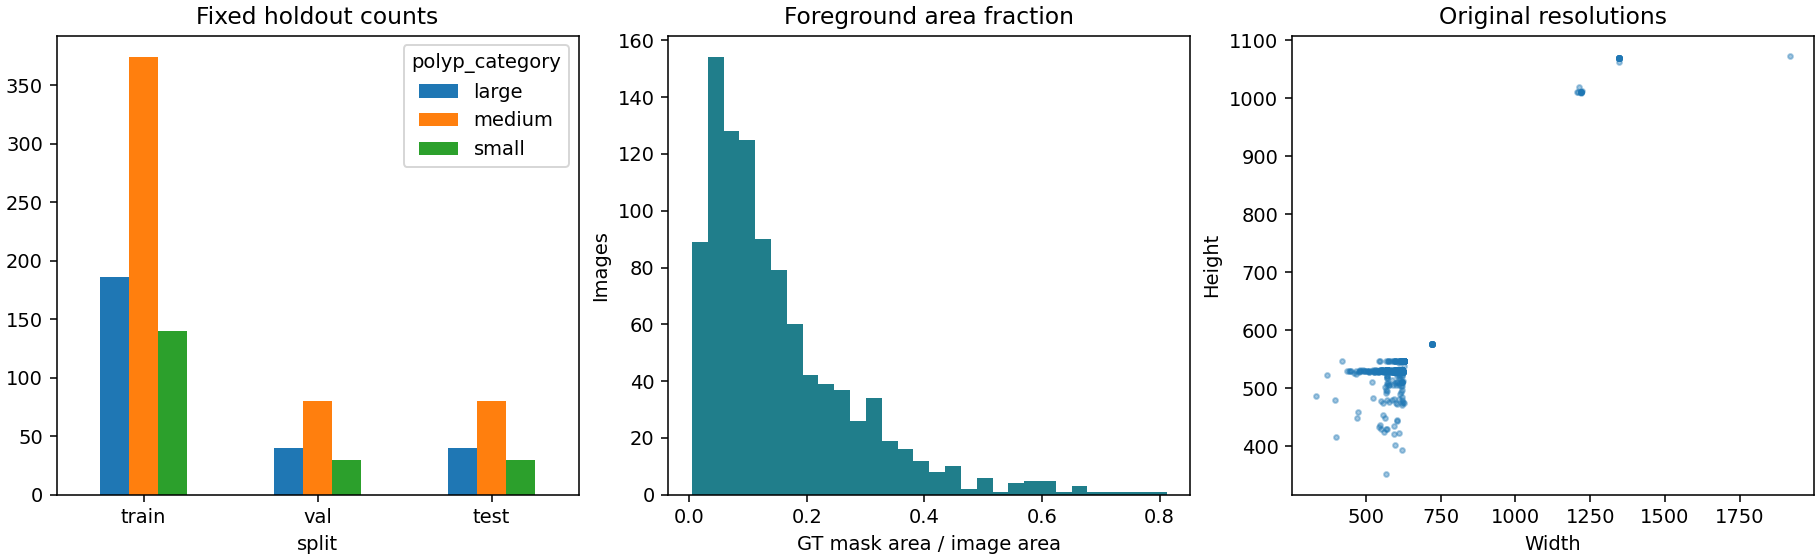

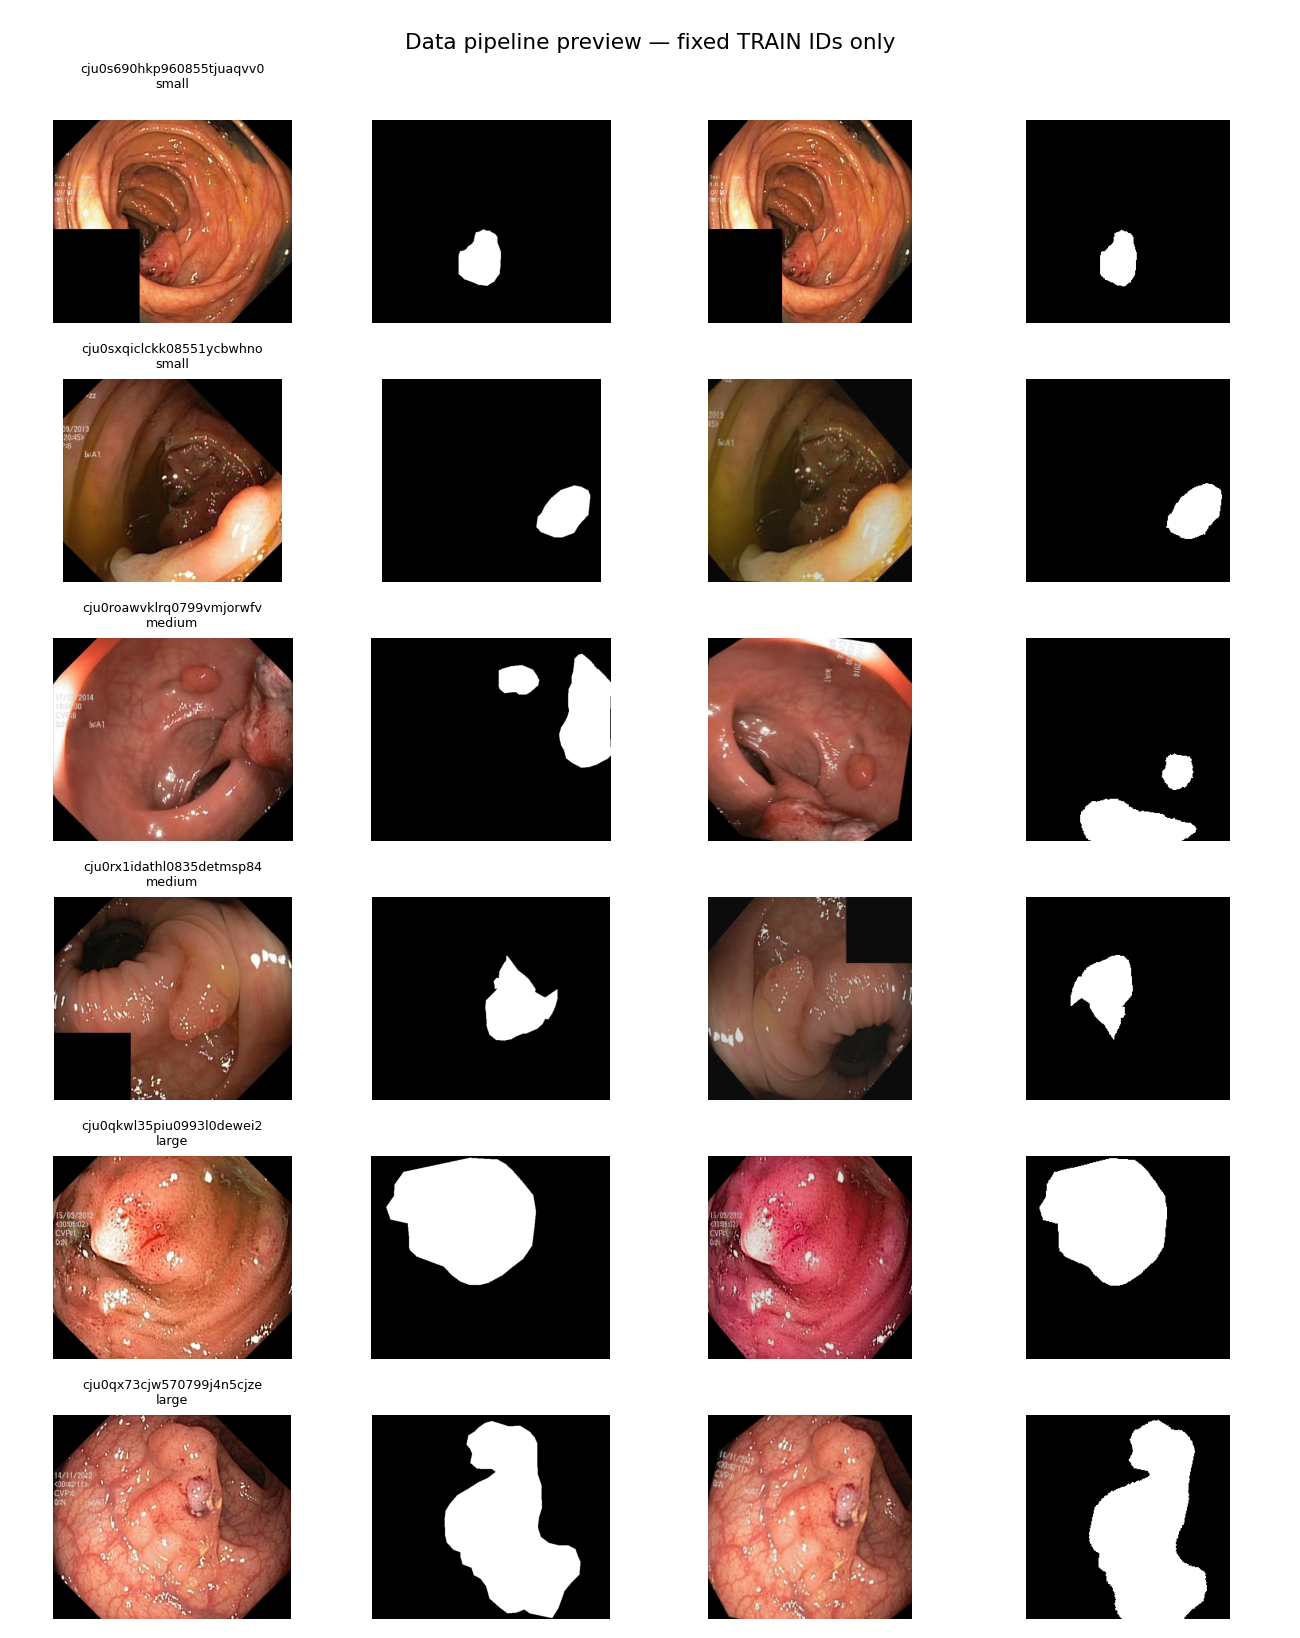

In [11]:
manifest = pd.read_csv(DEFAULT_MANIFEST)
validate_manifest(manifest)
assert manifest.split.value_counts().to_dict() == {'train':700, 'val':150, 'test':150}
audit = audit_dataset(OUTPUT/'data_audit')
assert audit['status'] == 'passed'
display(pd.crosstab(manifest.split, manifest.polyp_category).reindex(SPLITS))
display(DisplayImage(filename=str(OUTPUT/'data_audit/data_overview.png')))
display(DisplayImage(filename=str(OUTPUT/'data_audit/train_augmentation_preview.png'), width=750))

In [12]:
images, targets = next(iter(get_dataloader('train', batch_size=2)))
assert images.shape == (2,3,256,256) and targets.shape == (2,1,256,256)
assert set(torch.unique(targets).tolist()) <= {0.,1.}
print('RGB:', tuple(images.shape), 'mask:', tuple(targets.shape), 'nhãn:', torch.unique(targets).tolist())

RGB: (2, 3, 256, 256) mask: (2, 1, 256, 256) nhãn: [0.0, 1.0]


## 3 Code mô hình của Duy và Phúc

Hai Conv 3×3 + ReLU trong mỗi DoubleConv, same padding, base 32, không BatchNorm. ConvTranspose học tăng độ phân giải và giảm số kênh trước concat.

### 3.1 U-Net A

Nguồn đối chiếu: `members/duy/works_done/unet.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [13]:
class DoubleConv(nn.Sequential):
    """Two 3x3 convolutions preserve H/W while learning local features."""

    def __init__(self, in_channels: int, out_channels: int, batch_norm: bool = False):
        layers: list[nn.Module] = []
        for source in (in_channels, out_channels):
            layers.append(nn.Conv2d(source, out_channels, 3, padding=1, bias=not batch_norm))
            if batch_norm:
                layers.append(nn.BatchNorm2d(out_channels))
            layers.append(nn.ReLU(inplace=True))
        super().__init__(*layers)

In [14]:
class UpBlock(nn.Module):
    """Double resolution, concatenate an encoder skip, refine the result."""

    def __init__(self, in_channels: int, out_channels: int, batch_norm: bool = False):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = DoubleConv(2 * out_channels, out_channels, batch_norm)

    def forward(self, x: Tensor, skip: Tensor) -> Tensor:
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            raise ValueError(f"Skip spatial mismatch: up={tuple(x.shape)}, skip={tuple(skip.shape)}")
        # NCHW: dim=1 joins channels, not different images or spatial positions.
        return self.conv(torch.cat((skip, x), dim=1))

In [15]:
class UNet(nn.Module):
    """Input [B,C,H,W] -> logits [B,out_channels,H,W].

    H/W must be positive multiples of 16, since there are four pooling stages.
    Default: RGB input, one polyp channel, filters 32/64/128/256/512,
    no BatchNorm, no pretrained backbone, no attention and no deep supervision.
    """

    def __init__(
        self,
        in_channels: int = 3,
        out_channels: int = 1,
        base_channels: int = 32,
        batch_norm: bool = False,
    ) -> None:
        super().__init__()
        for name, value in (("in_channels", in_channels), ("out_channels", out_channels),
                            ("base_channels", base_channels)):
            if type(value) is not int or value < 1:
                raise ValueError(f"{name} must be a positive integer; got {value!r}")
        if type(batch_norm) is not bool:
            raise TypeError("batch_norm must be bool")
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.base_channels = base_channels
        self.batch_norm = batch_norm
        b = base_channels
        self.encoder1 = DoubleConv(in_channels, b, batch_norm)
        self.encoder2 = DoubleConv(b, 2 * b, batch_norm)
        self.encoder3 = DoubleConv(2 * b, 4 * b, batch_norm)
        self.encoder4 = DoubleConv(4 * b, 8 * b, batch_norm)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(8 * b, 16 * b, batch_norm)
        self.decoder4 = UpBlock(16 * b, 8 * b, batch_norm)
        self.decoder3 = UpBlock(8 * b, 4 * b, batch_norm)
        self.decoder2 = UpBlock(4 * b, 2 * b, batch_norm)
        self.decoder1 = UpBlock(2 * b, b, batch_norm)
        self.head = nn.Conv2d(b, out_channels, kernel_size=1)

    def forward(self, x: Tensor) -> Tensor:
        if x.ndim != 4:
            raise ValueError(f"Expected NCHW input, got shape {tuple(x.shape)}")
        if x.shape[0] < 1 or x.shape[1] != self.in_channels:
            raise ValueError(f"Expected nonempty batch and {self.in_channels} channels, got {tuple(x.shape)}")
        if not x.is_floating_point():
            raise TypeError("Input must be floating point; normalize RGB uint8 pixels before the model")
        h, w = x.shape[-2:]
        if h < 16 or w < 16 or h % 16 or w % 16:
            raise ValueError(f"H/W must be multiples of 16 and at least 16; got {(h, w)}")
        e1 = self.encoder1(x)
        e2 = self.encoder2(self.pool(e1))
        e3 = self.encoder3(self.pool(e2))
        e4 = self.encoder4(self.pool(e3))
        center = self.bottleneck(self.pool(e4))
        d4 = self.decoder4(center, e4)
        d3 = self.decoder3(d4, e3)
        d2 = self.decoder2(d3, e2)
        d1 = self.decoder1(d2, e1)
        return self.head(d1)  # BCEWithLogitsLoss applies the sigmoid internally.

    def configuration(self) -> dict:
        """Constructor arguments to store with every checkpoint."""
        return {"in_channels": self.in_channels, "out_channels": self.out_channels,
                "base_channels": self.base_channels, "batch_norm": self.batch_norm}

In [16]:
def count_parameters(model: nn.Module, trainable_only: bool = True) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

### 3.2 U-Net++ B và C

Nguồn đối chiếu: `members/phuc/works_done/unetplusplus.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [17]:
class NestedSkipBlock(nn.Module):
    """Upsample the lower node, join all earlier same-level nodes, then refine.

    For X(i,j), there are j previous nodes at level i. The transposed convolution
    projects the lower feature from 2*C(i) channels to C(i). The concatenated
    tensor therefore has (j+1)*C(i) channels. Each node has its own parameters.
    """

    def __init__(
        self, lower_channels: int, node_channels: int, previous_nodes: int,
        batch_norm: bool = False,
    ) -> None:
        super().__init__()
        self.previous_nodes = previous_nodes
        self.up = nn.ConvTranspose2d(lower_channels, node_channels, kernel_size=2, stride=2)
        self.conv = DoubleConv((previous_nodes + 1) * node_channels, node_channels, batch_norm)

    def forward(self, lower: Tensor, *previous: Tensor) -> Tensor:
        if len(previous) != self.previous_nodes:
            raise ValueError(f"Expected {self.previous_nodes} same-level nodes, got {len(previous)}")
        upsampled = self.up(lower)
        if any(node.shape[-2:] != upsampled.shape[-2:] for node in previous):
            raise ValueError("Nested skip nodes must have the same spatial size after upsampling")
        # NCHW: join features along channels, preserving image and pixel axes.
        return self.conv(torch.cat((*previous, upsampled), dim=1))

In [18]:
class UNetPlusPlus(nn.Module):
    """RGB [B,3,H,W] -> logits [B,1,H,W], or a list of four such heads.

    i = depth/resolution level, j = refinement column. j=0 is the encoder.
    Default filters are 32/64/128/256/512. H/W must be multiples of 16.
    With deep_supervision=True, the trainer supervises all four heads; the
    agreed inference policy uses outputs[-1], rather than averaging heads.
    """

    def __init__(
        self,
        in_channels: int = 3,
        out_channels: int = 1,
        base_channels: int = 32,
        batch_norm: bool = False,
        deep_supervision: bool = False,
    ) -> None:
        super().__init__()
        for name, value in (("in_channels", in_channels), ("out_channels", out_channels),
                            ("base_channels", base_channels)):
            if type(value) is not int or value < 1:
                raise ValueError(f"{name} must be a positive integer; got {value!r}")
        for name, value in (("batch_norm", batch_norm), ("deep_supervision", deep_supervision)):
            if type(value) is not bool:
                raise TypeError(f"{name} must be bool")
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.base_channels = base_channels
        self.batch_norm = batch_norm
        self.deep_supervision = deep_supervision
        b = base_channels

        # Column j=0: same five-level encoder as the plain U-Net baseline.
        self.conv0_0 = DoubleConv(in_channels, b, batch_norm)
        self.conv1_0 = DoubleConv(b, 2 * b, batch_norm)
        self.conv2_0 = DoubleConv(2 * b, 4 * b, batch_norm)
        self.conv3_0 = DoubleConv(4 * b, 8 * b, batch_norm)
        self.conv4_0 = DoubleConv(8 * b, 16 * b, batch_norm)
        self.pool = nn.MaxPool2d(2)

        # Column j=1: one earlier node + one upsampled lower node.
        self.conv0_1 = NestedSkipBlock(2 * b, b, 1, batch_norm)
        self.conv1_1 = NestedSkipBlock(4 * b, 2 * b, 1, batch_norm)
        self.conv2_1 = NestedSkipBlock(8 * b, 4 * b, 1, batch_norm)
        self.conv3_1 = NestedSkipBlock(16 * b, 8 * b, 1, batch_norm)

        # Column j=2: two earlier nodes + one upsampled lower node.
        self.conv0_2 = NestedSkipBlock(2 * b, b, 2, batch_norm)
        self.conv1_2 = NestedSkipBlock(4 * b, 2 * b, 2, batch_norm)
        self.conv2_2 = NestedSkipBlock(8 * b, 4 * b, 2, batch_norm)

        # Columns j=3 and j=4 accumulate every earlier same-level feature.
        self.conv0_3 = NestedSkipBlock(2 * b, b, 3, batch_norm)
        self.conv1_3 = NestedSkipBlock(4 * b, 2 * b, 3, batch_norm)
        self.conv0_4 = NestedSkipBlock(2 * b, b, 4, batch_norm)

        # Initialize the final head first in both B and C. With the same seed,
        # their trunk and final head start identically; C only adds auxiliary
        # heads. The public C output order remains shallow -> deep.
        final_head = nn.Conv2d(b, out_channels, kernel_size=1)
        if deep_supervision:
            auxiliary_heads = [nn.Conv2d(b, out_channels, kernel_size=1) for _ in range(3)]
            self.heads = nn.ModuleList([*auxiliary_heads, final_head])
        else:
            self.head = final_head

    def forward(self, x: Tensor) -> Tensor | list[Tensor]:
        if x.ndim != 4:
            raise ValueError(f"Expected NCHW input, got shape {tuple(x.shape)}")
        if x.shape[0] < 1 or x.shape[1] != self.in_channels:
            raise ValueError(f"Expected nonempty batch and {self.in_channels} channels, got {tuple(x.shape)}")
        if not x.is_floating_point():
            raise TypeError("Input must be floating point; normalize RGB uint8 pixels before the model")
        h, w = x.shape[-2:]
        if h < 16 or w < 16 or h % 16 or w % 16:
            raise ValueError(f"H/W must be multiples of 16 and at least 16; got {(h, w)}")

        # Encoder X(i,0): downsample H/W by two for each deeper level.
        x0_0 = self.conv0_0(x)
        x1_0 = self.conv1_0(self.pool(x0_0))
        x2_0 = self.conv2_0(self.pool(x1_0))
        x3_0 = self.conv3_0(self.pool(x2_0))
        x4_0 = self.conv4_0(self.pool(x3_0))

        # X(i,j) = DoubleConv([X(i,0),...,X(i,j-1),Up(X(i+1,j-1))]).
        x0_1 = self.conv0_1(x1_0, x0_0)
        x1_1 = self.conv1_1(x2_0, x1_0)
        x2_1 = self.conv2_1(x3_0, x2_0)
        x3_1 = self.conv3_1(x4_0, x3_0)

        x0_2 = self.conv0_2(x1_1, x0_0, x0_1)
        x1_2 = self.conv1_2(x2_1, x1_0, x1_1)
        x2_2 = self.conv2_2(x3_1, x2_0, x2_1)

        x0_3 = self.conv0_3(x1_2, x0_0, x0_1, x0_2)
        x1_3 = self.conv1_3(x2_2, x1_0, x1_1, x1_2)

        x0_4 = self.conv0_4(x1_3, x0_0, x0_1, x0_2, x0_3)

        if self.deep_supervision:
            return [head(node) for head, node in zip(self.heads, (x0_1, x0_2, x0_3, x0_4))]
        return self.head(x0_4)

    def configuration(self) -> dict:
        """Save these constructor arguments alongside the state_dict."""
        return {"in_channels": self.in_channels, "out_channels": self.out_channels,
                "base_channels": self.base_channels, "batch_norm": self.batch_norm,
                "deep_supervision": self.deep_supervision}

### 3.3 Tạo mô hình ngay trong notebook

Factory dưới đây gọi trực tiếp các class ở trên; file Python gốc dùng import module. Hai cách được kiểm tra tương đương state_dict và đầu ra.

In [19]:
def build_model(name='unet', **kwargs):
    if name == 'unet':
        if kwargs.pop('deep_supervision', False):
            raise ValueError('U-Net không có deep supervision.')
        return UNet(**kwargs)
    if name == 'unetplusplus':
        return UNetPlusPlus(**kwargs)
    raise ValueError('Model phải là unet hoặc unetplusplus.')

CONFIG_FILES = {'A':'unet.json','B':'unetplusplus.json','C':'unetplusplus_ds.json'}
CONFIGS = {k:json.loads((ROOT/'configs'/v).read_text('utf-8')) for k,v in CONFIG_FILES.items()}
from members.duy.works_done.model_factory import build_model as module_build_model
shapes = []
for label, cfg in CONFIGS.items():
    torch.manual_seed(42)
    native = build_model(cfg['model'], **cfg['model_kwargs']).eval()
    torch.manual_seed(42)
    module = module_build_model(cfg['model'], **cfg['model_kwargs']).eval()
    assert native.state_dict().keys() == module.state_dict().keys()
    assert all(torch.equal(v,module.state_dict()[k]) for k,v in native.state_dict().items())
    x = torch.zeros(1,3,256,256)
    with torch.inference_mode():
        out_native, out_module = native(x), module(x)
    left = out_native if isinstance(out_native,list) else [out_native]
    right = out_module if isinstance(out_module,list) else [out_module]
    assert len(left) == (4 if label == 'C' else 1)
    assert all(a.shape == (1,1,256,256) and torch.equal(a,b) for a,b in zip(left,right))
    shapes.append({'model':label,'parameters':count_parameters(native),'heads':len(left),'output':str(tuple(left[-1].shape))})
    del native, module, out_native, out_module, left, right
shapes = pd.DataFrame(shapes)
assert shapes.parameters.tolist() == [7760097,9042177,9042276]
display(shapes)

,model,parameters,heads,output
0,A,7760097,1,"(1, 1, 256, 256)"
1,B,9042177,1,"(1, 1, 256, 256)"
2,C,9042276,4,"(1, 1, 256, 256)"


### 3.4 Tự kiểm tra từng tầng với Bảng 3.7 và 3.8

Forward hook ghi shape thực tế sau mỗi block. Số tham số được đếm từ model đang chạy, không nhập lại bằng tay. C có cùng thân mạng với B, thêm ba head phụ × 33 tham số.

In [20]:
for label in ['A','B']:
    cfg = CONFIGS[label]
    model = build_model(cfg['model'], **cfg['model_kwargs']).eval()
    layer_rows, hooks = [], []
    for name, block in model.named_children():
        if not isinstance(block,(DoubleConv,UpBlock,NestedSkipBlock,nn.Conv2d)):
            continue
        def record_shape(module, args, output, name=name):
            layer_rows.append({'layer':name,'output_NCHW':str(tuple(output.shape)),
                               'parameters':sum(p.numel() for p in module.parameters())})
        hooks.append(block.register_forward_hook(record_shape))
    try:
        with torch.inference_mode(): model(torch.zeros(1,3,256,256))
    finally:
        for hook in hooks: hook.remove()
    layer_table = pd.DataFrame(layer_rows)
    assert layer_table.parameters.sum() == count_parameters(model)
    layer_table.to_csv(OUTPUT/('layers_'+label+'.csv'),index=False)
    print('Các tầng thực tế của mô hình',label)
    display(layer_table)
    del model

Các tầng thực tế của mô hình A


,layer,output_NCHW,parameters
0,encoder1,"(1, 32, 256, 256)",10144
1,encoder2,"(1, 64, 128, 128)",55424
2,encoder3,"(1, 128, 64, 64)",221440
3,encoder4,"(1, 256, 32, 32)",885248
4,bottleneck,"(1, 512, 16, 16)",3539968
5,decoder4,"(1, 256, 32, 32)",2294528
6,decoder3,"(1, 128, 64, 64)",573824
7,decoder2,"(1, 64, 128, 128)",143552
8,decoder1,"(1, 32, 256, 256)",35936
9,head,"(1, 1, 256, 256)",33


Các tầng thực tế của mô hình B


,layer,output_NCHW,parameters
0,conv0_0,"(1, 32, 256, 256)",10144
1,conv1_0,"(1, 64, 128, 128)",55424
2,conv2_0,"(1, 128, 64, 64)",221440
3,conv3_0,"(1, 256, 32, 32)",885248
4,conv4_0,"(1, 512, 16, 16)",3539968
5,conv0_1,"(1, 32, 256, 256)",35936
6,conv1_1,"(1, 64, 128, 128)",143552
7,conv2_1,"(1, 128, 64, 64)",573824
8,conv3_1,"(1, 256, 32, 32)",2294528
9,conv0_2,"(1, 32, 256, 256)",45152


## 4 Loss và chỉ số

Loss = 0,5×BCEWithLogits + 0,5×(1−softDice). C lấy trung bình bốn loss, không cộng để tránh đổi thang đo. Metric tính từng ảnh rồi mới trung bình; loss mềm khác Dice nhị phân sau threshold.

### 4.1 Hàm mất mát của Huy

Nguồn đối chiếu: `members/huy/works_done/losses.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [21]:
class BCESoftDiceLoss(nn.Module):
    """BCEWithLogits + soft Dice; trả một loss cho mỗi ảnh khi cần."""

    def __init__(self, bce_weight=0.5, soft_dice_weight=0.5, smooth=1e-6):
        super().__init__()
        if bce_weight < 0 or soft_dice_weight < 0 or bce_weight + soft_dice_weight <= 0:
            raise ValueError("Loss weights must be nonnegative and have a positive sum")
        if smooth <= 0:
            raise ValueError("Dice smooth must be positive")
        self.bce_weight = float(bce_weight)
        self.soft_dice_weight = float(soft_dice_weight)
        self.smooth = float(smooth)

    def per_image(self, logits: Tensor, targets: Tensor) -> Tensor:
        if logits.shape != targets.shape or logits.ndim != 4 or logits.shape[1] != 1:
            raise ValueError("Logits and targets must share shape [B, 1, H, W]")
        # Tính loss bằng float32 để soft Dice ổn định khi forward dùng AMP.
        logits, targets = logits.float(), targets.float()
        if not torch.isfinite(logits).all() or not torch.isfinite(targets).all():
            raise ValueError("Loss received non-finite logits or targets")
        if not torch.all((targets == 0) | (targets == 1)):
            raise ValueError("Targets must be binary 0/1")
        bce = F.binary_cross_entropy_with_logits(logits, targets, reduction="none")
        bce = bce.flatten(1).mean(1)
        probabilities = logits.sigmoid().flatten(1)
        masks = targets.flatten(1)
        intersection = (probabilities * masks).sum(1)
        soft_dice = (2 * intersection + self.smooth) / (
            probabilities.sum(1) + masks.sum(1) + self.smooth
        )
        return self.bce_weight * bce + self.soft_dice_weight * (1 - soft_dice)

    def forward(self, logits: Tensor, targets: Tensor) -> Tensor:
        return self.per_image(logits, targets).mean()

In [22]:
def deep_supervision_loss(
    output: Tensor | Sequence[Tensor], targets: Tensor, criterion: BCESoftDiceLoss
) -> Tensor:
    """U-Net/U-Net++ thường: một head; deep supervision: trung bình bốn head.

    Trọng số bằng nhau, tổng bằng 1; không cộng bốn loss làm thay đổi thang đo.
    """
    if isinstance(output, Tensor):
        return criterion(output, targets)
    if not isinstance(output, (list, tuple)) or len(output) != 4:
        raise ValueError("Deep supervision must return exactly four logits tensors")
    return torch.stack([criterion(head, targets) for head in output]).mean()

### 4.2 Dice IoU Precision Recall của Trí

Nguồn đối chiếu: `members/tri/works_done/metrics.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [23]:
def last_logits(output: Union[Tensor, List[Tensor]]) -> Tensor:
    """U-Net trả tensor; U-Net++ deep supervision trả các head, chọn head cuối."""
    if isinstance(output, Tensor):
        return output
    if isinstance(output, (list, tuple)) and output and all(isinstance(x, Tensor) for x in output):
        return output[-1]
    raise TypeError("Model output must be a tensor or a non-empty list/tuple of tensors")

In [24]:
def binary_mask_metrics(prediction: Tensor, targets: Tensor) -> Dict[str, Tensor]:
    """Nhận hai mask bool B×1×H×W và trả vector B cho mỗi chỉ số.

    Quy ước: cả hai rỗng => Dice/IoU/precision/recall = 1; dự đoán rỗng
    nhưng GT có polyp => precision = 0; GT rỗng => recall = 1 (không có
    positive nào cần tìm). IoU và Dice vẫn phạt các false positive đó.
    """
    if prediction.shape != targets.shape or prediction.ndim != 4 or prediction.shape[1] != 1:
        raise ValueError("Prediction and target must share shape [B,1,H,W]")
    if prediction.shape[0] == 0 or prediction.numel() == 0:
        raise ValueError("Empty batches/images cannot be evaluated")
    if prediction.dtype != torch.bool or targets.dtype != torch.bool:
        raise TypeError("binary_mask_metrics expects bool tensors")
    if prediction.device != targets.device:
        raise ValueError("Prediction and targets must be on the same device")
    pred = prediction.flatten(1)
    truth = targets.flatten(1)
    tp = (pred & truth).sum(1).to(torch.float64)
    fp = (pred & ~truth).sum(1).to(torch.float64)
    fn = (~pred & truth).sum(1).to(torch.float64)
    pred_area, true_area = tp + fp, tp + fn
    dice_denominator, union = pred_area + true_area, tp + fp + fn
    dice = torch.where(dice_denominator > 0, 2 * tp / dice_denominator.clamp_min(1), 1.0)
    iou = torch.where(union > 0, tp / union.clamp_min(1), 1.0)
    precision = torch.where(pred_area > 0, tp / pred_area.clamp_min(1), (true_area == 0).to(tp.dtype))
    recall = torch.where(true_area > 0, tp / true_area.clamp_min(1), 1.0)
    return {"dice": dice, "iou": iou, "precision": precision, "recall": recall}

In [25]:
def binary_metrics(logits: Tensor, targets: Tensor, threshold: float = 0.5) -> Dict[str, Tensor]:
    """Áp dụng sigmoid đúng một lần; threshold là xác suất, dùng >=.

    Không thêm epsilon vào chỉ số báo cáo: trường hợp rỗng được xử lý rõ ràng.
    targets phải thực sự là mask 0/1, không tự threshold để che lỗi Dataset.
    """
    if not 0.0 < threshold < 1.0:
        raise ValueError("threshold must be strictly between 0 and 1")
    if not logits.is_floating_point() or not targets.is_floating_point():
        raise TypeError("Logits and targets must be floating tensors")
    if not torch.isfinite(logits).all() or not torch.isfinite(targets).all():
        raise ValueError("Non-finite logits or targets cannot be evaluated")
    if not torch.all((targets == 0) | (targets == 1)):
        raise ValueError("Target mask must contain only 0 and 1")
    return binary_mask_metrics(logits.sigmoid() >= threshold, targets.bool())

In [26]:
prediction = torch.tensor([[[[True, True],[False,False]]]])
truth = torch.tensor([[[[True,False],[True,False]]]])
toy = binary_mask_metrics(prediction,truth)
assert toy['dice'].item() == .5 and abs(toy['iou'].item()-1/3) < 1e-12
print('Ví dụ TP=1, FP=1, FN=1:', {k:float(v.item()) for k,v in toy.items()})
test_logits = torch.zeros(1,1,16,16,requires_grad=True)
loss = deep_supervision_loss([test_logits]*4,torch.zeros_like(test_logits),BCESoftDiceLoss())
loss.backward()
assert torch.isfinite(test_logits.grad).all()
print('Loss và backward hữu hạn:', float(loss.detach()))

Ví dụ TP=1, FP=1, FN=1: {'dice': 0.5, 'iou': 0.3333333333333333, 'precision': 0.5, 'recall': 0.5}
Loss và backward hữu hạn: 0.8465735912322998


## 5 Huấn luyện và chọn checkpoint

Trainer chỉ tạo loader train/val. Adam cập nhật trọng số từ train; validation chọn best bằng Dice, nếu bằng nhau ưu tiên loss thấp hơn. Early stopping patience 10; tối đa 50 epoch. Test được dùng sau khi khóa checkpoint. BF16 chỉ dùng khi train GPU; validation FP32.

### 5.1 Cấu hình seed và lưu checkpoint

Nguồn đối chiếu: `members/huy/works_done/run_utils.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [27]:
DEFAULT_CONFIG = {
    "model": "unet",
    "model_kwargs": {"in_channels": 3, "out_channels": 1, "base_channels": 32,
                     "batch_norm": False, "deep_supervision": False},
    "manifest": "members/khanh/works_done/dataset_splits.csv",
    "image_size": [256, 256], "seed": 42, "batch_size": 8, "num_workers": 0,
    "learning_rate": 0.001, "max_epochs": 50, "early_stopping_patience": 10,
    "device": "auto", "amp": True, "amp_dtype": "bfloat16",
    "torch_threads": 4, "augmentation": True,
    "scheduler": "none",
    "loss": {"bce_weight": 0.5, "soft_dice_weight": 0.5, "smooth": 1e-6},
    "evaluation": {"threshold": 0.5, "head_policy": "last",
                   "aggregation": "per_image_then_mean"},
}

In [28]:
def resolve_config(config: dict) -> dict:
    """Bổ sung mặc định và báo lỗi rõ khi cấu hình không thuộc protocol."""
    if not isinstance(config, dict):
        raise TypeError("Config must be a dictionary")
    unknown = set(config) - set(DEFAULT_CONFIG)
    if unknown:
        raise ValueError(f"Unknown config keys: {sorted(unknown)}")
    result = copy.deepcopy(DEFAULT_CONFIG)
    for key, value in config.items():
        if key in {"model_kwargs", "loss", "evaluation"}:
            if not isinstance(value, dict):
                raise TypeError(f"{key} must be an object")
            extra = set(value) - set(DEFAULT_CONFIG[key])
            if extra:
                raise ValueError(f"Unknown {key} keys: {sorted(extra)}")
            result[key].update(copy.deepcopy(value))
        else:
            result[key] = copy.deepcopy(value)
    if result["model"] not in {"unet", "unetplusplus"}:
        raise ValueError("model must be unet or unetplusplus")
    kwargs = result["model_kwargs"]
    if kwargs["in_channels"] != 3 or kwargs["out_channels"] != 1:
        raise ValueError("Kvasir protocol expects RGB input and one polyp output channel")
    if type(kwargs["base_channels"]) is not int or kwargs["base_channels"] < 1:
        raise ValueError("base_channels must be a positive integer")
    for key in ("batch_norm", "deep_supervision"):
        if type(kwargs[key]) is not bool:
            raise TypeError(f"model_kwargs.{key} must be a boolean")
    if result["model"] == "unet" and kwargs["deep_supervision"]:
        raise ValueError("Plain U-Net cannot use deep supervision")
    size = result["image_size"]
    if not isinstance(size, (list, tuple)) or len(size) != 2:
        raise ValueError("image_size must contain [height, width]")
    if any(type(n) is not int or n < 16 or n % 16 for n in size):
        raise ValueError("Height and width must be >=16 and divisible by 16")
    result["image_size"] = list(size)
    for key in ("batch_size", "max_epochs", "early_stopping_patience", "torch_threads"):
        if type(result[key]) is not int or result[key] < 1:
            raise ValueError(f"{key} must be a positive integer")
    if type(result["seed"]) is not int or not 0 <= result["seed"] < 2**32:
        raise ValueError("seed must be an integer in [0, 2**32)")
    if result["num_workers"] != 0:
        raise ValueError("This reproducible course protocol requires num_workers=0")
    for key in ("amp", "augmentation"):
        if type(result[key]) is not bool:
            raise TypeError(f"{key} must be a boolean")
    if result["amp_dtype"] not in {"bfloat16", "float16"}:
        raise ValueError("amp_dtype must be bfloat16 or float16")
    if result["device"] not in {"auto", "cpu", "cuda"}:
        raise ValueError("device must be auto, cpu or cuda")
    if result["scheduler"] != "none":
        raise ValueError("The agreed protocol uses scheduler='none'")
    if not math.isfinite(result["learning_rate"]) or result["learning_rate"] <= 0:
        raise ValueError("learning_rate must be positive and finite")
    weights = result["loss"]
    if any(not math.isfinite(value) for value in weights.values()):
        raise ValueError("Loss values must be finite")
    if min(weights["bce_weight"], weights["soft_dice_weight"]) < 0:
        raise ValueError("Loss weights must be nonnegative")
    if weights["bce_weight"] + weights["soft_dice_weight"] <= 0 or weights["smooth"] <= 0:
        raise ValueError("Loss weight sum and Dice smooth must be positive")
    evaluation = result["evaluation"]
    if not math.isfinite(evaluation["threshold"]) or not 0 < evaluation["threshold"] < 1:
        raise ValueError("Prediction threshold must be in (0, 1)")
    if evaluation["head_policy"] != "last" or evaluation["aggregation"] != "per_image_then_mean":
        raise ValueError("Evaluation uses last head and per_image_then_mean")
    if not isinstance(result["manifest"], str) or not result["manifest"]:
        raise ValueError("manifest must be a nonempty path string")
    return result

In [29]:
def manifest_path(config: dict) -> Path:
    path = Path(config["manifest"])
    return path if path.is_absolute() else PROJECT_ROOT / path

In [30]:
def read_manifest_metadata(path: Path) -> dict:
    """Chỉ đọc CSV: kiểm tra ID/split; không mở bất kỳ ảnh test nào."""
    frame = pd.read_csv(path)
    required = {"image_id", "image_path", "mask_path", "split"}
    if not required.issubset(frame.columns):
        raise ValueError(f"Manifest lacks columns: {sorted(required - set(frame.columns))}")
    if frame[list(required)].isna().any().any():
        raise ValueError("Manifest has missing IDs, paths or split labels")
    if frame["image_id"].duplicated().any():
        raise ValueError("Manifest image IDs must be unique across all splits")
    if frame["image_path"].duplicated().any() or frame["mask_path"].duplicated().any():
        raise ValueError("Manifest image/mask paths must be unique across all splits")
    counts = frame["split"].value_counts().to_dict()
    if set(counts) != {"train", "val", "test"}:
        raise ValueError("Manifest must contain nonempty train, val and test splits")
    return {"manifest_sha256": sha256(path),
            "split_counts": {key: int(value) for key, value in counts.items()}}

In [31]:
def sha256(path: Path) -> str:
    return hashlib.sha256(path.read_bytes()).hexdigest()

In [32]:
def git_value(*args) -> str | None:
    try:
        process = subprocess.run(["git", *args], cwd=PROJECT_ROOT, capture_output=True,
                                 text=True, encoding="utf-8", check=True)
        return process.stdout.strip()
    except (OSError, subprocess.CalledProcessError):
        return None

In [33]:
def collect_provenance(device: torch.device) -> dict:
    names = [
        "members/khanh/works_done/dataset.py",
        "members/duy/works_done/unet.py", "members/duy/works_done/model_factory.py",
        "members/phuc/works_done/unetplusplus.py",
        "members/huy/works_done/losses.py", "members/huy/works_done/training.py",
        "members/huy/works_done/run_utils.py", "members/tri/works_done/metrics.py",
    ]
    source_hashes = {name: sha256(PROJECT_ROOT / name)
                     for name in names if (PROJECT_ROOT / name).is_file()}
    environment = {"python": sys.version, "platform": platform.platform(),
                   "torch": str(torch.__version__), "numpy": np.__version__,
                   "device": str(device), "cuda_build": torch.version.cuda,
                   "cuda_available": torch.cuda.is_available(),
                   "deterministic_algorithms": torch.are_deterministic_algorithms_enabled(),
                   "torch_threads": torch.get_num_threads()}
    if device.type == "cuda":
        environment["gpu"] = torch.cuda.get_device_name(device)
        environment["gpu_total_memory_bytes"] = torch.cuda.get_device_properties(device).total_memory
    return {"created_utc": datetime.now(timezone.utc).isoformat(),
            "source_commit": git_value("rev-parse", "HEAD"),
            "branch": git_value("branch", "--show-current"),
            "dirty": bool(git_value("status", "--porcelain")),
            "source_hashes": source_hashes, "environment": environment}

In [34]:
def configure_reproducibility(seed: int, threads: int) -> None:
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

In [35]:
def choose_device(requested: str) -> torch.device:
    if requested == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA requested but unavailable; install GPU PyTorch or use --device cpu")
    return torch.device("cuda" if requested != "cpu" and torch.cuda.is_available() else "cpu")

In [36]:
def training_autocast_dtype(config: dict, device: torch.device) -> torch.dtype:
    """BF16 có miền giá trị rộng hơn FP16; báo lỗi nếu GPU không hỗ trợ.

    CPU luôn train FP32 vì trainer chỉ bật AMP trên CUDA. FP16 được giữ
    cho thí nghiệm cũ; ba cấu hình chính thức v2 đều khai báo bfloat16.
    """
    dtype = torch.bfloat16 if config["amp_dtype"] == "bfloat16" else torch.float16
    if config["amp"] and device.type == "cuda" and dtype == torch.bfloat16:
        if not torch.cuda.is_bf16_supported():
            raise RuntimeError("BF16 AMP requested but this CUDA GPU does not support BF16")
    return dtype

In [37]:
def capture_rng_state() -> dict:
    numpy_state = np.random.get_state()
    return {
        "python": random.getstate(),
        "numpy": {"algorithm": numpy_state[0], "keys": numpy_state[1].tolist(),
                  "position": numpy_state[2], "has_gauss": numpy_state[3],
                  "cached_gaussian": numpy_state[4]},
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_initialized() else [],
    }

In [38]:
def restore_rng_state(state: dict) -> None:
    random.setstate(state["python"])
    numpy_state = state["numpy"]
    np.random.set_state((numpy_state["algorithm"], np.asarray(numpy_state["keys"], dtype=np.uint32),
                         numpy_state["position"], numpy_state["has_gauss"],
                         numpy_state["cached_gaussian"]))
    torch.set_rng_state(state["torch"].cpu())
    if state["cuda"] and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([value.cpu() for value in state["cuda"]])

In [39]:
def atomic_json(path: Path, value: dict) -> None:
    temporary = path.with_name(path.name + ".tmp")
    temporary.write_text(json.dumps(value, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    os.replace(temporary, path)

In [40]:
def atomic_checkpoint(path: Path, value: dict) -> None:
    temporary = path.with_name(path.name + ".tmp")
    torch.save(value, temporary)
    os.replace(temporary, path)

### 5.2 Vòng lặp huấn luyện đầy đủ

Nguồn đối chiếu: `members/huy/works_done/training.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [41]:
HISTORY_COLUMNS = [
    "epoch", "train_loss", "val_loss", "val_dice", "val_iou", "val_precision",
    "val_recall", "learning_rate", "epoch_seconds", "peak_gpu_memory_bytes",
    "amp_skipped_steps", "is_best", "patience_count",
]

In [42]:
def _write_history(path: Path, rows: list[dict]) -> None:
    temporary = path.with_name(path.name + ".tmp")
    with temporary.open("w", encoding="utf-8", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=HISTORY_COLUMNS)
        writer.writeheader()
        writer.writerows(rows)
    os.replace(temporary, path)

In [43]:
def _prepare_epoch(loader, seed: int, epoch: int) -> None:
    # Cùng seed+epoch => cùng thứ tự ảnh và chuỗi augmentation giữa A/B/C.
    loader.dataset.set_epoch(epoch)
    if loader.generator is None:
        raise RuntimeError("Data loader must have its own seeded torch.Generator")
    loader.generator.manual_seed((seed + epoch) % 2**32)

In [44]:
def _train_epoch(model, loader, optimizer, scaler, criterion, device, amp: bool,
                 amp_dtype: torch.dtype = torch.bfloat16) -> dict:
    model.train()
    total_loss, images_seen, skipped_steps = 0.0, 0, 0
    for batch in loader:
        images, masks = batch[:2]
        images = images.to(device, non_blocking=device.type == "cuda")
        masks = masks.to(device, non_blocking=device.type == "cuda")
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=amp):
            output = model(images)
            loss = deep_supervision_loss(output, masks, criterion)
        if not math.isfinite(loss.item()):
            raise FloatingPointError("Training loss is non-finite; stop before saving an invalid run")
        scale_before = scaler.get_scale()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        skipped_steps += int(scaler.get_scale() < scale_before)
        batch_size = images.shape[0]
        total_loss += loss.item() * batch_size
        images_seen += batch_size
    if images_seen != len(loader.dataset):
        raise RuntimeError("Training did not visit every train image exactly once")
    return {"loss": total_loss / images_seen, "amp_skipped_steps": skipped_steps}

In [45]:
@torch.inference_mode()
def _validate_epoch(model, loader, criterion, device, amp: bool, threshold: float) -> dict:
    model.eval()
    totals = {"loss": 0.0, "dice": 0.0, "iou": 0.0, "precision": 0.0, "recall": 0.0}
    images_seen = 0
    for batch in loader:
        images, masks = batch[:2]
        images = images.to(device, non_blocking=device.type == "cuda")
        masks = masks.to(device, non_blocking=device.type == "cuda")
        # Validation dùng FP32 như evaluator cuối: cùng precision khi chọn
        # best checkpoint và báo điểm. AMP chỉ tăng tốc forward/backward train.
        logits = last_logits(model(images))
        # Validation luôn cùng objective một head cuối cho cả ba mô hình.
        totals["loss"] += criterion.per_image(logits, masks).double().sum().item()
        metrics = binary_metrics(logits, masks, threshold=threshold)
        for name in ("dice", "iou", "precision", "recall"):
            totals[name] += metrics[name].sum().item()
        images_seen += images.shape[0]
    if images_seen != len(loader.dataset):
        raise RuntimeError("Validation did not visit every validation image exactly once")
    result = {name: value / images_seen for name, value in totals.items()}
    if any(not math.isfinite(value) for value in result.values()):
        raise FloatingPointError("Validation produced non-finite loss or metrics")
    return result

In [46]:
def _check_resume(checkpoint: dict, config: dict, metadata: dict, provenance: dict) -> None:
    if checkpoint.get("format_version") != 1:
        raise ValueError("Unsupported checkpoint format")
    old_config = checkpoint["config"]
    changed = [key for key in config if key not in {"max_epochs", "device"}
               and config[key] != old_config.get(key)]
    if changed:
        raise ValueError(f"Resume changes the experimental protocol: {changed}")
    if checkpoint["manifest_sha256"] != metadata["manifest_sha256"]:
        raise ValueError("Resume manifest SHA256 differs from the original split")
    if checkpoint["provenance"]["source_hashes"] != provenance["source_hashes"]:
        raise ValueError("Resume execution source changed; use a new output directory for a new run")
    if config["max_epochs"] < checkpoint["epoch"]:
        raise ValueError("max_epochs cannot be smaller than the completed checkpoint epoch")
    if checkpoint["patience_count"] >= config["early_stopping_patience"]:
        raise ValueError("This run already reached early stopping; start a new run instead of resuming it")

In [47]:
def _check_resume_destination(checkpoint: dict, resume: Path, output_dir: Path) -> Path | None:
    """Không lùi epoch rồi ghi đè lịch sử; fork phải giữ đúng best của nguồn."""
    if output_dir == resume.parent:
        last_path = output_dir / "last.pt"
        if not last_path.is_file():
            raise FileNotFoundError("An existing run needs last.pt before in-place resume")
        current_last = torch.load(last_path, map_location="cpu", weights_only=True)
        if checkpoint["epoch"] != current_last["epoch"]:
            raise ValueError("Cannot rewind an existing run; resume its last.pt or choose a new output directory")
        return None
    if output_dir.exists():
        raise FileExistsError("A separate resumed output directory must be new")
    best_path = resume.parent / "best.pt"
    if not best_path.is_file():
        raise FileNotFoundError("Resume needs the original best.pt next to its checkpoint")
    previous_best = torch.load(best_path, map_location="cpu", weights_only=True)
    if previous_best["epoch"] != checkpoint["best"]["epoch"] or previous_best["best"] != checkpoint["best"]:
        raise ValueError("Source best.pt differs from the best recorded in the resume checkpoint")
    for key in ("model_name", "model_kwargs", "manifest_sha256", "split_counts"):
        if previous_best[key] != checkpoint[key]:
            raise ValueError(f"Source best.pt differs from resume checkpoint in {key}")
    for key, value in checkpoint["config"].items():
        if key not in {"max_epochs", "device"} and previous_best["config"].get(key) != value:
            raise ValueError(f"Source best.pt uses a different experimental config: {key}")
    if previous_best["provenance"]["source_hashes"] != checkpoint["provenance"]["source_hashes"]:
        raise ValueError("Source best.pt uses different execution code")
    return best_path

In [48]:
def train_experiment(config: dict, output_dir: Path | str,
                     resume: Path | str | None = None) -> dict:
    """Chạy hoặc tiếp tục một thí nghiệm; trả nội dung summary.json.

    Resume cho phép đổi max_epochs và device. Cùng phần cứng, môi trường và
    protocol mới có thể kiểm tra tái lập từng trọng số; đổi CPU/GPU không đảm bảo
    kết quả bit-for-bit. Không cho đổi split, model, LR, loss hay augmentation.
    """
    config = resolve_config(config)
    configure_reproducibility(config["seed"], config["torch_threads"])
    device = choose_device(config["device"])
    amp = config["amp"] and device.type == "cuda"
    amp_dtype = training_autocast_dtype(config, device)
    training_precision = f"amp_{config['amp_dtype']}" if amp else "float32"
    # BF16 không cần loss scaling; giữ GradScaler cho protocol FP16 cũ.
    use_grad_scaler = amp and amp_dtype == torch.float16
    metadata = read_manifest_metadata(manifest_path(config))
    provenance = collect_provenance(device)
    provenance["environment"]["training_precision"] = training_precision
    provenance["environment"]["grad_scaler_enabled"] = use_grad_scaler
    output_dir = Path(output_dir).resolve()
    checkpoint, previous_best_path = None, None
    if resume is None:
        if output_dir.exists():
            raise FileExistsError(f"Output already exists: {output_dir}; choose a new run name or --resume")
    else:
        resume = Path(resume).resolve()
        checkpoint = torch.load(resume, map_location="cpu", weights_only=True)
        _check_resume(checkpoint, config, metadata, provenance)
        previous_best_path = _check_resume_destination(checkpoint, resume, output_dir)
        if output_dir != resume.parent and config["max_epochs"] == checkpoint["epoch"]:
            raise ValueError("Resume into a new directory requires at least one additional epoch")
    output_dir.mkdir(parents=True, exist_ok=True)

    loader_kwargs = {
        "csv_path": str(manifest_path(config)), "project_root": str(PROJECT_ROOT),
        "batch_size": config["batch_size"], "num_workers": config["num_workers"],
        "img_size": tuple(config["image_size"]), "seed": config["seed"],
        "return_id": False, "pin_memory": device.type == "cuda",
    }
    train_loader = get_dataloader("train", augment=config["augmentation"],
                                  shuffle=True, **loader_kwargs)
    val_loader = get_dataloader("val", augment=False, shuffle=False, **loader_kwargs)
    model = build_model(config["model"], **config["model_kwargs"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    criterion = BCESoftDiceLoss(**config["loss"])
    scaler = torch.amp.GradScaler(device.type, enabled=use_grad_scaler)
    history = []
    best = {"epoch": 0, "val_dice": -1.0, "val_iou": 0.0, "val_loss": None}
    patience_count, start_epoch = 0, 1
    if checkpoint is not None:
        model.load_state_dict(checkpoint["model_state"], strict=True)
        optimizer.load_state_dict(checkpoint["optimizer_state"])
        if use_grad_scaler and checkpoint["scaler_state"]:
            scaler.load_state_dict(checkpoint["scaler_state"])
        history = checkpoint["history"]
        best, patience_count = checkpoint["best"], checkpoint["patience_count"]
        start_epoch = checkpoint["epoch"] + 1
        restore_rng_state(checkpoint["rng_state"])
        if previous_best_path is not None:
            shutil.copy2(previous_best_path, output_dir / "best.pt")
    parameter_count = sum(parameter.numel() for parameter in model.parameters())
    atomic_json(output_dir / "resolved_config.json", config)
    atomic_json(output_dir / "environment.json", provenance)
    print(f"Model={config['model']} | device={device} | train={training_precision} | "
          f"parameters={parameter_count:,}", flush=True)
    print(f"Train={len(train_loader.dataset)} | val={len(val_loader.dataset)} | test images read=0", flush=True)

    status = "completed"
    for epoch in range(start_epoch, config["max_epochs"] + 1):
        _prepare_epoch(train_loader, config["seed"], epoch)
        _prepare_epoch(val_loader, config["seed"], epoch)
        if device.type == "cuda":
            torch.cuda.synchronize(device)
            torch.cuda.reset_peak_memory_stats(device)
        started = time.perf_counter()
        train = _train_epoch(model, train_loader, optimizer, scaler, criterion,
                             device, amp, amp_dtype)
        validation = _validate_epoch(model, val_loader, criterion, device, amp,
                                     config["evaluation"]["threshold"])
        if device.type == "cuda":
            torch.cuda.synchronize(device)
        seconds = time.perf_counter() - started
        is_best = validation["dice"] > best["val_dice"] or (
            validation["dice"] == best["val_dice"] and
            (best["val_loss"] is None or validation["loss"] < best["val_loss"])
        )
        if is_best:
            best = {"epoch": epoch, "val_dice": validation["dice"],
                    "val_iou": validation["iou"], "val_loss": validation["loss"]}
            patience_count = 0
        else:
            patience_count += 1
        stop = patience_count >= config["early_stopping_patience"]
        final_epoch = stop or epoch == config["max_epochs"]
        epoch_status = "early_stopped" if stop else ("completed" if final_epoch else "training")
        row = {
            "epoch": epoch, "train_loss": train["loss"], "val_loss": validation["loss"],
            "val_dice": validation["dice"], "val_iou": validation["iou"],
            "val_precision": validation["precision"], "val_recall": validation["recall"],
            "learning_rate": optimizer.param_groups[0]["lr"], "epoch_seconds": seconds,
            "peak_gpu_memory_bytes": torch.cuda.max_memory_allocated(device) if device.type == "cuda" else None,
            "amp_skipped_steps": train["amp_skipped_steps"], "is_best": is_best,
            "patience_count": patience_count,
        }
        history.append(row)
        saved = {
            "format_version": 1, "model_name": config["model"],
            "model_kwargs": config["model_kwargs"], "model_state": model.state_dict(),
            "config": config, "optimizer_state": optimizer.state_dict(),
            "scaler_state": scaler.state_dict(), "epoch": epoch, "best": best,
            "patience_count": patience_count, "history": history,
            "rng_state": capture_rng_state(), **metadata,
            "preprocessing": {"image_size": config["image_size"], "normalization": "rgb_float_0_1",
                              "mask": "binary_0_1"},
            "provenance": provenance, "status": epoch_status,
            "validation_precision": "float32",
            "training_precision": training_precision,
            "grad_scaler_enabled": use_grad_scaler,
        }
        atomic_checkpoint(output_dir / "last.pt", saved)
        if is_best:
            atomic_checkpoint(output_dir / "best.pt", saved)
        _write_history(output_dir / "history.csv", history)
        summary = {
            "status": epoch_status, "model_name": config["model"], "config": config,
            "device": str(device), "amp_effective": amp, "parameter_count": parameter_count,
            "training_precision": training_precision,
            "grad_scaler_enabled": use_grad_scaler,
            "validation_precision": "float32",
            "epochs_completed": epoch, "best": best, **metadata,
            "train_images": len(train_loader.dataset), "validation_images": len(val_loader.dataset),
            "test_images_read": 0, "history_csv": "history.csv", "best_checkpoint": "best.pt",
            "last_checkpoint": "last.pt", "training_and_validation_seconds": sum(item["epoch_seconds"] for item in history),
            "provenance": provenance,
        }
        atomic_json(output_dir / "summary.json", summary)
        print(f"Epoch {epoch:03d}/{config['max_epochs']} | train loss={train['loss']:.5f} | "
              f"val loss={validation['loss']:.5f} | Dice={validation['dice']:.5f} | "
              f"IoU={validation['iou']:.5f} | {seconds:.1f}s | best={is_best} | "
              f"patience={patience_count}/{config['early_stopping_patience']}", flush=True)
        if stop:
            status = "early_stopped"
            break
    # max_epochs bằng epoch đã hoàn thành: đọc lại summary/checkpoint hiện có.
    if not history:
        raise RuntimeError("No training epochs completed")
    if start_epoch > config["max_epochs"]:
        import json
        summary_path = output_dir / "summary.json"
        if summary_path.exists():
            return json.loads(summary_path.read_text(encoding="utf-8"))
        raise ValueError("Resume into a new directory requires at least one additional epoch")
    return summary

In [49]:
# Ghi rõ phần triển khai bằng notebook trong provenance của lượt mới.
module_collect_provenance = collect_provenance
notebook_path = ROOT/'notebooks/DoAn_Nhom06_DayDu.ipynb'
notebook_json = json.loads(notebook_path.read_text('utf-8'))
notebook_code_sha = hashlib.sha256('\n'.join(''.join(c['source']) for c in notebook_json['cells'] if c['cell_type']=='code').encode()).hexdigest()
def collect_provenance(device):
    result = module_collect_provenance(device)
    result['execution'] = {'kind':'notebook definitions', 'notebook_code_sha256':notebook_code_sha,
                           'factory_adapter':'direct local classes; parity checked against module factory'}
    return result

OFFICIAL_RUNS = {'A':'A_unet_seed42','B':'B_unetplusplus_seed42','C':'C_unetplusplus_ds_seed42'}
run_paths, training_summaries = {}, {}
print('Chế độ:', 'HUẤN LUYỆN / ĐỌC LƯỢT ĐÃ HOÀN TẤT' if TRAIN_FROM_SCRATCH else 'DÙNG CHECKPOINT BÁO CÁO')
for label in ['A','B','C']:
    cfg = copy.deepcopy(CONFIGS[label])
    cfg['device'] = DEVICE
    if TRAIN_FROM_SCRATCH:
        existing = ROOT/'runs'/REUSE_COMPLETED_RUN/label if REUSE_COMPLETED_RUN else None
        if existing is not None and (existing/'summary.json').is_file():
            saved = json.loads((existing/'summary.json').read_text('utf-8'))
            assert saved['status'] in ['completed','early_stopped']
            assert saved['config'] == resolve_config(cfg), 'Lượt đọc lại phải cùng cấu hình.'
            assert (existing/'best.pt').is_file()
            run_path = existing
            training_summaries[label] = saved
            print(label, ': ĐỌC LẠI lượt huấn luyện đã hoàn tất, không train thêm.')
            display(pd.read_csv(existing/'history.csv').iloc[[0,-1]])
        else:
            run_path = RUN_ROOT/label
            training_summaries[label] = train_experiment(cfg, run_path)
    else:
        run_path = ROOT/'runs'/OFFICIAL_RUNS[label]
        if not (run_path/'best.pt').is_file():
            raise FileNotFoundError('Chạy scripts/prepare_project.py để tải checkpoint báo cáo.')
        training_summaries[label] = json.loads((run_path/'summary.json').read_text('utf-8'))
    run_paths[label] = run_path
    assert training_summaries[label]['test_images_read'] == 0
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
display(pd.DataFrame([{'model':k,'epochs':v['epochs_completed'],**v['best']} for k,v in training_summaries.items()]))

Chế độ: HUẤN LUYỆN / ĐỌC LƯỢT ĐÃ HOÀN TẤT
A : ĐỌC LẠI lượt huấn luyện đã hoàn tất, không train thêm.


,epoch,train_loss,val_loss,val_dice,val_iou,val_precision,val_recall,learning_rate,epoch_seconds,peak_gpu_memory_bytes,amp_skipped_steps,is_best,patience_count
0,1,0.590769,0.548198,0.000000,0.000000,0.000000,0.000000,0.001,11.437427,1269897216,0,True,0
49,50,0.395859,0.353320,0.633739,0.520297,0.711655,0.669207,0.001,9.223373,1269897216,0,True,0


B : ĐỌC LẠI lượt huấn luyện đã hoàn tất, không train thêm.


,epoch,train_loss,val_loss,val_dice,val_iou,val_precision,val_recall,learning_rate,epoch_seconds,peak_gpu_memory_bytes,amp_skipped_steps,is_best,patience_count
0,1,0.592716,0.546273,0.000000,0.000000,0.000000,0.000000,0.001,17.737435,2917361664,0,True,0
49,50,0.338323,0.297543,0.703986,0.579429,0.775785,0.723557,0.001,18.728901,2917361664,0,False,1


C : ĐỌC LẠI lượt huấn luyện đã hoàn tất, không train thêm.


,epoch,train_loss,val_loss,val_dice,val_iou,val_precision,val_recall,learning_rate,epoch_seconds,peak_gpu_memory_bytes,amp_skipped_steps,is_best,patience_count
0,1,0.591005,0.562692,0.000000,0.000000,0.000000,0.000000,0.001,18.849396,2915670016,0,True,0
49,50,0.366144,0.226423,0.782833,0.678344,0.784351,0.855291,0.001,18.662492,2915801088,0,False,2


,model,epochs,epoch,val_dice,val_iou,val_loss
0,A,50,50,0.633739,0.520297,0.353320
1,B,50,49,0.711618,0.585918,0.287498
2,C,50,48,0.788822,0.684537,0.219408


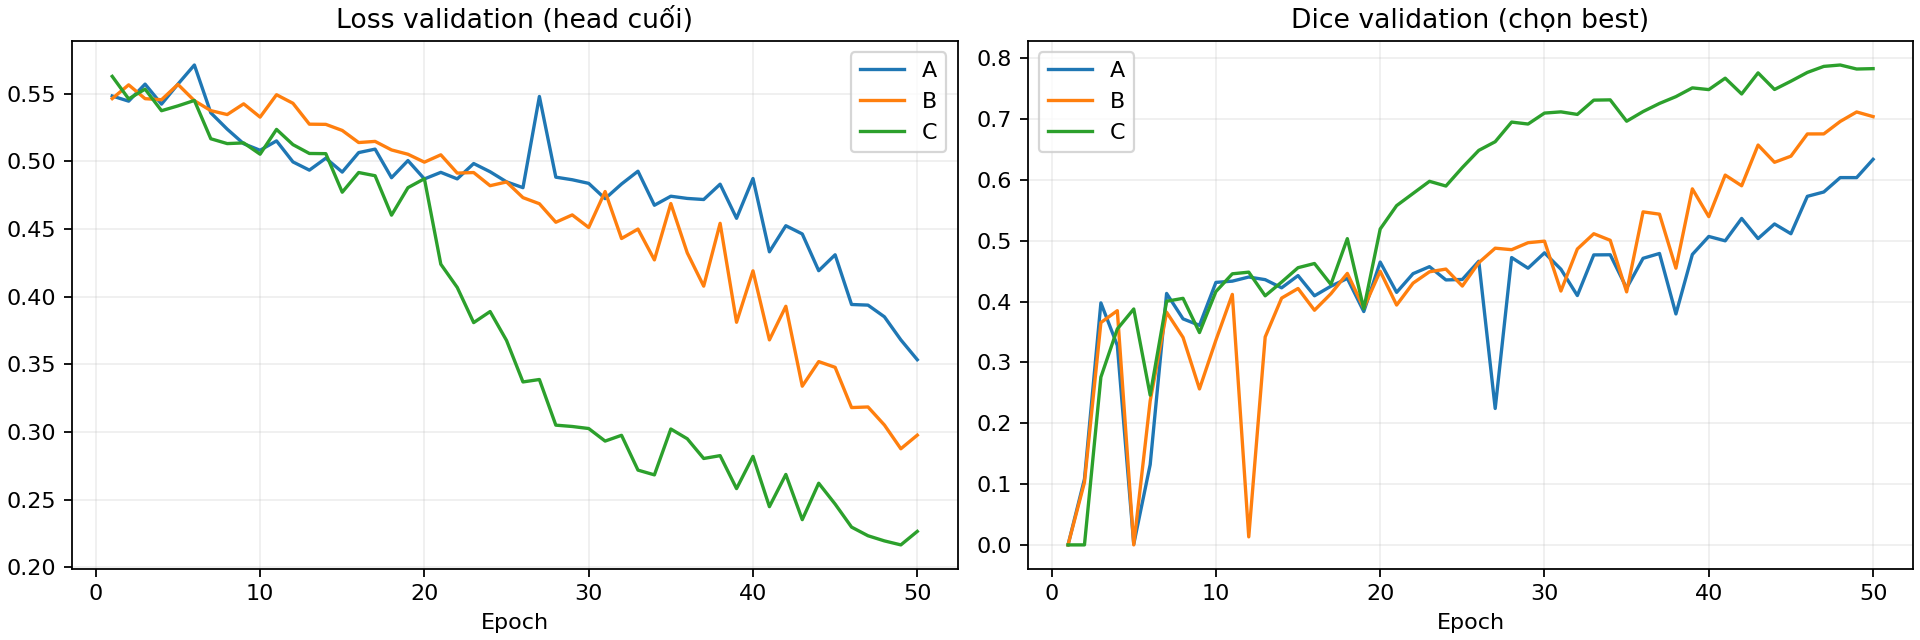

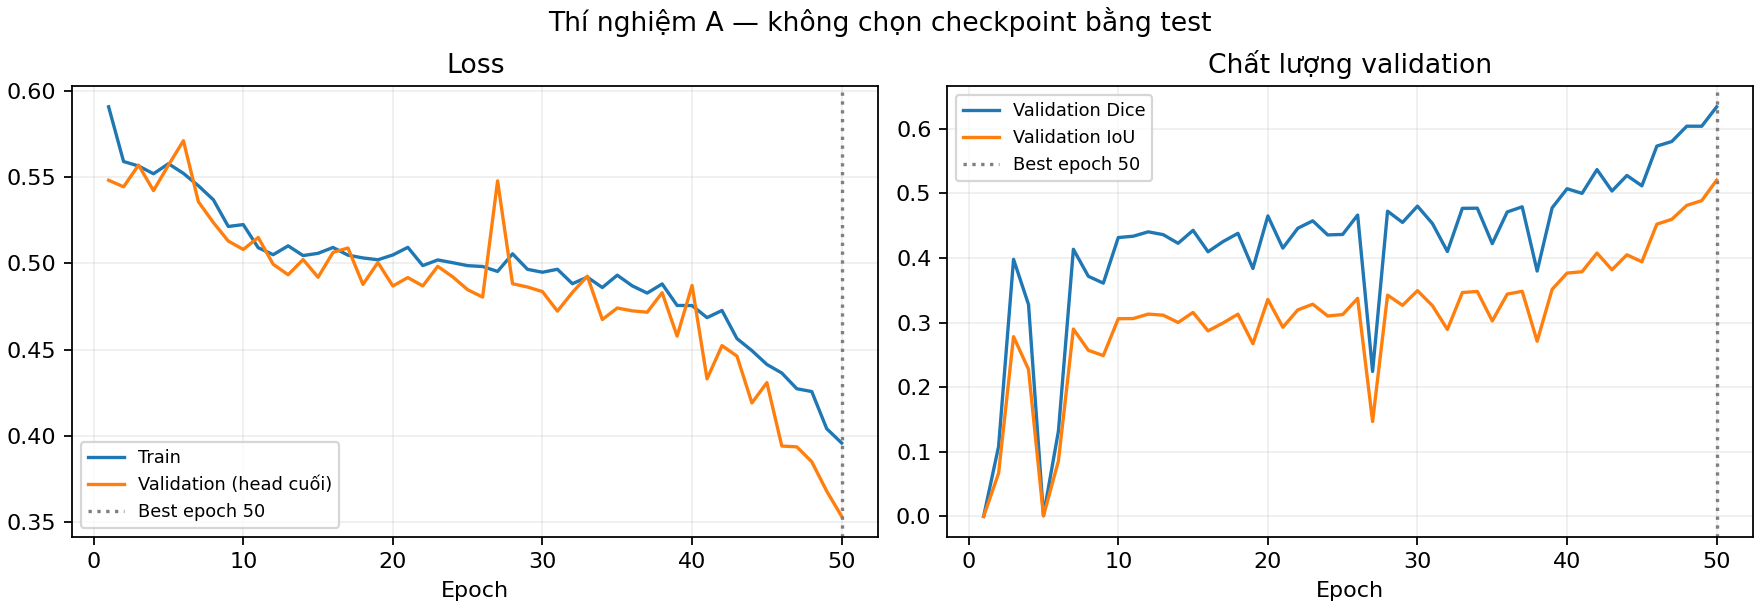

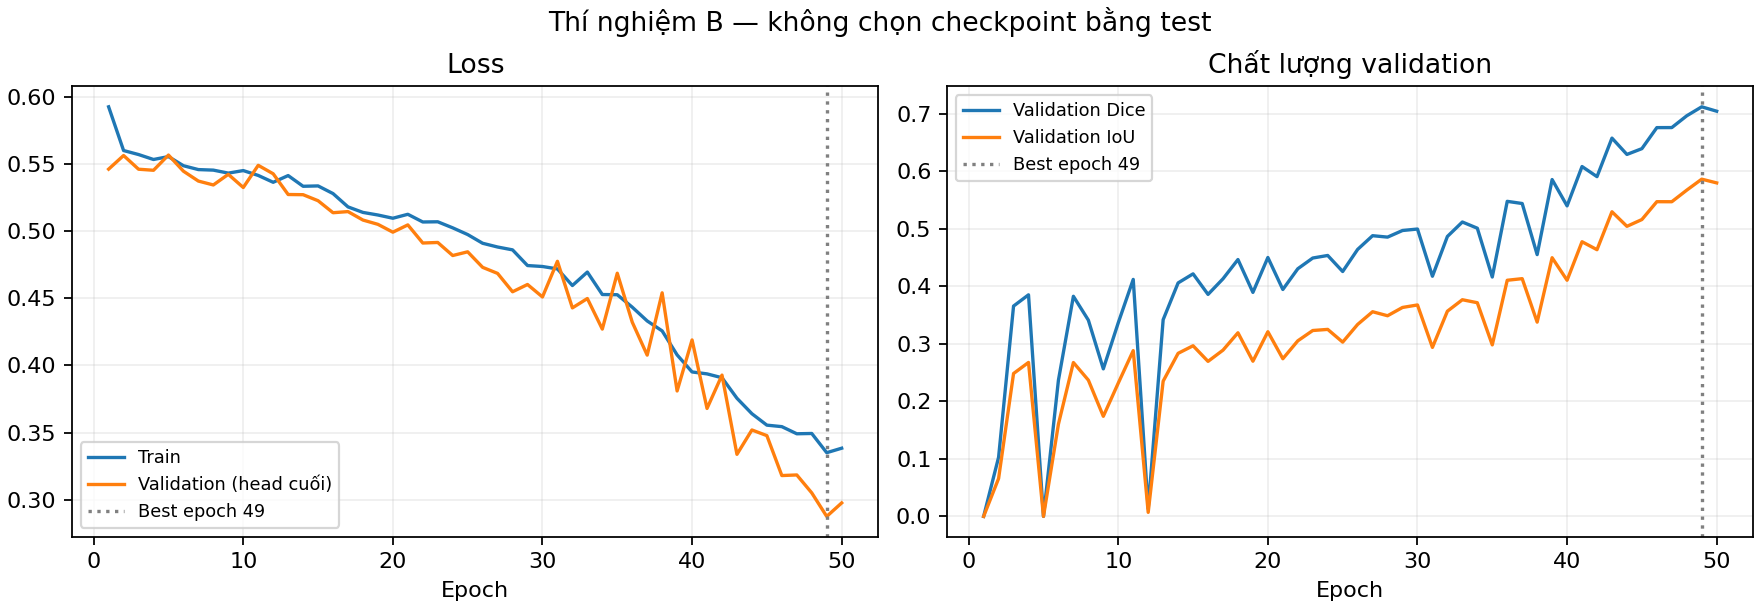

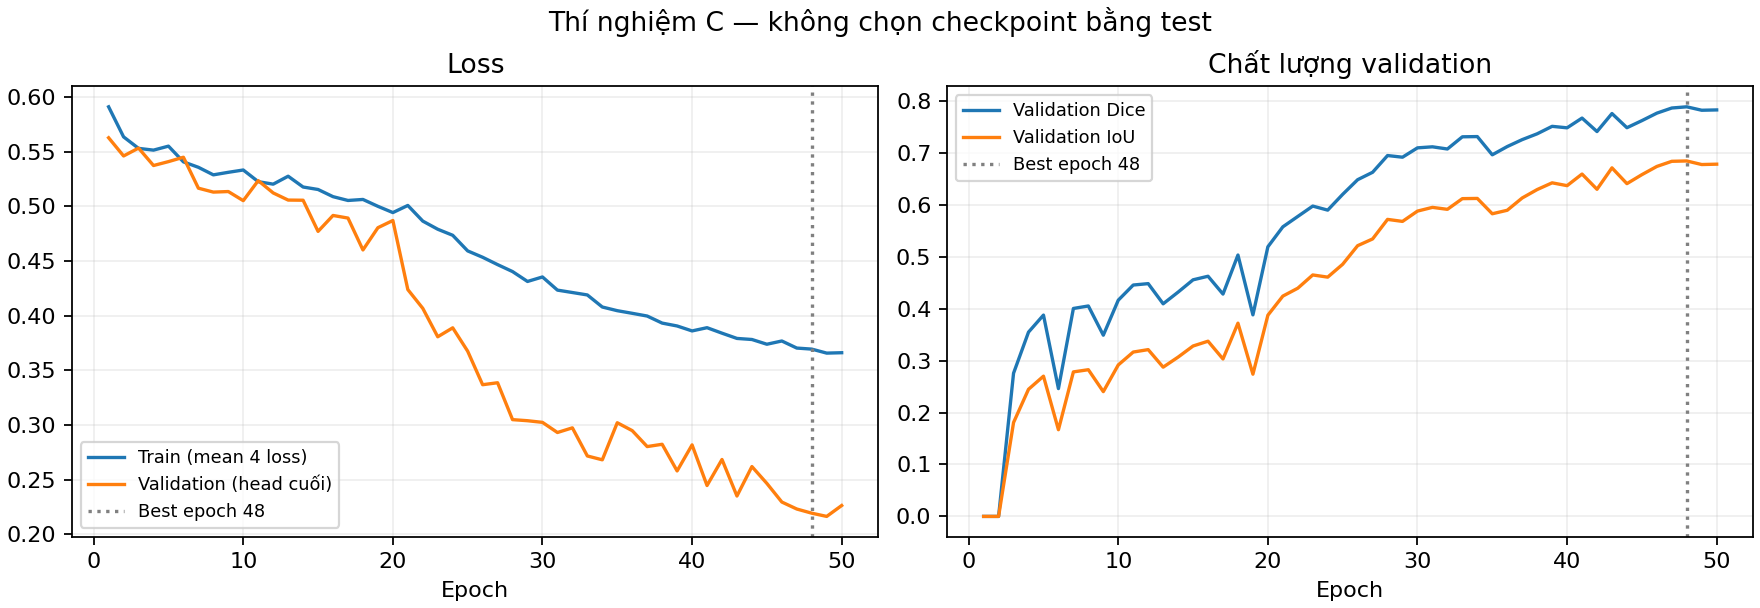

Ở C, train loss là mean 4 head, val loss là head cuối; không suy overfit từ khoảng cách hai đường.


In [50]:
fig, axes = plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for label, run_path in run_paths.items():
    history = pd.read_csv(run_path/'history.csv')
    axes[0].plot(history.epoch,history.val_loss,label=label)
    axes[1].plot(history.epoch,history.val_dice,label=label)
for ax,title in zip(axes,['Loss validation (head cuối)','Dice validation (chọn best)']):
    ax.set(xlabel='Epoch',title=title);ax.grid(alpha=.2);ax.legend()
fig.savefig(OUTPUT/'training_curves.png',dpi=160)
display(DisplayImage(filename=str(OUTPUT/'training_curves.png')));plt.close(fig)
for label, run_path in run_paths.items():
    history = pd.read_csv(run_path/'history.csv')
    best_epoch = training_summaries[label]['best']['epoch']
    fig, axes = plt.subplots(1,2,figsize=(11,3.8),constrained_layout=True)
    train_name = 'Train (mean 4 loss)' if label=='C' else 'Train'
    axes[0].plot(history.epoch,history.train_loss,label=train_name)
    axes[0].plot(history.epoch,history.val_loss,label='Validation (head cuối)')
    axes[1].plot(history.epoch,history.val_dice,label='Validation Dice')
    axes[1].plot(history.epoch,history.val_iou,label='Validation IoU')
    for ax,title in zip(axes,['Loss','Chất lượng validation']):
        ax.axvline(best_epoch,color='gray',linestyle=':',label='Best epoch '+str(best_epoch))
        ax.set(xlabel='Epoch',title=title);ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.suptitle('Thí nghiệm '+label+' — không chọn checkpoint bằng test')
    path = OUTPUT/('training_'+label+'.png')
    fig.savefig(path,dpi=160)
    display(DisplayImage(filename=str(path)));plt.close(fig)
print('Ở C, train loss là mean 4 head, val loss là head cuối; không suy overfit từ khoảng cách hai đường.')

## 6 Khóa trước test và đánh giá

Khóa ghi hash checkpoint, manifest, cấu hình. Lượt mới có khóa riêng. Đánh giá chính dùng FP32, ngưỡng 0,5, head cuối, đúng 150 ảnh test. Thời gian chỉ forward không bao gồm đọc ảnh/xuất file.

### 6.1 Nạp và xác minh checkpoint

Nguồn đối chiếu: `members/tri/works_done/checkpoint_io.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [51]:
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

In [52]:
def resolve_project_path(path) -> Path:
    result = Path(str(path).replace("\\", "/"))
    return result.resolve() if result.is_absolute() else (PROJECT_ROOT / result).resolve()

In [53]:
def resolve_device(name: str = "auto") -> torch.device:
    if name == "auto":
        name = "cuda" if torch.cuda.is_available() else "cpu"
    device = torch.device(name)
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("CUDA is unavailable; choose --device cpu")
    if device.type not in {"cpu", "cuda"}:
        raise ValueError("Only cpu/cuda/auto devices are supported")
    return device

In [54]:
def load_checkpoint(path, device="cpu") -> Tuple[torch.nn.Module, Dict[str, Any]]:
    """weights_only=True không chạy pickle chứa class/function tùy ý."""
    path = resolve_project_path(path)
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    required = {"format_version", "model_name", "model_kwargs", "model_state", "config", "preprocessing", "manifest_sha256", "epoch"}
    if not isinstance(checkpoint, dict) or not required.issubset(checkpoint):
        raise ValueError("Unsupported checkpoint: use best.pt from the shared Huy trainer")
    if checkpoint["format_version"] != 1 or checkpoint["epoch"] < 1:
        raise ValueError("Checkpoint format must be version 1 with at least one completed epoch")
    # Model/preprocessing code đổi sau training có thể khiến benchmark sai.
    hashes = checkpoint.get("provenance", {}).get("source_hashes", {})
    inference_sources = {"members/khanh/works_done/dataset.py", "members/duy/works_done/unet.py",
                         "members/duy/works_done/model_factory.py", "members/phuc/works_done/unetplusplus.py",
                         "members/tri/works_done/metrics.py"}
    for name, recorded_hash in hashes.items():
        normalized = str(name).replace("\\", "/")
        if normalized in inference_sources and sha256_file(PROJECT_ROOT / normalized) != recorded_hash:
            raise ValueError(f"Inference source changed since training: {normalized}")
    preprocessing = checkpoint["preprocessing"]
    if preprocessing.get("normalization") != "rgb_float_0_1" or preprocessing.get("mask") != "binary_0_1":
        raise ValueError("Unsupported preprocessing; expected RGB [0,1] and mask 0/1")
    size = preprocessing.get("image_size")
    if not isinstance(size, (list, tuple)) or len(size) != 2 or any(not isinstance(x,int) or x < 16 or x % 16 for x in size):
        raise ValueError("Checkpoint image_size must be [H,W], both positive multiples of 16")
    if checkpoint["config"].get("image_size") != list(size):
        raise ValueError("Checkpoint preprocessing size differs from its training config")
    if checkpoint["config"].get("model") != checkpoint["model_name"] or checkpoint["config"].get("model_kwargs") != checkpoint["model_kwargs"]:
        raise ValueError("Checkpoint model metadata differs from its training config")
    model = build_model(checkpoint["model_name"], **checkpoint["model_kwargs"])
    model.load_state_dict(checkpoint["model_state"], strict=True)
    model.to(device)
    model.eval()
    return model, checkpoint

In [55]:
def checkpoint_threshold(checkpoint) -> float:
    config = checkpoint["config"]
    threshold = config.get("evaluation", {}).get("threshold", config.get("threshold", .5))
    if not isinstance(threshold, (float,int)) or not 0 < threshold < 1:
        raise ValueError("Checkpoint threshold must be between 0 and 1")
    return float(threshold)

In [56]:
def checkpoint_manifest(checkpoint) -> Path:
    config = checkpoint["config"]
    path = resolve_project_path(config.get("manifest", "members/khanh/works_done/dataset_splits.csv"))
    if sha256_file(path) != checkpoint["manifest_sha256"]:
        raise ValueError("Dataset manifest changed since training; do not mix split versions")
    return path

In [57]:
def verify_protocol_lock(checkpoint, lock_path, checkpoint_path) -> Dict[str, Any]:
    """Khóa có checkpoint/config chốt từ validation, trước khi đọc ảnh test.

    Đây là dấu vết kiểm toán; timestamp không chứng minh lịch sử thật nếu người
    dùng tự sửa file. Mỗi thí nghiệm phải trùng SHA và cấu hình đã khóa.
    """
    lock = json.loads(resolve_project_path(lock_path).read_text(encoding="utf-8"))
    if lock.get("schema_version") != 1 or lock.get("status") != "locked_before_test":
        raise ValueError("Test requires a schema_version=1, locked_before_test protocol lock")
    if not lock.get("created_at"):
        raise ValueError("Protocol lock must record created_at")
    if lock.get("manifest_sha256") != checkpoint["manifest_sha256"]:
        raise ValueError("Protocol lock manifest differs from checkpoint")
    if lock.get("split_counts") != checkpoint.get("split_counts"):
        raise ValueError("Protocol lock split counts differ from checkpoint")
    actual_path = resolve_project_path(checkpoint_path)
    actual_sha = sha256_file(actual_path)
    candidates = [entry for entry in lock.get("experiments", [])
                  if entry.get("checkpoint_sha256") == actual_sha
                  and resolve_project_path(entry.get("checkpoint_path", "")) == actual_path]
    if len(candidates) != 1:
        raise ValueError("Exactly one protocol experiment must authorize this checkpoint path and SHA256")
    entry = candidates[0]
    if entry.get("config") != checkpoint["config"] or entry.get("model") != checkpoint["model_name"]:
        raise ValueError("Checkpoint model/config differs from locked experiment")
    if entry.get("seed") != checkpoint["config"].get("seed"):
        raise ValueError("Checkpoint seed differs from locked experiment")
    protocol = lock.get("protocol", {})
    if protocol.get("image_size") != checkpoint["preprocessing"]["image_size"]:
        raise ValueError("Locked image size differs from preprocessing")
    if protocol.get("threshold") != checkpoint_threshold(checkpoint) or protocol.get("head_policy") != "last":
        raise ValueError("Locked threshold/head policy is incompatible with evaluation")
    for key in ("base_channels", "batch_norm"):
        if protocol.get(key) != checkpoint["model_kwargs"].get(key):
            raise ValueError(f"Locked {key} differs from model configuration")
    for key in ("batch_size","learning_rate","max_epochs","early_stopping_patience","seed","augmentation","loss"):
        if key in protocol and protocol[key] != checkpoint["config"].get(key):
            raise ValueError(f"Locked {key} differs from training configuration")
    return {"label": entry.get("label"), "lock_sha256": sha256_file(resolve_project_path(lock_path)), "created_at": lock["created_at"]}

### 6.2 Quy tắc so sánh và hình đánh giá

Nguồn đối chiếu: `members/tri/works_done/compare.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [58]:
METRIC_NAMES = ("dice","iou","precision","recall")

In [59]:
def common_training_config(config):
    """Chỉ bỏ khác biệt đề tài muốn khảo sát: model và deep supervision."""
    result = copy.deepcopy(config)
    result.pop("model",None)
    result.get("model_kwargs",{}).pop("deep_supervision",None)
    return result

In [60]:
def check_comparable(summaries, tables):
    if len(summaries) < 2:
        raise ValueError("Comparison requires at least two evaluations")
    reference = summaries[0]
    for index,summary in enumerate(summaries):
        if summary.get("status") != "evaluated":
            raise ValueError("Every input must be a completed evaluator summary")
        for key in ("split","manifest_sha256","preprocessing","threshold","head_policy","aggregation","image_count","split_counts"):
            if summary.get(key) != reference.get(key):
                raise ValueError(f"Evaluation {index} differs in {key}; comparison would be unfair")
        if common_training_config(summary["config"]) != common_training_config(reference["config"]):
            raise ValueError(f"Evaluation {index} differs in common training config (apart from model/deep supervision)")
        # Phải đo cùng GPU/CPU, precision và batch để so tốc độ.
        for key in ("device","device_name","platform","torch","torch_threads","precision","amp","cuda_build","tf32_matmul","tf32_cudnn"):
            if summary["environment"].get(key) != reference["environment"].get(key):
                raise ValueError(f"Evaluation {index} differs in hardware/runtime {key}")
        for key in ("batch_size","warmup_batches","num_workers","scope"):
            if summary["timing"].get(key) != reference["timing"].get(key):
                raise ValueError(f"Evaluation {index} uses a different timing policy {key}")
        if reference["split"] == "test":
            own_lock = summary.get("protocol_authorization") or {}
            ref_lock = reference.get("protocol_authorization") or {}
            if not own_lock.get("lock_sha256") or own_lock.get("lock_sha256") != ref_lock.get("lock_sha256"):
                raise ValueError("Test evaluations must share the same protocol lock")
        table = tables[index]
        if table["image_id"].duplicated().any() or len(table) != summary["image_count"]:
            raise ValueError("per_image.csv has duplicate IDs or the wrong image count")
        if set(table["image_id"]) != set(tables[0]["image_id"]):
            raise ValueError("All models must evaluate exactly the same image IDs")
        indexed = table.set_index("image_id")
        ref_indexed = tables[0].set_index("image_id")
        if not indexed["polyp_category"].sort_index().equals(ref_indexed["polyp_category"].sort_index()):
            raise ValueError("Polyp-size categories differ for identical IDs")
        for metric in METRIC_NAMES:
            values = pd.to_numeric(table[metric],errors="raise")
            if not np.isfinite(values).all() or not values.between(0,1).all():
                raise ValueError("Per-image metrics must be finite in [0,1]")
            if not np.isclose(values.mean(),summary["metrics"][metric],atol=1e-10,rtol=0):
                raise ValueError("Summary mean differs from per-image CSV")

In [61]:
def plot_training_curves(summaries,labels,output):
    figure, axes = plt.subplots(1,2,figsize=(12,4))
    plotted = False
    for summary,label in zip(summaries,labels):
        history_path = resolve_project_path(summary["checkpoint"]).parent / "history.csv"
        if not history_path.is_file():
            continue
        history = pd.read_csv(history_path)
        axes[0].plot(history["epoch"],history["train_loss"],label=f"{label} train")
        axes[0].plot(history["epoch"],history["val_loss"],linestyle="--",label=f"{label} val")
        axes[1].plot(history["epoch"],history["val_dice"],label=label)
        plotted = True
    if plotted:
        for ax,title in zip(axes,("Training / validation loss","Validation Dice; checkpoint selection only")):
            ax.set_title(title)
            ax.set_xlabel("Epoch")
            ax.grid(alpha=.2)
            ax.legend(fontsize=8)
        figure.tight_layout()
        figure.savefig(output,dpi=140)
    plt.close(figure)
    return plotted

In [62]:
def draw_paired_examples(summaries, tables, folders, labels, paired, output):
    """Các ca dễ/khó chọn sau đánh giá, tuyệt đối không dùng để tune model."""
    difference = f"delta_dice_{labels[1]}_minus_{labels[0]}"
    selections = list(paired.sort_values(difference).head(2)["image_id"])
    selections += list(paired.sort_values(difference).tail(2)["image_id"])
    paired = paired.copy()
    paired["mean_dice"] = paired[[f"dice_{label}" for label in labels]].mean(axis=1)
    selections += list(paired.sort_values("mean_dice").head(2)["image_id"])
    selections = list(dict.fromkeys(selections))
    config = summaries[0]["config"]
    manifest = resolve_project_path(config.get("manifest","members/khanh/works_done/dataset_splits.csv"))
    metadata = pd.read_csv(manifest).set_index("image_id")
    height,width = summaries[0]["preprocessing"]["image_size"]
    figure, axes = plt.subplots(len(selections),2+len(labels),figsize=(3*(2+len(labels)),3*len(selections)),squeeze=False)
    by_id = [table.set_index("image_id") for table in tables]
    for row_index,image_id in enumerate(selections):
        info = metadata.loc[image_id]
        source = read_image_unicode(resolve_project_path(info["image_path"]),cv2.IMREAD_COLOR)
        gt = read_image_unicode(resolve_project_path(info["mask_path"]),cv2.IMREAD_GRAYSCALE)
        if source is None or gt is None:
            raise FileNotFoundError(f"Cannot draw paired example {image_id}")
        rgb = cv2.resize(cv2.cvtColor(source,cv2.COLOR_BGR2RGB),(width,height))
        truth = cv2.resize((gt > 127).astype(np.uint8),(width,height),interpolation=cv2.INTER_NEAREST)
        arrays,titles = [rgb,truth],[image_id,"Ground truth"]
        for folder,label,table in zip(folders,labels,by_id):
            arrays.append(np.asarray(Image.open(folder / "masks" / f"{image_id}.png")))
            titles.append(f"{label} | Dice {table.loc[image_id,'dice']:.3f}")
        for ax,array,title in zip(axes[row_index],arrays,titles):
            ax.imshow(array,cmap="gray" if array.ndim == 2 else None)
            ax.set_title(title,fontsize=8)
            ax.axis("off")
    figure.suptitle("Post-hoc examples: 2 largest decreases, 2 largest gains (second minus first), 2 hardest jointly",fontsize=11)
    figure.tight_layout()
    figure.savefig(output,dpi=130)
    plt.close(figure)
    return selections

In [63]:
def compare_evaluations(evaluations, output):
    folders = [resolve_project_path(folder) for folder in evaluations]
    summaries = [json.loads((folder / "summary.json").read_text(encoding="utf-8")) for folder in folders]
    tables = [pd.read_csv(folder / "per_image.csv",dtype={"image_id":str}) for folder in folders]
    check_comparable(summaries,tables)
    labels = [(summary.get("protocol_authorization") or {}).get("label") or folder.name for summary,folder in zip(summaries,folders)]
    if len(set(labels)) != len(labels):
        raise ValueError("Each evaluation needs a unique protocol label or output directory name")
    output = resolve_project_path(output)
    if output.exists() and any(output.iterdir()):
        raise FileExistsError("Output directory is not empty; choose a fresh directory to preserve prior results")
    output.mkdir(parents=True,exist_ok=True)
    comparison = []
    for label,summary in zip(labels,summaries):
        comparison.append({"experiment":label,"model":summary["model_name"],
            "deep_supervision":summary["model_kwargs"].get("deep_supervision",False),
            "seed":summary["config"]["seed"],"selected_epoch":summary["selected_epoch"],
            **summary["metrics"],"parameters":summary["parameters"],
            "forward_ms_per_image":summary["timing"]["milliseconds_per_image"],
            "forward_images_per_second":summary["timing"]["images_per_second"]})
    comparison_table = pd.DataFrame(comparison)
    comparison_table.to_csv(output / "comparison.csv",index=False,encoding="utf-8")
    paired = tables[0][["image_id","polyp_category"]].copy()
    for label,table in zip(labels,tables):
        renamed = table[["image_id",*METRIC_NAMES]].rename(columns={name:f"{name}_{label}" for name in METRIC_NAMES})
        paired = paired.merge(renamed,on="image_id",validate="one_to_one")
    differences = {}
    for label in labels[1:]:
        key = f"delta_dice_{label}_minus_{labels[0]}"
        paired[key] = paired[f"dice_{label}"] - paired[f"dice_{labels[0]}"]
        differences[label] = {"reference":labels[0],"mean_delta_dice":float(paired[key].mean()),
                              "improved_images":int((paired[key]>0).sum()),"worse_images":int((paired[key]<0).sum())}
    paired.sort_values("image_id").to_csv(output / "paired_per_image.csv",index=False,encoding="utf-8")
    groups = []
    for label,table in zip(labels,tables):
        for category,group in table.groupby("polyp_category"):
            groups.append({"experiment":label,"polyp_category":category,"count":len(group),
                           **{key:float(group[key].mean()) for key in METRIC_NAMES}})
    pd.DataFrame(groups).to_csv(output / "comparison_by_size.csv",index=False,encoding="utf-8")
    figure,axes = plt.subplots(1,3,figsize=(14,4))
    comparison_table.plot.bar(x="experiment",y=["dice","iou"],ylim=(0,1),ax=axes[0],rot=0)
    comparison_table.plot.bar(x="experiment",y="parameters",ax=axes[1],rot=0,legend=False)
    comparison_table.plot.bar(x="experiment",y="forward_images_per_second",ax=axes[2],rot=0,legend=False)
    for ax,title in zip(axes,("Mean per-image Dice / IoU","Parameter count","Model forward throughput (same hardware)")):
        ax.set_title(title)
        ax.grid(axis="y",alpha=.2)
    figure.suptitle("Same split/protocol/seed; one seed does not establish multi-seed reliability")
    figure.tight_layout()
    figure.savefig(output / "comparison.png",dpi=140)
    plt.close(figure)
    curves = plot_training_curves(summaries,labels,output / "training_curves.png")
    selected_ids = draw_paired_examples(summaries,tables,folders,labels,paired,output / "paired_examples.png")
    report = {"status":"compared","split":summaries[0]["split"],"labels":labels,"comparison":comparison,
              "paired_differences":differences,"image_count":len(paired),"manifest_sha256":summaries[0]["manifest_sha256"],
              "common_config":common_training_config(summaries[0]["config"]),
              "protocol_lock_sha256":(summaries[0].get("protocol_authorization") or {}).get("lock_sha256"),
              "training_curves_exported":curves,"posthoc_example_ids":selected_ids,
              "comparison_source_sha256":sha256_file(Path(__file__).resolve()),
              "posthoc_selection":"2 lowest and 2 highest Dice differences second-minus-first; 2 lowest mean Dice across models; deduplicate",
              "limitations":["Only one seed; this is not a statistical significance or multi-seed result",
                             "Timing measures forward only, float32, and excludes preprocessing/transfer/metrics/export",
                             "Metrics use resized input resolution; Kvasir-SEG holdout does not prove external-dataset generalization",
                             "Deep supervision is evaluated with the final head, not the average-head mode from the original paper"]}
    (output / "comparison.json").write_text(json.dumps(report,indent=2,ensure_ascii=False),encoding="utf-8")
    return report

### 6.3 Khóa ba checkpoint

Nguồn đối chiếu: `members/duy/works_done/lock_protocol.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [64]:
def create_protocol_lock(run_paths, labels, output):
    if len(run_paths) != len(labels) or len(run_paths) < 2 or len(set(labels)) != len(labels):
        raise ValueError("Cần >=2 run với label duy nhất tương ứng")
    experiments, reference = [], None
    for run_name, label in zip(run_paths, labels):
        run = Path(run_name)
        run = run if run.is_absolute() else PROJECT_ROOT / run
        summary = json.loads((run / "summary.json").read_text(encoding="utf-8"))
        if summary["status"] not in {"completed", "early_stopped"}:
            raise ValueError(f"Run chưa kết thúc: {run}")
        checkpoint_path = run / "best.pt"
        checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
        if checkpoint["best"] != summary["best"] or checkpoint["epoch"] != summary["best"]["epoch"]:
            raise ValueError("best.pt không khớp checkpoint chọn từ validation")
        if checkpoint["split_counts"] != {"train": 700, "val": 150, "test": 150}:
            raise ValueError("Khóa chính thức yêu cầu holdout 700/150/150")
        if sha256(PROJECT_ROOT / checkpoint["config"]["manifest"]) != checkpoint["manifest_sha256"]:
            raise ValueError("Manifest đã đổi sau huấn luyện")
        if reference is not None:
            if common_training_config(reference["config"]) != common_training_config(checkpoint["config"]):
                raise ValueError("Các run khác protocol chung")
            if reference["manifest_sha256"] != checkpoint["manifest_sha256"]:
                raise ValueError("Các run dùng manifest khác")
            if reference["provenance"]["source_hashes"] != checkpoint["provenance"]["source_hashes"]:
                raise ValueError("Các run dùng mã thực thi khác phiên bản")
        else:
            reference = checkpoint
        experiments.append({
            "label": label, "model": checkpoint["model_name"], "seed": checkpoint["config"]["seed"],
            "checkpoint_path": str(checkpoint_path.relative_to(PROJECT_ROOT)).replace("\\", "/"),
            "checkpoint_sha256": sha256(checkpoint_path), "config": checkpoint["config"],
        })
    cfg = reference["config"]
    protocol = {name: cfg[name] for name in (
        "image_size", "batch_size", "learning_rate", "max_epochs", "early_stopping_patience",
        "seed", "augmentation", "loss", "num_workers", "amp", "amp_dtype", "scheduler")}
    protocol.update({name: cfg["model_kwargs"][name] for name in ("base_channels", "batch_norm")})
    protocol.update({"threshold": cfg["evaluation"]["threshold"], "head_policy": "last"})
    result = {"schema_version": 1, "status": "locked_before_test",
              "created_at": datetime.now(timezone(timedelta(hours=7))).isoformat(),
              "manifest_sha256": reference["manifest_sha256"],
              "split_counts": reference["split_counts"], "protocol": protocol,
              "experiments": experiments}
    output = Path(output)
    output.parent.mkdir(parents=True, exist_ok=True)
    if output.exists():
        raise FileExistsError("Khóa đã tồn tại; giữ lịch sử, tạo tên mới cho thí nghiệm mới")
    output.write_text(json.dumps(result, ensure_ascii=False, indent=2), encoding="utf-8")
    return result

### 6.4 Evaluator đầy đủ

Nguồn đối chiếu: `members/tri/works_done/evaluate.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [65]:
def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)

In [66]:
def environment_details(device):
    return {"device": str(device), "device_name": torch.cuda.get_device_name(device) if device.type == "cuda" else platform.processor(),
            "platform": platform.platform(), "torch": str(torch.__version__), "python": platform.python_version(),
            "torch_threads": torch.get_num_threads(), "precision": "float32", "amp": False,
            "cuda_build": torch.version.cuda, "tf32_matmul": torch.backends.cuda.matmul.allow_tf32,
            "tf32_cudnn": torch.backends.cudnn.allow_tf32}

In [67]:
def draw_examples(rows, metadata, masks_dir, output, image_size):
    """Định trước bằng ID sắp xếp; không chọn ảnh đẹp để che thất bại."""
    import cv2
    selected = sorted(rows, key=lambda row: row["image_id"])[:6]
    figure, axes = plt.subplots(len(selected), 4, figsize=(12, 3 * len(selected)), squeeze=False)
    for index, row in enumerate(selected):
        source = metadata.loc[row["image_id"]]
        image = read_image_unicode(resolve_project_path(source["image_path"]), cv2.IMREAD_COLOR)
        truth = read_image_unicode(resolve_project_path(source["mask_path"]), cv2.IMREAD_GRAYSCALE)
        if image is None or truth is None:
            raise FileNotFoundError(f"Cannot draw image/mask {row['image_id']}")
        image = cv2.resize(cv2.cvtColor(image,cv2.COLOR_BGR2RGB), (image_size[1], image_size[0]))
        truth = cv2.resize((truth > 127).astype(np.uint8), (image_size[1],image_size[0]), interpolation=cv2.INTER_NEAREST)
        prediction = np.asarray(Image.open(masks_dir / f"{row['image_id']}.png")) > 127
        overlay = image.astype(float).copy()
        overlay[prediction] = .6 * overlay[prediction] + .4 * np.array([0,255,0])
        for ax, array, title in zip(axes[index], (image,truth,prediction,overlay.astype(np.uint8)),
                                     (row["image_id"],"Ground truth",f"Prediction | Dice {row['dice']:.3f}","Overlay")):
            ax.imshow(array,cmap="gray" if array.ndim == 2 else None)
            ax.set_title(title,fontsize=9)
            ax.axis("off")
    figure.suptitle("First six image IDs in sorted order; metrics at model input resolution",fontsize=12)
    figure.tight_layout()
    figure.savefig(output,dpi=130)
    plt.close(figure)

In [68]:
def evaluate_checkpoint(checkpoint_path, split, output, device="auto", batch_size=8,
                        protocol_lock=None, num_workers=0, warmup_batches=2):
    if split not in {"val","test"}:
        raise ValueError("Evaluation split must be val or test")
    if batch_size < 1 or num_workers < 0 or warmup_batches < 0:
        raise ValueError("batch_size >= 1, num_workers >= 0, warmup_batches >= 0 required")
    device = resolve_device(device)
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    checkpoint_path = resolve_project_path(checkpoint_path)
    model, checkpoint = load_checkpoint(checkpoint_path, device)
    # Khóa được kiểm tra TRƯỚC khi tạo/lặp DataLoader test.
    authorization = None
    if split == "test":
        if protocol_lock is None:
            raise ValueError("Test evaluation requires --protocol-lock created after validation selection")
        authorization = verify_protocol_lock(checkpoint,protocol_lock,checkpoint_path)
    manifest = checkpoint_manifest(checkpoint)
    all_metadata = pd.read_csv(manifest)
    actual_counts = {str(k): int(v) for k,v in all_metadata["split"].value_counts().items()}
    if actual_counts != checkpoint.get("split_counts"):
        raise ValueError("Current manifest split counts differ from checkpoint")
    ids = all_metadata["image_id"].astype(str)
    if ids.duplicated().any():
        raise ValueError("Manifest contains duplicate image IDs")
    image_size = tuple(checkpoint["preprocessing"]["image_size"])
    threshold = checkpoint_threshold(checkpoint)
    loader = get_dataloader(csv_path=str(manifest), project_root=str(PROJECT_ROOT), split=split,
        img_size=image_size, batch_size=batch_size, num_workers=num_workers, seed=checkpoint["config"]["seed"],
        return_id=True, augment=False, shuffle=False)
    output = resolve_project_path(output)
    if output.exists() and any(output.iterdir()):
        raise FileExistsError("Output directory is not empty; choose a fresh directory to preserve prior results")
    output.mkdir(parents=True,exist_ok=True)
    checkpoint_sha = sha256_file(checkpoint_path)
    masks_dir = output / "masks"
    masks_dir.mkdir(exist_ok=True)
    metadata = all_metadata.set_index("image_id")
    rows, inference_seconds, loading_seconds, transfer_seconds, batch_times = [], 0.0, 0.0, 0.0, []
    iterator = iter(loader)
    for batch_index in range(len(loader)):
        start = time.perf_counter()
        images, targets, batch_ids = next(iterator)
        loading_seconds += time.perf_counter() - start
        synchronize(device)
        start = time.perf_counter()
        images, targets = images.to(device), targets.to(device)
        synchronize(device)
        transfer_seconds += time.perf_counter() - start
        with torch.inference_mode():
            if batch_index == 0:
                for _ in range(warmup_batches):
                    last_logits(model(images))
                synchronize(device)
            start = time.perf_counter()
            logits = last_logits(model(images))
            synchronize(device)
            seconds = time.perf_counter() - start
            inference_seconds += seconds
            batch_times.append({"images": int(images.shape[0]), "seconds": seconds})
            metrics = binary_metrics(logits,targets,threshold)
            predictions = (logits.sigmoid() >= threshold).cpu().numpy()[:,0]
        for local_index,image_id in enumerate(batch_ids):
            image_id = str(image_id)
            row = {"image_id": image_id, "split": split,
                   **{key: float(value[local_index].item()) for key,value in metrics.items()}}
            original = metadata.loc[image_id]
            row.update({"polyp_category": original.get("polyp_category", "unknown"),
                        "polyp_area_ratio_original": float(original.get("polyp_area_ratio",np.nan)),
                        "height_original": int(original["height"]), "width_original": int(original["width"]),
                        "target_area_ratio_at_input": float(targets[local_index].mean().item())})
            rows.append(row)
            Image.fromarray(predictions[local_index].astype(np.uint8)*255).save(masks_dir / f"{image_id}.png")
    table = pd.DataFrame(rows).sort_values("image_id").reset_index(drop=True)
    expected_ids = set(loader.dataset.df["image_id"].astype(str))
    if len(table) != len(expected_ids) or set(table["image_id"]) != expected_ids:
        raise ValueError("Evaluation omitted or duplicated images")
    table.to_csv(output / "per_image.csv",index=False,encoding="utf-8")
    groups = {}
    for name, group in table.groupby("polyp_category"):
        groups[str(name)] = {"count": len(group), **{key:float(group[key].mean()) for key in ("dice","iou","precision","recall")}}
    summary = {"format_version":1, "created_at":datetime.now(timezone.utc).isoformat(),
        "status":"evaluated", "split":split, "evaluation_kind":"locked_test" if split == "test" else "validation",
        "model_name":checkpoint["model_name"], "model_kwargs":checkpoint["model_kwargs"], "config":checkpoint["config"],
        "checkpoint":str(checkpoint_path), "checkpoint_sha256":checkpoint_sha, "selected_epoch":checkpoint["epoch"],
        "best_validation":checkpoint.get("best"), "manifest_sha256":checkpoint["manifest_sha256"], "split_counts":actual_counts,
        "preprocessing":checkpoint["preprocessing"], "threshold":threshold, "head_policy":"last", "aggregation":"per_image_then_mean",
        "image_count":len(table), "metrics":{key:float(table[key].mean()) for key in ("dice","iou","precision","recall")},
        "by_polyp_category":groups, "parameters":sum(p.numel() for p in model.parameters()), "protocol_authorization":authorization,
        "timing":{"scope":"model forward only; excludes loading, transfer, sigmoid, metrics, export; float32 without AMP",
            "warmup_batches":warmup_batches,"batch_size":batch_size,"num_workers":num_workers,
            "forward_seconds":inference_seconds,"images_per_second":len(table)/inference_seconds,
            "milliseconds_per_image":1000*inference_seconds/len(table),"data_loading_seconds":loading_seconds,
            "transfer_seconds":transfer_seconds,"batches":batch_times},
        "environment":environment_details(device), "qualitative_selection":"first six sorted image IDs",
        "evaluation_source_hashes":{name:sha256_file(Path(__file__).resolve().parent / name)
                                    for name in ("evaluate.py","checkpoint_io.py","metrics.py")},
        "resolution_note":"All metrics and exported masks use model input resolution, not original image resolution",
        "files":{"per_image":"per_image.csv","masks":"masks/","qualitative":"qualitative.png"}}
    draw_examples(rows,metadata,masks_dir,output / "qualitative.png",image_size)
    (output / "summary.json").write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding="utf-8")
    return summary

Khóa đã có trước test: locked_before_test | manifest SHA: d72374c62d63a22692b07f3d364d600eaed04877c57aab78f52951cbd7769e28


A {'dice': 0.6014174367678824, 'iou': 0.4872587524942664, 'precision': 0.6851848130126327, 'recall': 0.6267466317387427}


B {'dice': 0.668239984232573, 'iou': 0.542088791330187, 'precision': 0.7061638812510741, 'recall': 0.7369525955078634}


C {'dice': 0.7390470717877173, 'iou': 0.6304042486085379, 'precision': 0.777874146785098, 'recall': 0.8006783708471886}


,experiment,model,deep_supervision,seed,selected_epoch,dice,iou,precision,recall,parameters,forward_ms_per_image,forward_images_per_second
0,A,unet,False,42,50,0.601417,0.487259,0.685185,0.626747,7760097,6.080556,164.458645
1,B,unetplusplus,False,42,49,0.668240,0.542089,0.706164,0.736953,9042177,15.724919,63.593334
2,C,unetplusplus,True,42,48,0.739047,0.630404,0.777874,0.800678,9042276,15.884876,62.952962


,experiment,dice_notebook,iou_notebook,dice_bao_cao,iou_bao_cao,delta_dice
0,A,0.601417,0.487259,0.601417,0.487259,0.0
1,B,0.668240,0.542089,0.668240,0.542089,0.0
2,C,0.739047,0.630404,0.739047,0.630404,0.0


Số báo cáo được giữ nguyên. Đây là lượt mới cùng seed, không phải seed độc lập mới.


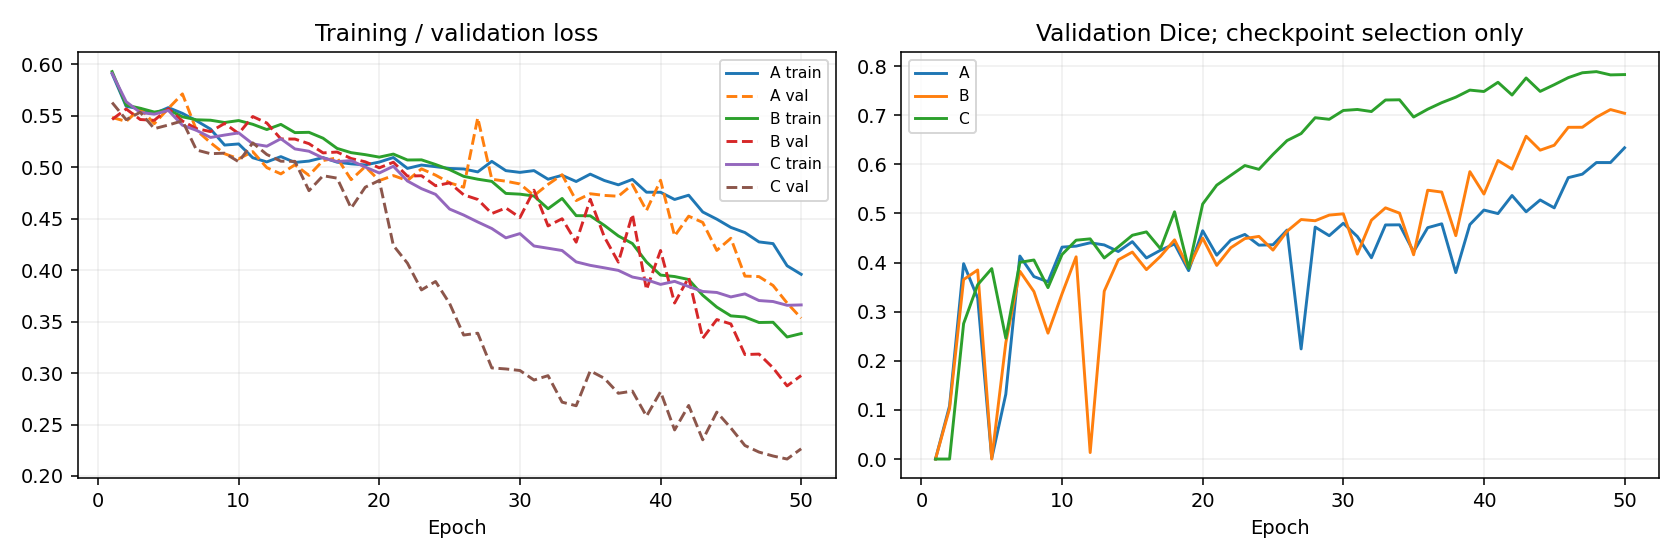

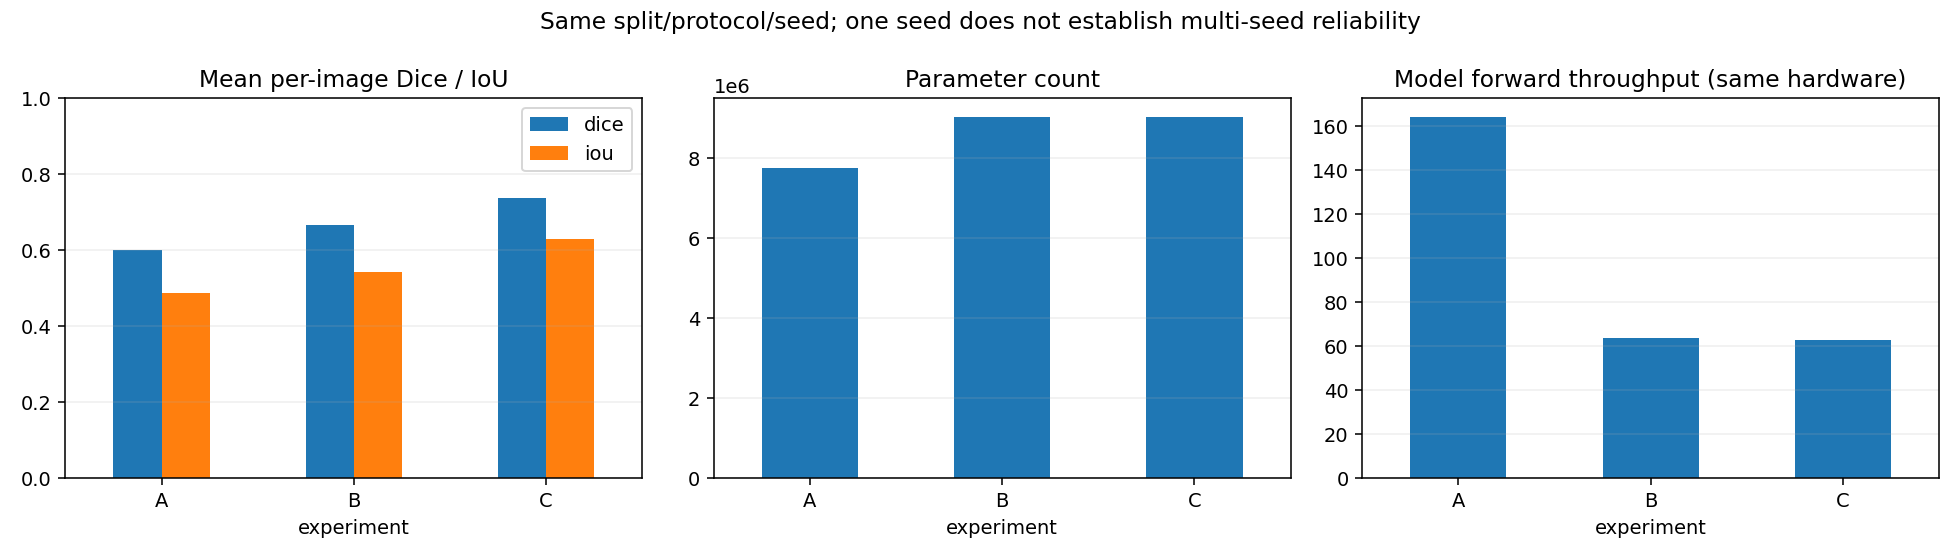

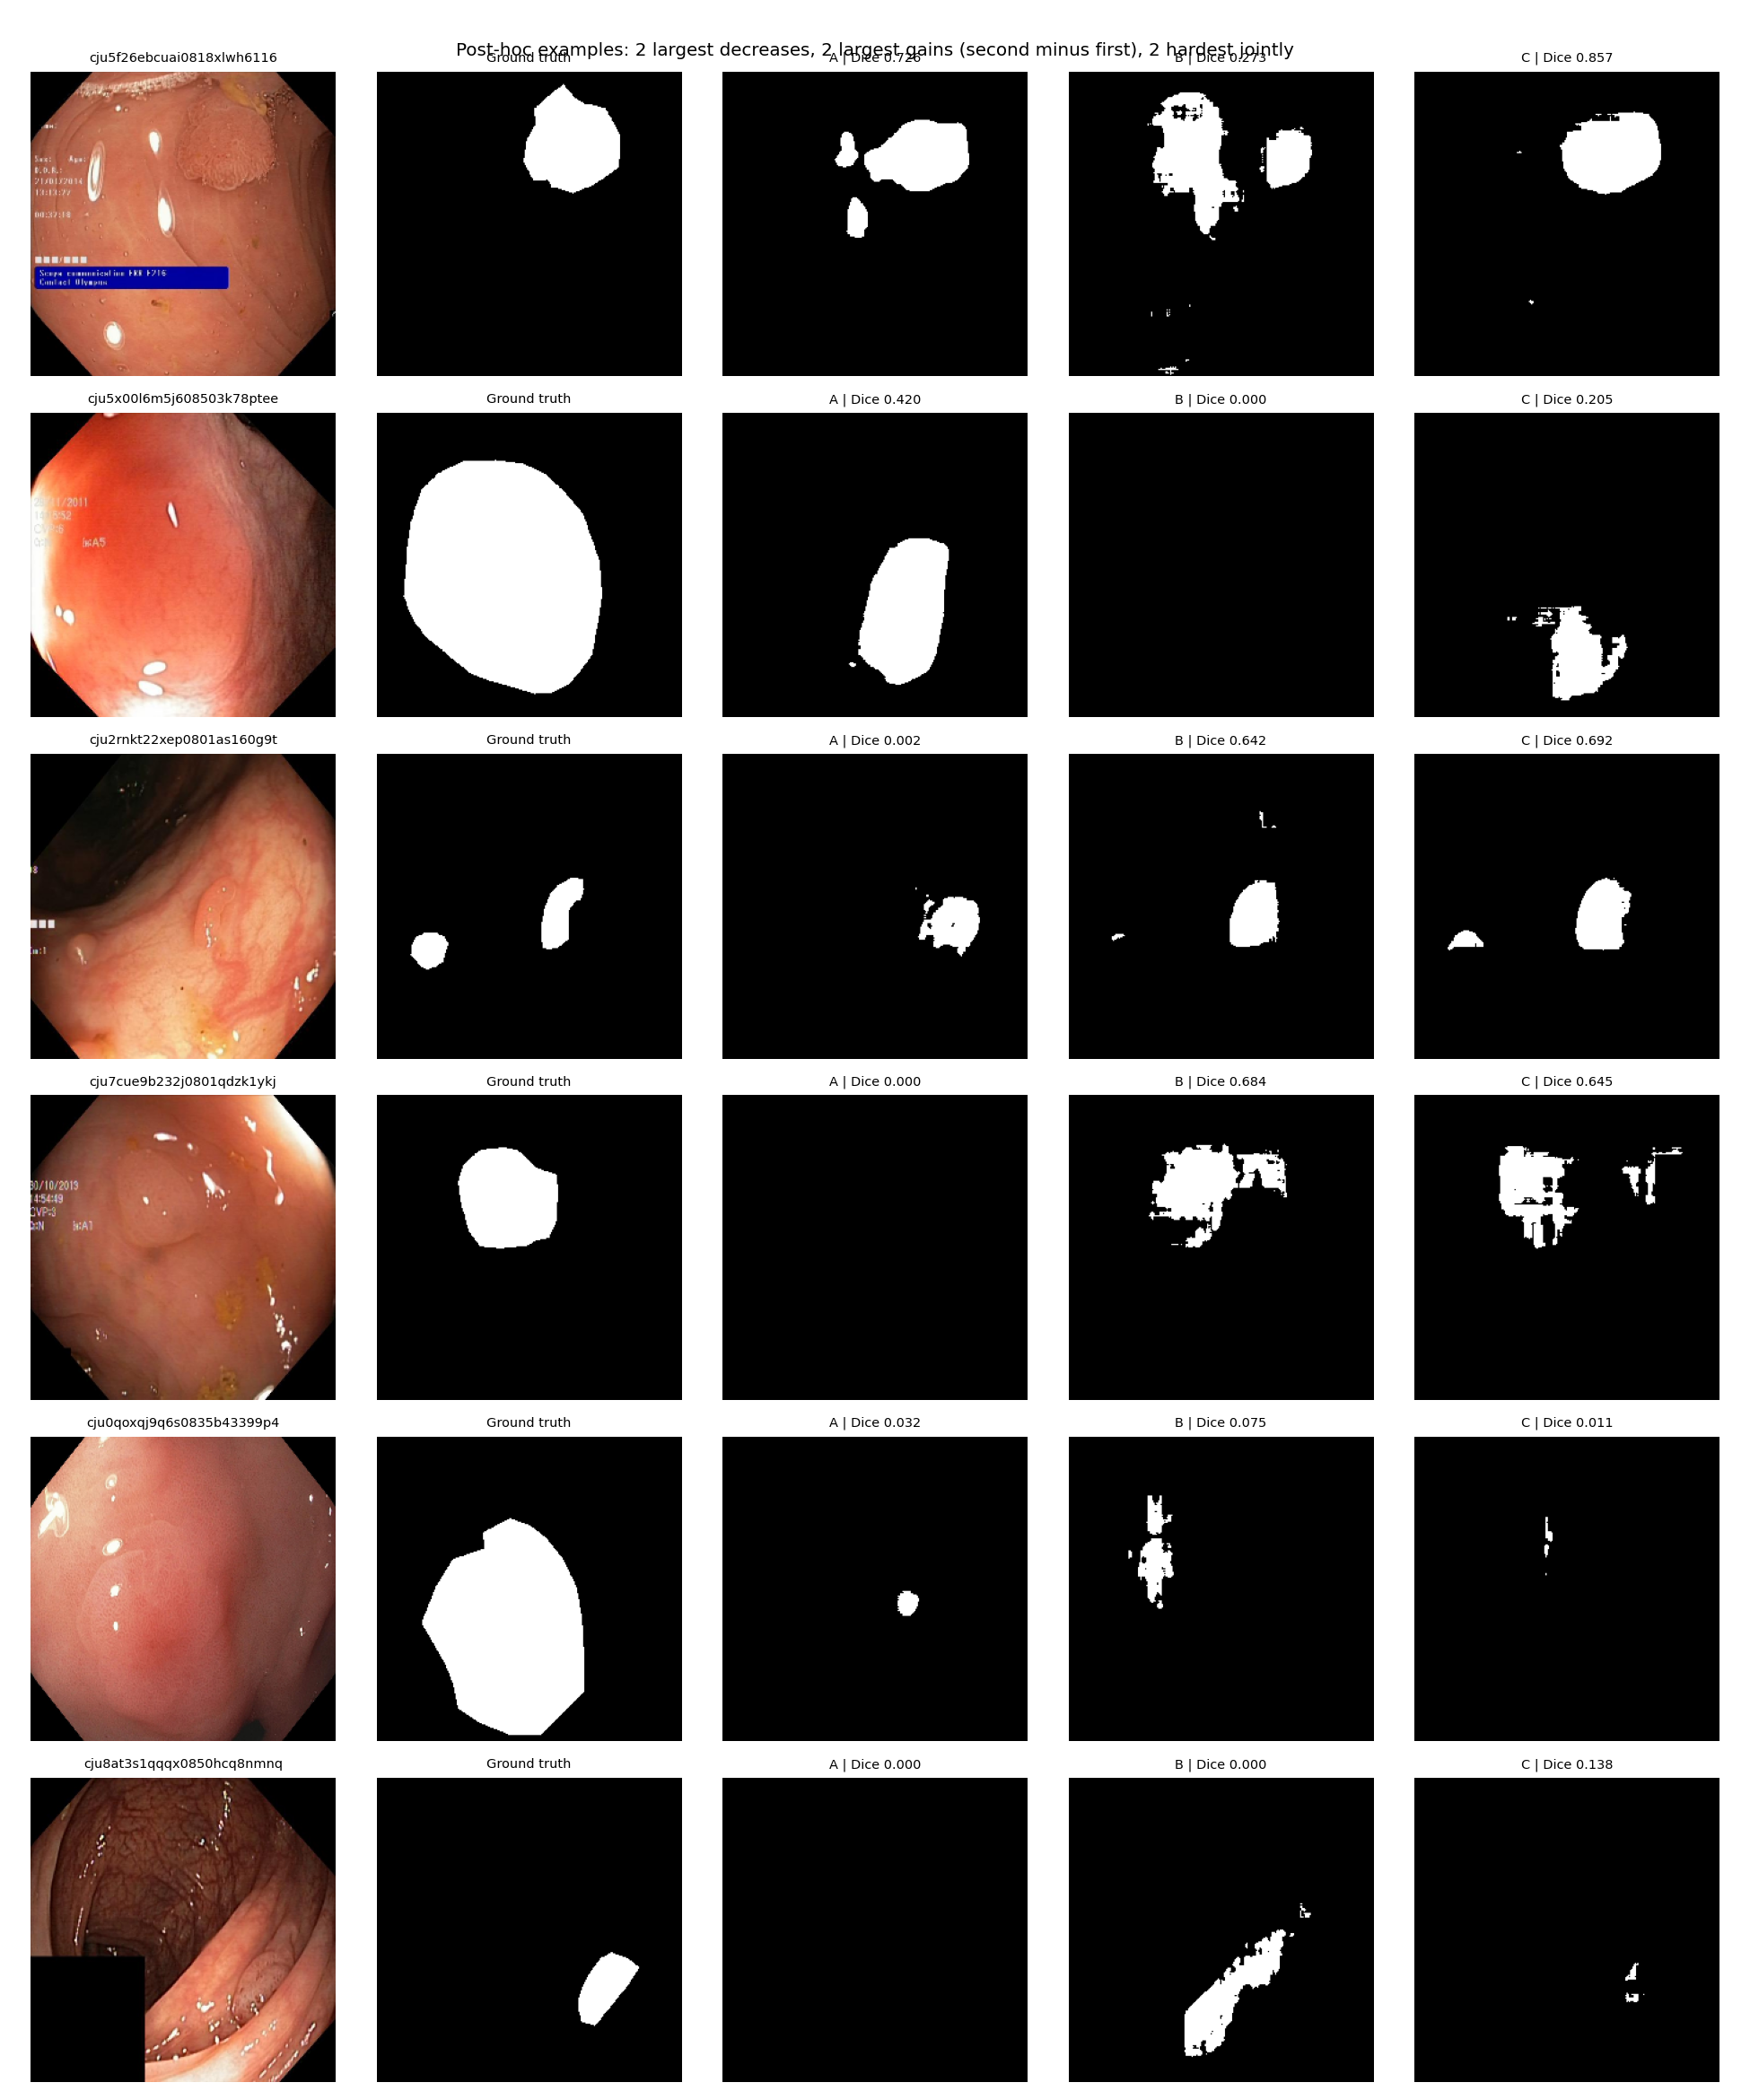

In [69]:
if TRAIN_FROM_SCRATCH:
    lock_path = OUTPUT/'protocol_lock.json'
    lock = create_protocol_lock([run_paths[k] for k in ['A','B','C']], ['A','B','C'], lock_path)
else:
    lock_path = ROOT/'configs/protocol_lock.json'
    lock = json.loads(lock_path.read_text('utf-8'))
print('Khóa đã có trước test:', lock['status'], '| manifest SHA:', lock['manifest_sha256'])
# Trainer bật deterministic; CLI evaluator chạy trong process mới với
# cuDNN mặc định. Khôi phục cùng trạng thái trước khi đánh giá trong kernel.
torch.use_deterministic_algorithms(False)
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = False
__file__ = str(ROOT/'members/tri/works_done/evaluate.py')
evaluations = {}
for label, run_path in run_paths.items():
    path = OUTPUT/(label+'_test')
    summary = evaluate_checkpoint(run_path/'best.pt','test',path,device=DEVICE,
                                  batch_size=8,protocol_lock=lock_path)
    assert summary['image_count'] == 150
    evaluations[label] = path
    print(label, summary['metrics'])
__file__ = str(ROOT/'members/tri/works_done/compare.py')
comparison = compare_evaluations(list(evaluations.values()),OUTPUT/'comparison')
current = pd.read_csv(OUTPUT/'comparison/comparison.csv')
reference = pd.read_csv(ROOT/'results/comparison/comparison.csv')
display(current)
contrast = current[['experiment','dice','iou']].merge(reference[['experiment','dice','iou']],
                on='experiment',suffixes=('_notebook','_bao_cao'),validate='one_to_one')
contrast['delta_dice'] = contrast.dice_notebook-contrast.dice_bao_cao
contrast.to_csv(OUTPUT/'doi_chieu_bao_cao.csv',index=False)
display(contrast)
print('Số báo cáo được giữ nguyên. Đây là lượt mới cùng seed, không phải seed độc lập mới.')
for name in ['training_curves.png','comparison.png','paired_examples.png']:
    if (OUTPUT/'comparison'/name).is_file(): display(DisplayImage(filename=str(OUTPUT/'comparison'/name)))

### 6.5 Vẽ lại các biểu đồ kết quả và phân tích lỗi

Các hình dưới đây dùng CSV/mask vừa xuất bởi evaluator trong lượt notebook, tương ứng nội dung Hình 4.5, 4.8–4.10. Không nhập điểm bằng tay. Hình ca lỗi theo quy tắc sau khi có kết quả đã được tạo ở phần compare phía trên.

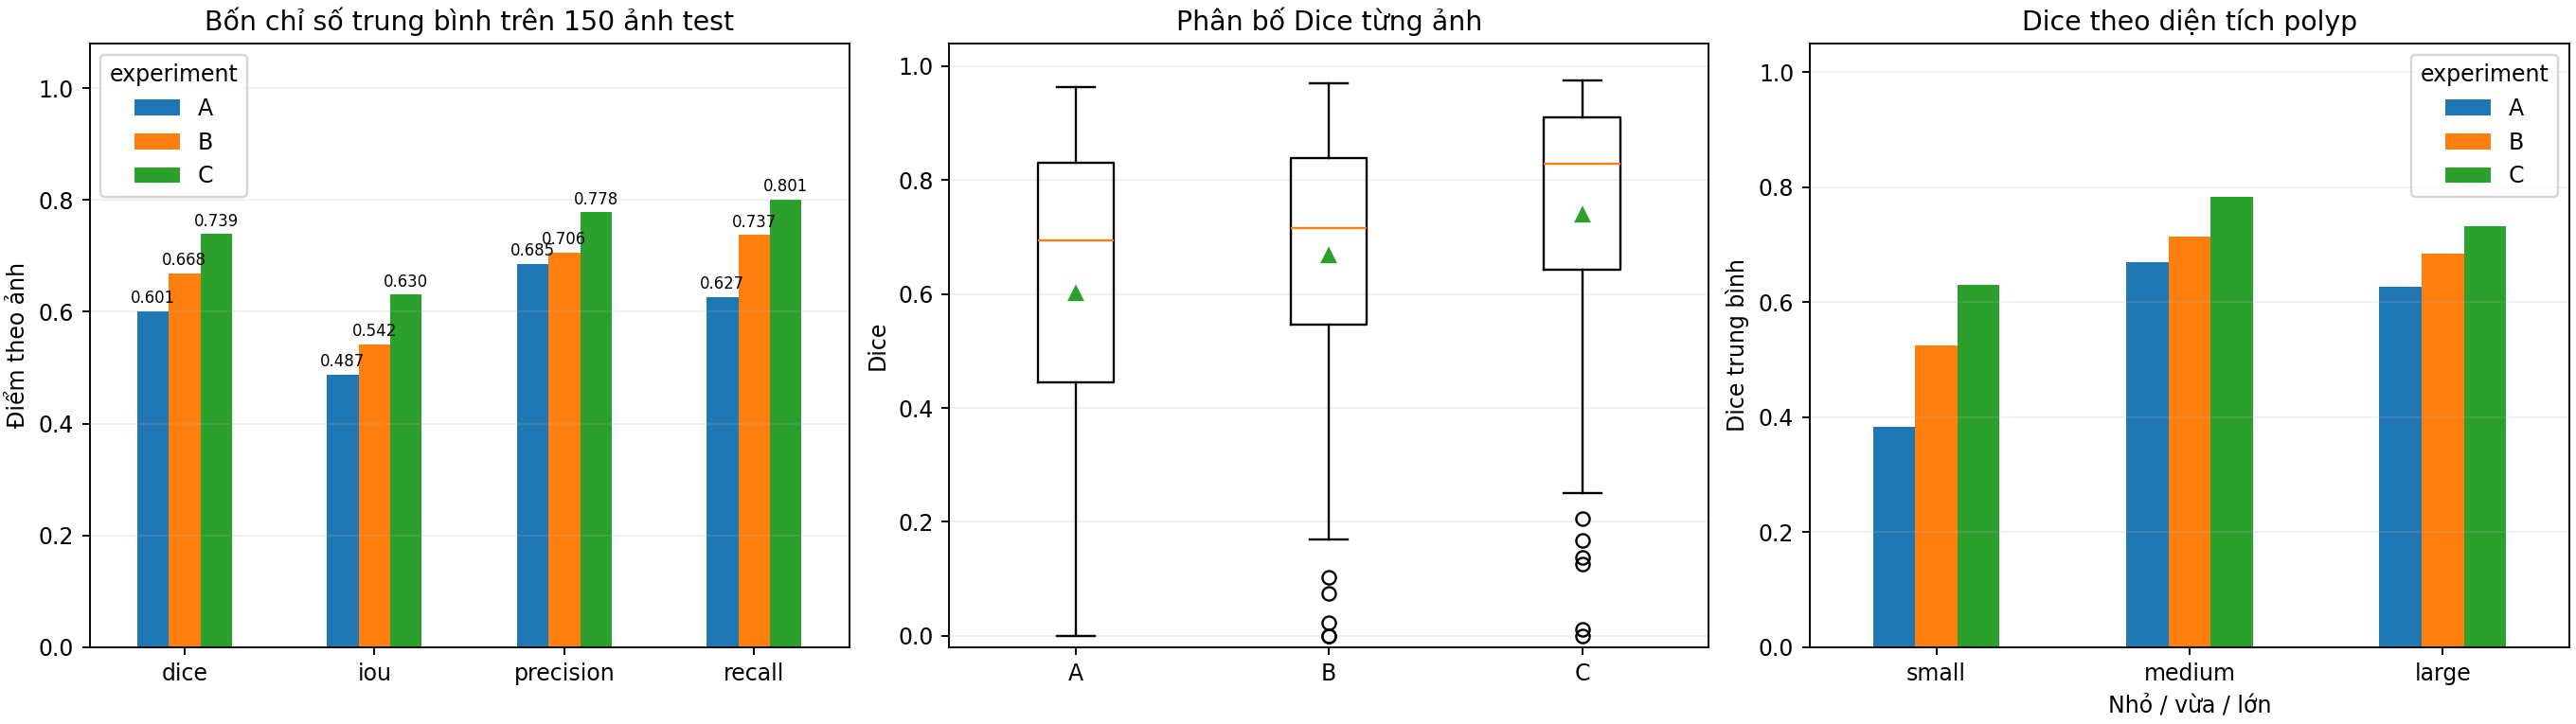

,experiment,polyp_category,count,dice,iou,precision,recall
0,A,large,40,0.627513,0.489357,0.930222,0.514513
1,A,medium,80,0.670005,0.562344,0.685859,0.713836
2,A,small,30,0.383723,0.284234,0.356670,0.544154
3,B,large,40,0.684921,0.560725,0.897643,0.583721
4,B,medium,80,0.713715,0.583920,0.691580,0.793310
5,B,small,30,0.524731,0.405690,0.489749,0.790973
6,C,large,40,0.731807,0.621514,0.935314,0.652413
7,C,medium,80,0.783385,0.679884,0.772446,0.853449
8,C,small,30,0.630465,0.510313,0.582429,0.857643


In [70]:
fig, axes = plt.subplots(1,3,figsize=(16,4.5),constrained_layout=True)
current.set_index('experiment')[['dice','iou','precision','recall']].T.plot.bar(ax=axes[0],rot=0,ylim=(0,1.08))
axes[0].set(title='Bốn chỉ số trung bình trên 150 ảnh test',ylabel='Điểm theo ảnh')
for bars in axes[0].containers: axes[0].bar_label(bars,fmt='%.3f',fontsize=7,padding=2)
image_tables = {k:pd.read_csv(v/'per_image.csv').set_index('image_id') for k,v in evaluations.items()}
assert all(len(t)==150 and t.index.is_unique for t in image_tables.values())
axes[1].boxplot([t.dice.to_numpy() for t in image_tables.values()],tick_labels=list(image_tables),showmeans=True)
axes[1].set(title='Phân bố Dice từng ảnh',ylabel='Dice',ylim=(-.02,1.04))
by_size = pd.read_csv(OUTPUT/'comparison/comparison_by_size.csv')
by_size.pivot(index='polyp_category',columns='experiment',values='dice').reindex(['small','medium','large']).plot.bar(ax=axes[2],rot=0,ylim=(0,1.05))
axes[2].set(title='Dice theo diện tích polyp',xlabel='Nhỏ / vừa / lớn',ylabel='Dice trung bình')
for ax in axes:ax.grid(axis='y',alpha=.2)
path = OUTPUT/'metrics_distribution_size.png'
fig.savefig(path,dpi=170)
display(DisplayImage(filename=str(path)));plt.close(fig)
display(by_size)

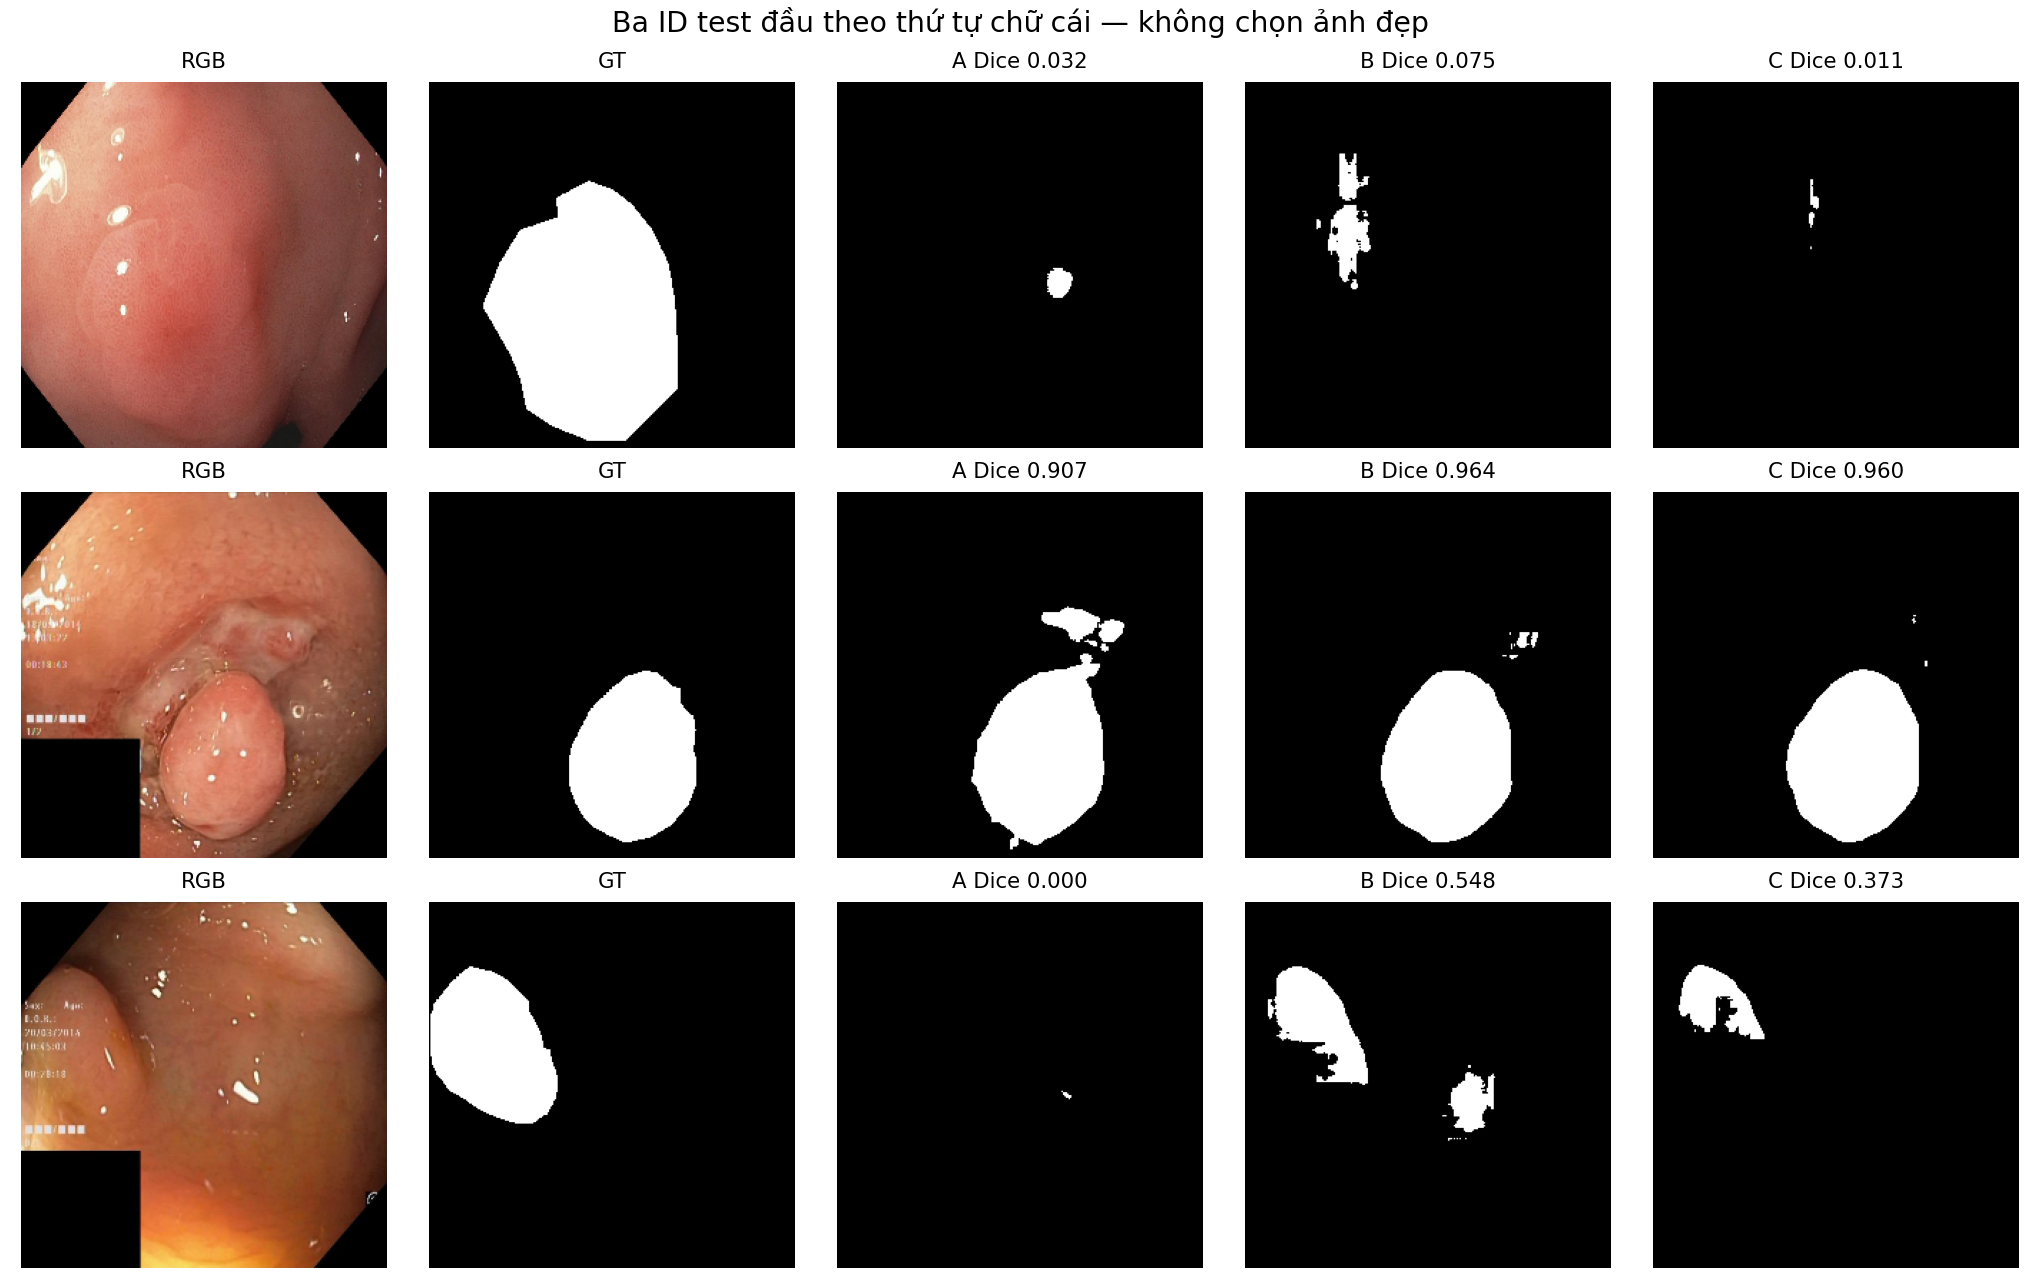

Ba ID chọn trước: ['cju0qoxqj9q6s0835b43399p4', 'cju13cgqmnhwn0988yrainhcp', 'cju13hp5rnbjx0835bf0jowgx']


In [71]:
selected_ids = sorted(manifest.loc[manifest.split.eq('test'),'image_id'])[:3]
metadata = manifest.set_index('image_id')
fig, axes = plt.subplots(3,5,figsize=(12,7.5),constrained_layout=True)
for row,image_id in enumerate(selected_ids):
    info = metadata.loc[image_id]
    rgb = read_image_unicode(ROOT/info.image_path.replace('\\','/'),cv2.IMREAD_COLOR)
    rgb = cv2.resize(cv2.cvtColor(rgb,cv2.COLOR_BGR2RGB),(256,256))
    gt = read_image_unicode(ROOT/info.mask_path.replace('\\','/'),cv2.IMREAD_GRAYSCALE)>127
    gt = cv2.resize(gt.astype(np.uint8),(256,256),interpolation=cv2.INTER_NEAREST)
    views = [rgb,gt]+[np.asarray(Image.open(evaluations[k]/'masks'/(image_id+'.png'))) for k in 'ABC']
    titles = ['RGB','GT']+[k+' Dice '+f'{image_tables[k].loc[image_id,"dice"]:.3f}' for k in 'ABC']
    for ax,view,title in zip(axes[row],views,titles):
        ax.imshow(view,cmap='gray' if view.ndim==2 else None)
        ax.set_title(title,fontsize=9);ax.axis('off')
fig.suptitle('Ba ID test đầu theo thứ tự chữ cái — không chọn ảnh đẹp')
path = OUTPUT/'first_three_test_ids.png'
fig.savefig(path,dpi=170)
display(DisplayImage(filename=str(path)));plt.close(fig)
print('Ba ID chọn trước:',selected_ids)

## 7 Thống kê và phân tích deep supervision

Ghép theo image_id; bootstrap 10.000 lần seed 0 và Wilcoxon hai phía. Khoảng tin cậy chỉ phản ánh biến thiên giữa ảnh với checkpoint cố định, chưa phản ánh nhiều seed hoặc độc lập bệnh nhân/video. Mean head là trung bình xác suất rồi threshold, không phải trung bình loss.

### 7.1 Code thống kê và từng head

Nguồn đối chiếu: `members/tri/works_done/submission_analysis.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [72]:
def bootstrap_ci(values, samples=10000, seed=0):
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or len(values) < 2 or not np.isfinite(values).all():
        raise ValueError("Bootstrap cần ít nhất hai giá trị hữu hạn")
    rng = np.random.default_rng(seed)
    means = values[rng.integers(0, len(values), size=(samples, len(values)))].mean(1)
    return [float(x) for x in np.percentile(means, [2.5, 97.5])]

In [73]:
def paired_statistics(first, second):
    # Ghép bằng ID, không dựa vào vị trí dòng trong hai CSV.
    if first.image_id.duplicated().any() or second.image_id.duplicated().any():
        raise ValueError("CSV có ID trùng")
    if set(first.image_id) != set(second.image_id):
        raise ValueError("Hai CSV không cùng tập ảnh")
    paired = first[["image_id", "dice"]].merge(second[["image_id", "dice"]], on="image_id", validate="one_to_one")
    diff = (paired.dice_y - paired.dice_x).to_numpy()
    from scipy.stats import wilcoxon
    low, high = bootstrap_ci(diff)
    std = diff.std(ddof=1)
    return dict(delta=float(diff.mean()), ci_low=low, ci_high=high,
                p_wilcoxon=float(wilcoxon(diff).pvalue) if np.any(diff) else 1.,
                cohen_dz=float(diff.mean() / std) if std > 0 else None,
                images_up=int((diff > 0).sum()), images_down=int((diff < 0).sum()),
                images_equal=int((diff == 0).sum()))

In [74]:
def export_statistics(evaluation_paths, labels, output):
    output = resolve_project_path(output)
    if output.exists() and any(output.iterdir()):
        raise FileExistsError("Chọn output thống kê mới")
    if len(labels) != len(evaluation_paths) or len(set(labels)) != len(labels):
        raise ValueError("Labels và các folder đánh giá phải tương ứng, không trùng")
    tables = {label: pd.read_csv(Path(path) / "per_image.csv") for label, path in zip(labels, evaluation_paths)}
    comparisons, intervals = {}, {}
    for i, a in enumerate(labels):
        intervals[a] = bootstrap_ci(tables[a].dice)
        for b in labels[i + 1:]:
            comparisons[f"{b}_vs_{a}"] = paired_statistics(tables[a], tables[b])
    result = dict(bootstrap_samples=10000, bootstrap_seed=0, paired_dice=comparisons,
                  dice_confidence_intervals=intervals,
                  scope="Conditional image-level analysis of these fixed checkpoints; not multi-seed uncertainty. Patient/video independence is unverified.")
    output.mkdir(parents=True, exist_ok=True)
    (output / "paired_stats.json").write_text(json.dumps(result, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    return result

In [75]:
@torch.inference_mode()
def evaluate_heads(checkpoint_path, split, output, device="cpu", batch_size=1, protocol_lock=None):
    """Xuất cả 4 head và mean trong MỘT lượt forward; phân tích bổ sung riêng."""
    output = resolve_project_path(output)
    if output.exists() and any(output.iterdir()):
        raise FileExistsError("Chọn output phân tích head mới")
    device = resolve_device(device)
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    path = resolve_project_path(checkpoint_path)
    model, checkpoint = load_checkpoint(path, device)
    if not checkpoint["model_kwargs"].get("deep_supervision"):
        raise ValueError("Phân tích head chỉ dành cho U-Net++ deep supervision")
    if split not in {"val", "test"} or batch_size < 1:
        raise ValueError("Cần split val/test và batch size dương")
    if split == "test":
        if not protocol_lock:
            raise ValueError("Phân tích test cần khóa của checkpoint đã chọn trước đó")
        verify_protocol_lock(checkpoint, protocol_lock, path)
    manifest = checkpoint_manifest(checkpoint)
    loader = get_dataloader(split, csv_path=manifest, project_root=PROJECT_ROOT,
                            batch_size=batch_size, img_size=tuple(checkpoint["preprocessing"]["image_size"]),
                            return_id=True, augment=False, shuffle=False)
    threshold = checkpoint_threshold(checkpoint)
    rows = []
    for images, targets, ids in loader:
        probabilities = [logits.sigmoid() for logits in model(images.to(device))]
        policies = {str(i + 1): p for i, p in enumerate(probabilities)}
        policies["mean"] = torch.stack(probabilities).mean(0)
        for policy, p in policies.items():
            metrics = binary_mask_metrics(p >= threshold, targets.to(device).bool())
            for k, image_id in enumerate(ids):
                rows.append(dict(image_id=image_id, head=policy, **{m: float(v[k]) for m, v in metrics.items()}))
    output.mkdir(parents=True, exist_ok=True)
    frame = pd.DataFrame(rows)
    frame.to_csv(output / "per_image_heads.csv", index=False)
    means = frame.groupby("head")[["dice", "iou", "precision", "recall"]].mean()
    means.to_csv(output / "heads_summary.csv")
    result = dict(split=split, checkpoint_sha256=sha256_file(path), threshold=threshold,
                  image_count=len(loader.dataset), selected_policy="last (fixed before test)",
                  role="Exploratory reproduction; does not replace the official test results",
                  metrics=means.to_dict(orient="index"))
    (output / "analysis.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
    return result

,delta,ci_low,ci_high,p_wilcoxon,cohen_dz,images_up,images_down,images_equal
B_vs_A,0.066823,0.033001,0.101171,4.833466e-04,0.319309,98.0,51.0,1.0
C_vs_A,0.137630,0.102424,0.172220,9.989739e-13,0.636252,116.0,34.0,0.0
C_vs_B,0.070807,0.049120,0.094554,4.135769e-10,0.505378,105.0,45.0,0.0


,dice,iou,precision,recall
1,0.367620,0.249043,0.469727,0.443179
2,0.586175,0.440375,0.625708,0.680820
3,0.767567,0.654529,0.780989,0.834678
4,0.788822,0.684537,0.803308,0.850309
mean,0.770090,0.660259,0.812097,0.812858


,dice,iou,precision,recall
1,0.332833,0.224228,0.414007,0.404304
2,0.560638,0.419372,0.597164,0.651924
3,0.726841,0.610005,0.756215,0.793007
4,0.739047,0.630404,0.777874,0.800678
mean,0.718269,0.609143,0.783525,0.758270


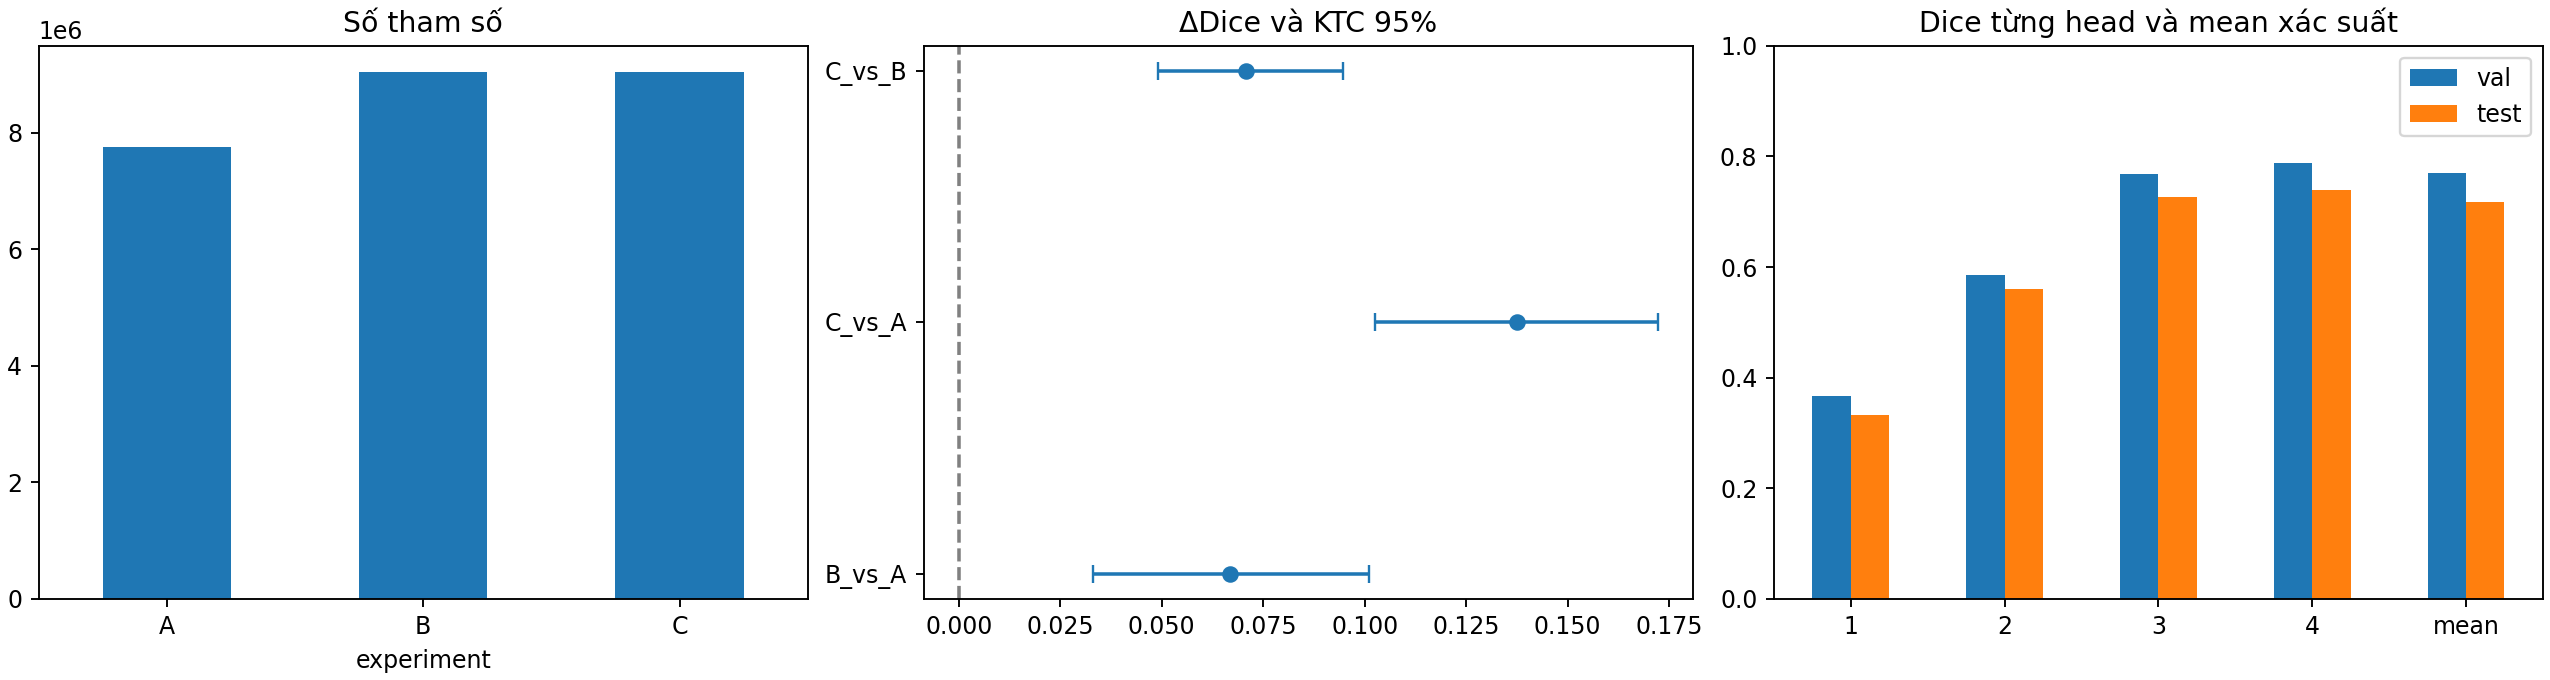

In [76]:
stats = export_statistics(list(evaluations.values()),list(evaluations),OUTPUT/'statistics')
stats_table = pd.DataFrame(stats['paired_dice']).T
display(stats_table)
head_results = {}
for split in ['val','test']:
    result = evaluate_heads(run_paths['C']/'best.pt',split,OUTPUT/('heads_'+split),
                            device=DEVICE,batch_size=8,protocol_lock=lock_path)
    head_results[split] = result
    display(pd.DataFrame(result['metrics']).T)
fig, axes = plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
current.plot.bar(x='experiment',y='parameters',ax=axes[0],legend=False,rot=0,title='Số tham số')
positions = np.arange(len(stats_table))
axes[1].errorbar(stats_table.delta,positions,
    xerr=np.array([stats_table.delta-stats_table.ci_low,stats_table.ci_high-stats_table.delta]),fmt='o',capsize=4)
axes[1].axvline(0,color='gray',linestyle='--');axes[1].set(yticks=positions,yticklabels=stats_table.index,title='ΔDice và KTC 95%')
head_frame = pd.DataFrame({s:{h:v['dice'] for h,v in r['metrics'].items()} for s,r in head_results.items()})
head_frame.plot.bar(ax=axes[2],ylim=(0,1),rot=0,title='Dice từng head và mean xác suất')
fig.savefig(OUTPUT/'charts_supplement.png',dpi=170)
display(DisplayImage(filename=str(OUTPUT/'charts_supplement.png')));plt.close(fig)

## 8 Xem lại toàn bộ hình trong báo cáo

Đây là hình từ lượt tham chiếu đã công bố, có nhãn riêng. Không gán hình tham chiếu cho kết quả huấn luyện mới. Hình paper minh họa lý thuyết; không phải kết quả Kvasir-SEG của nhóm.

**Hình tham chiếu:** `metric_comparison.png`

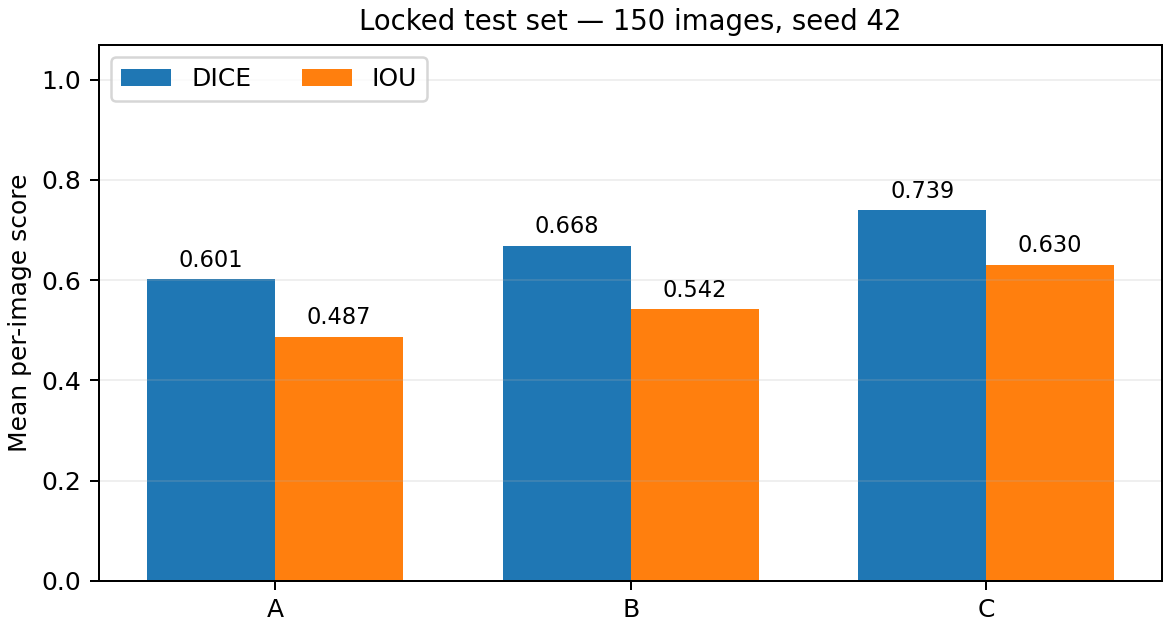

**Hình tham chiếu:** `paired_examples.png`

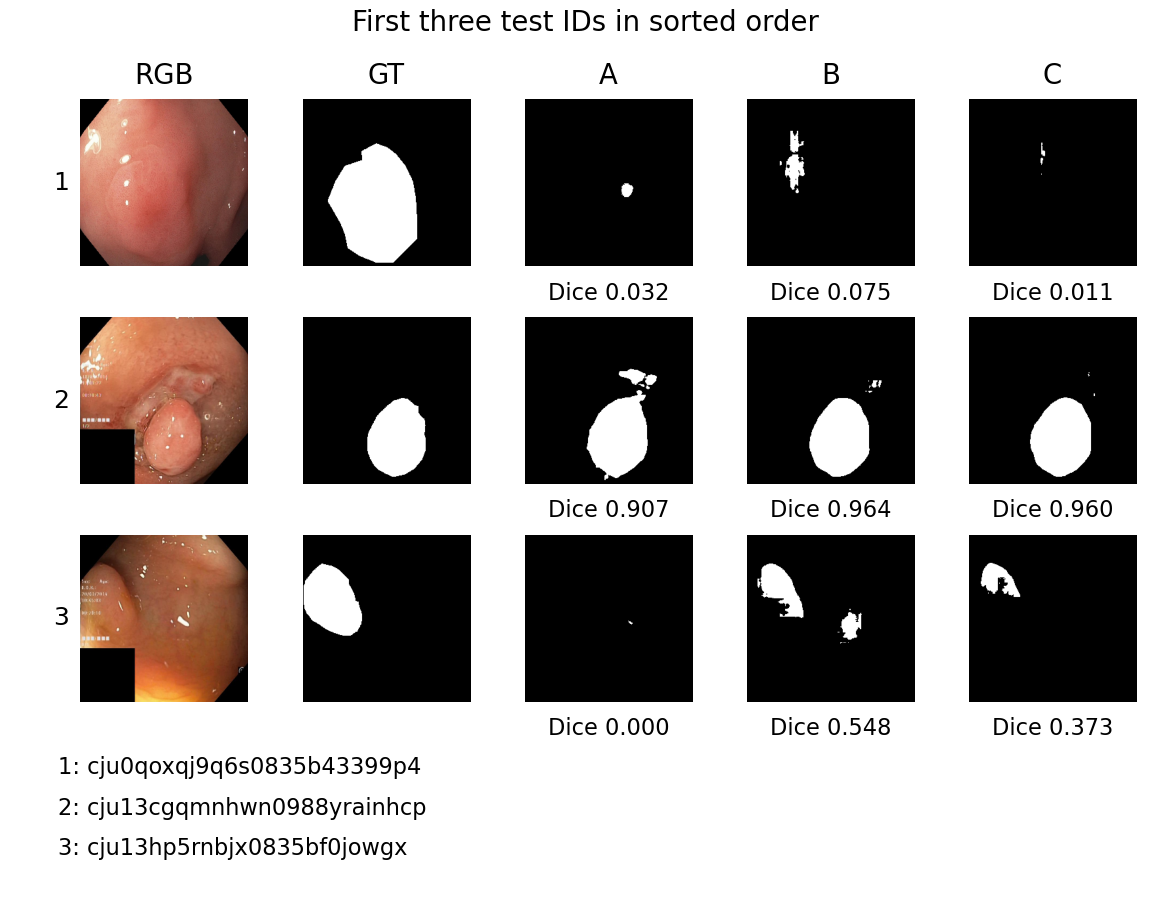

**Hình tham chiếu:** `submission_folder_flow.png`

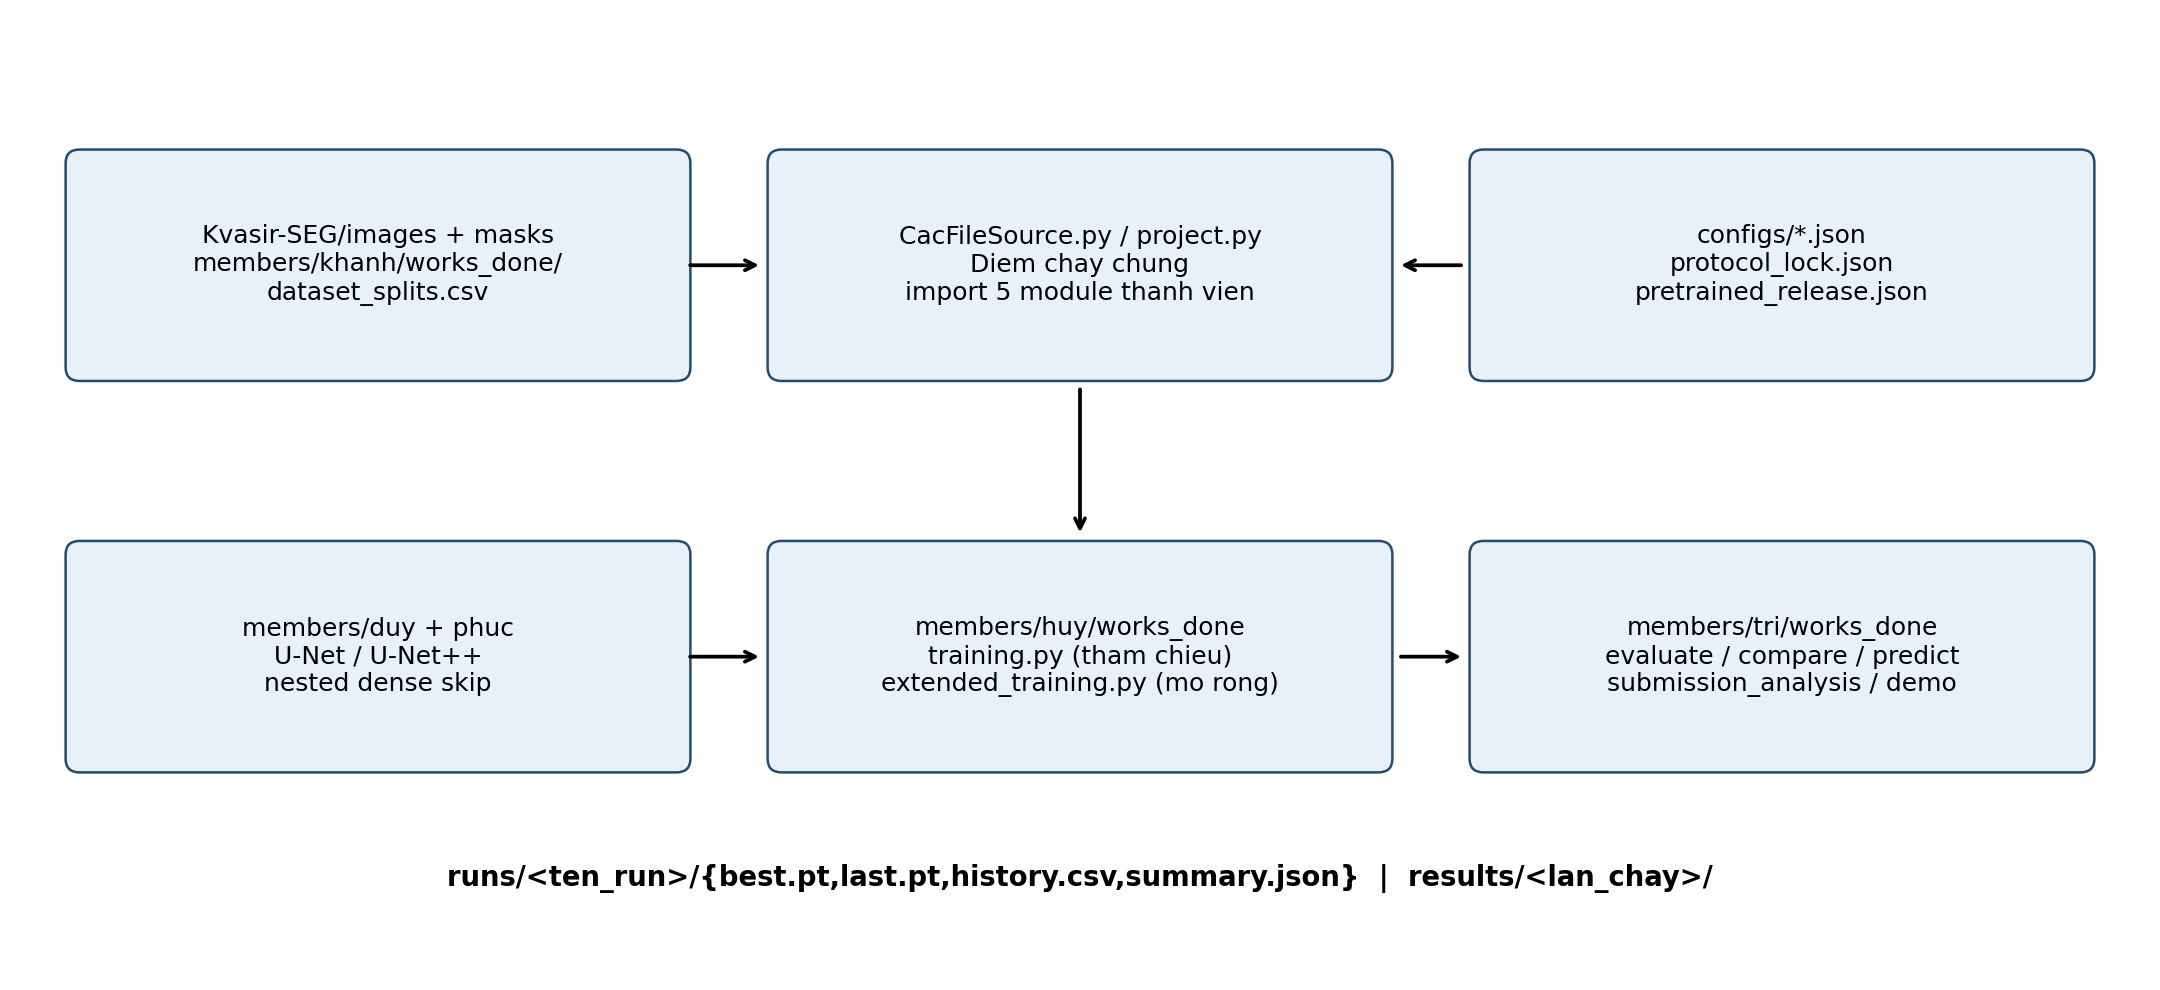

**Hình tham chiếu:** `training_curves.png`

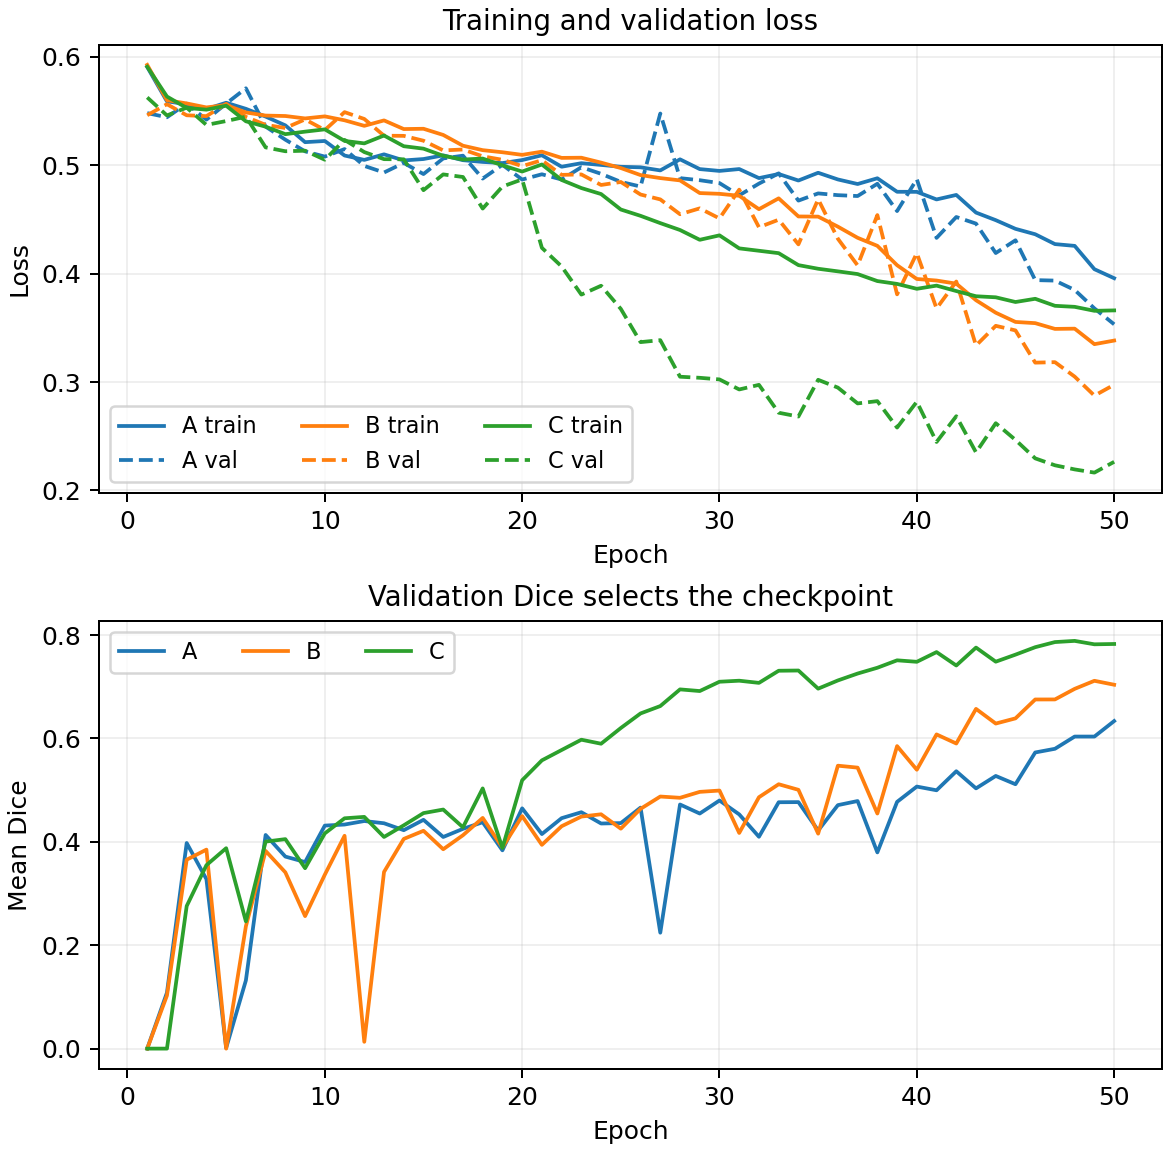

**Biểu đồ tham chiếu:** `model_parameters.png`

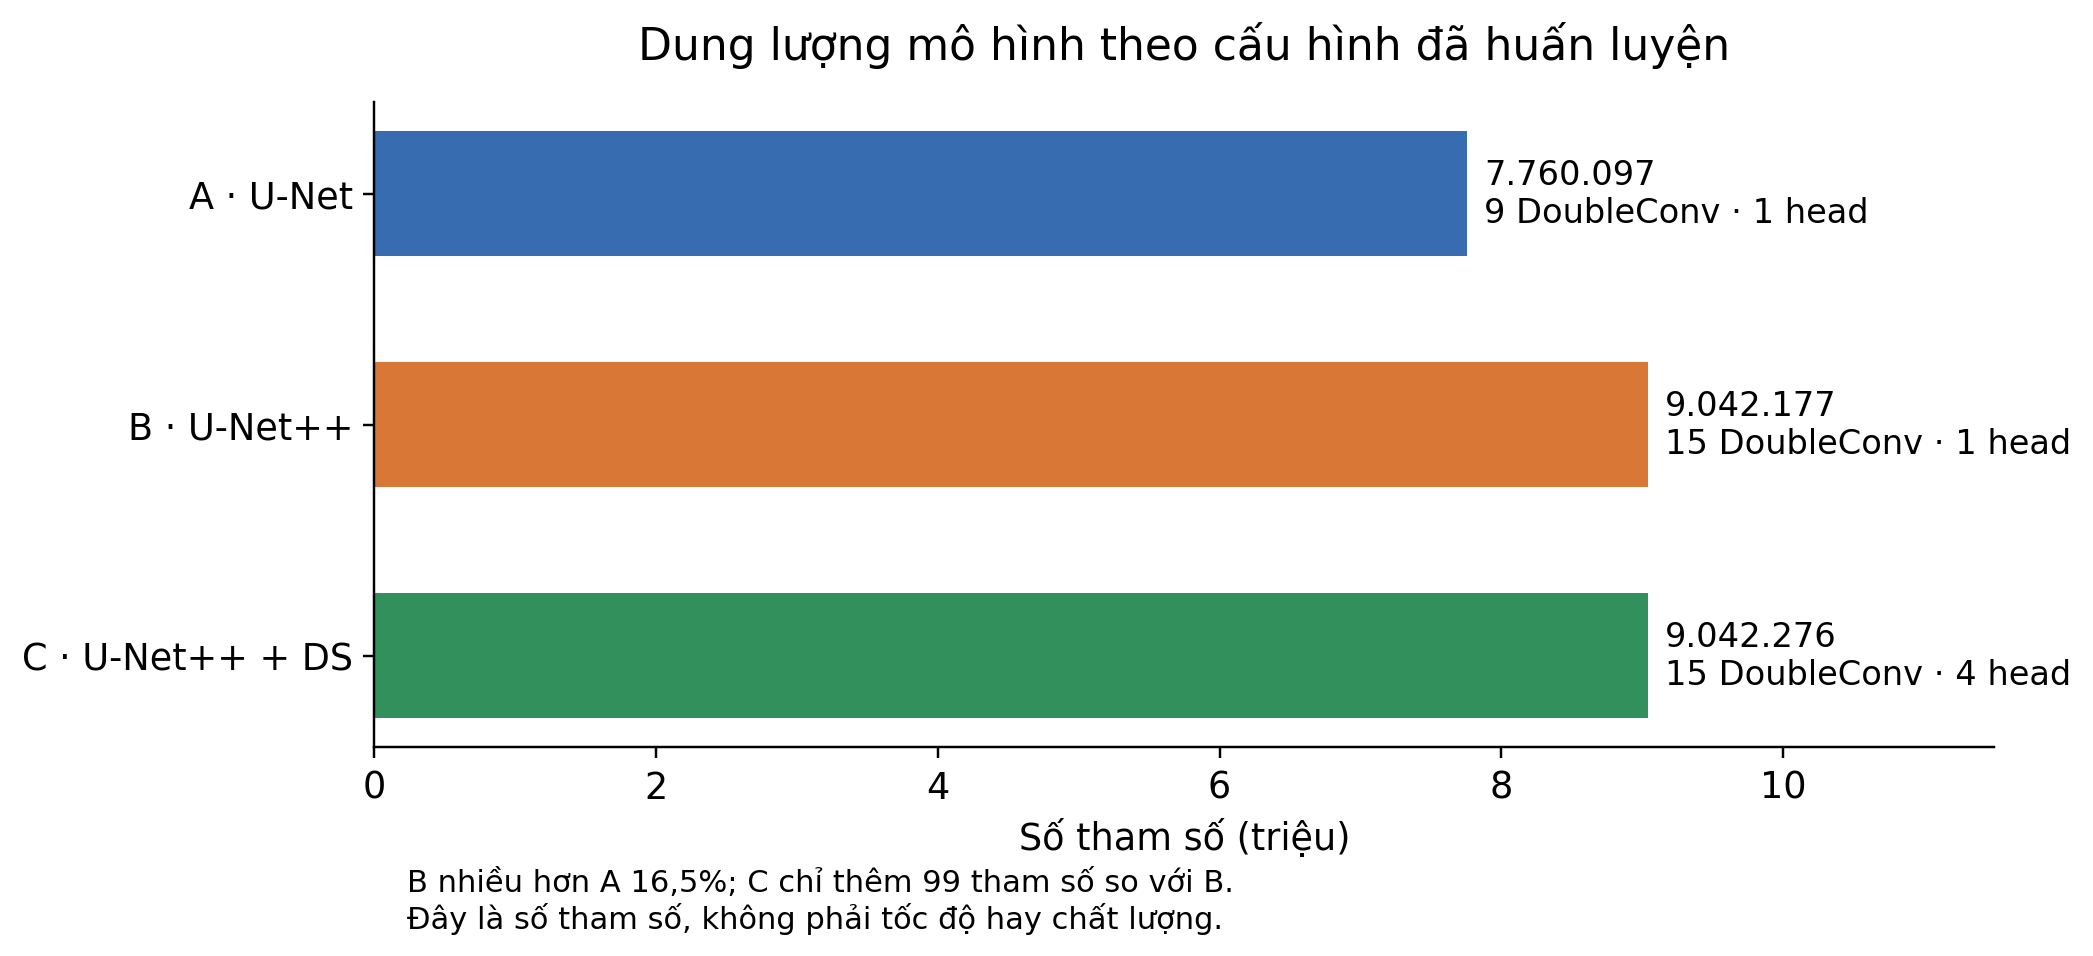

**Biểu đồ tham chiếu:** `paired_dice_uncertainty.png`

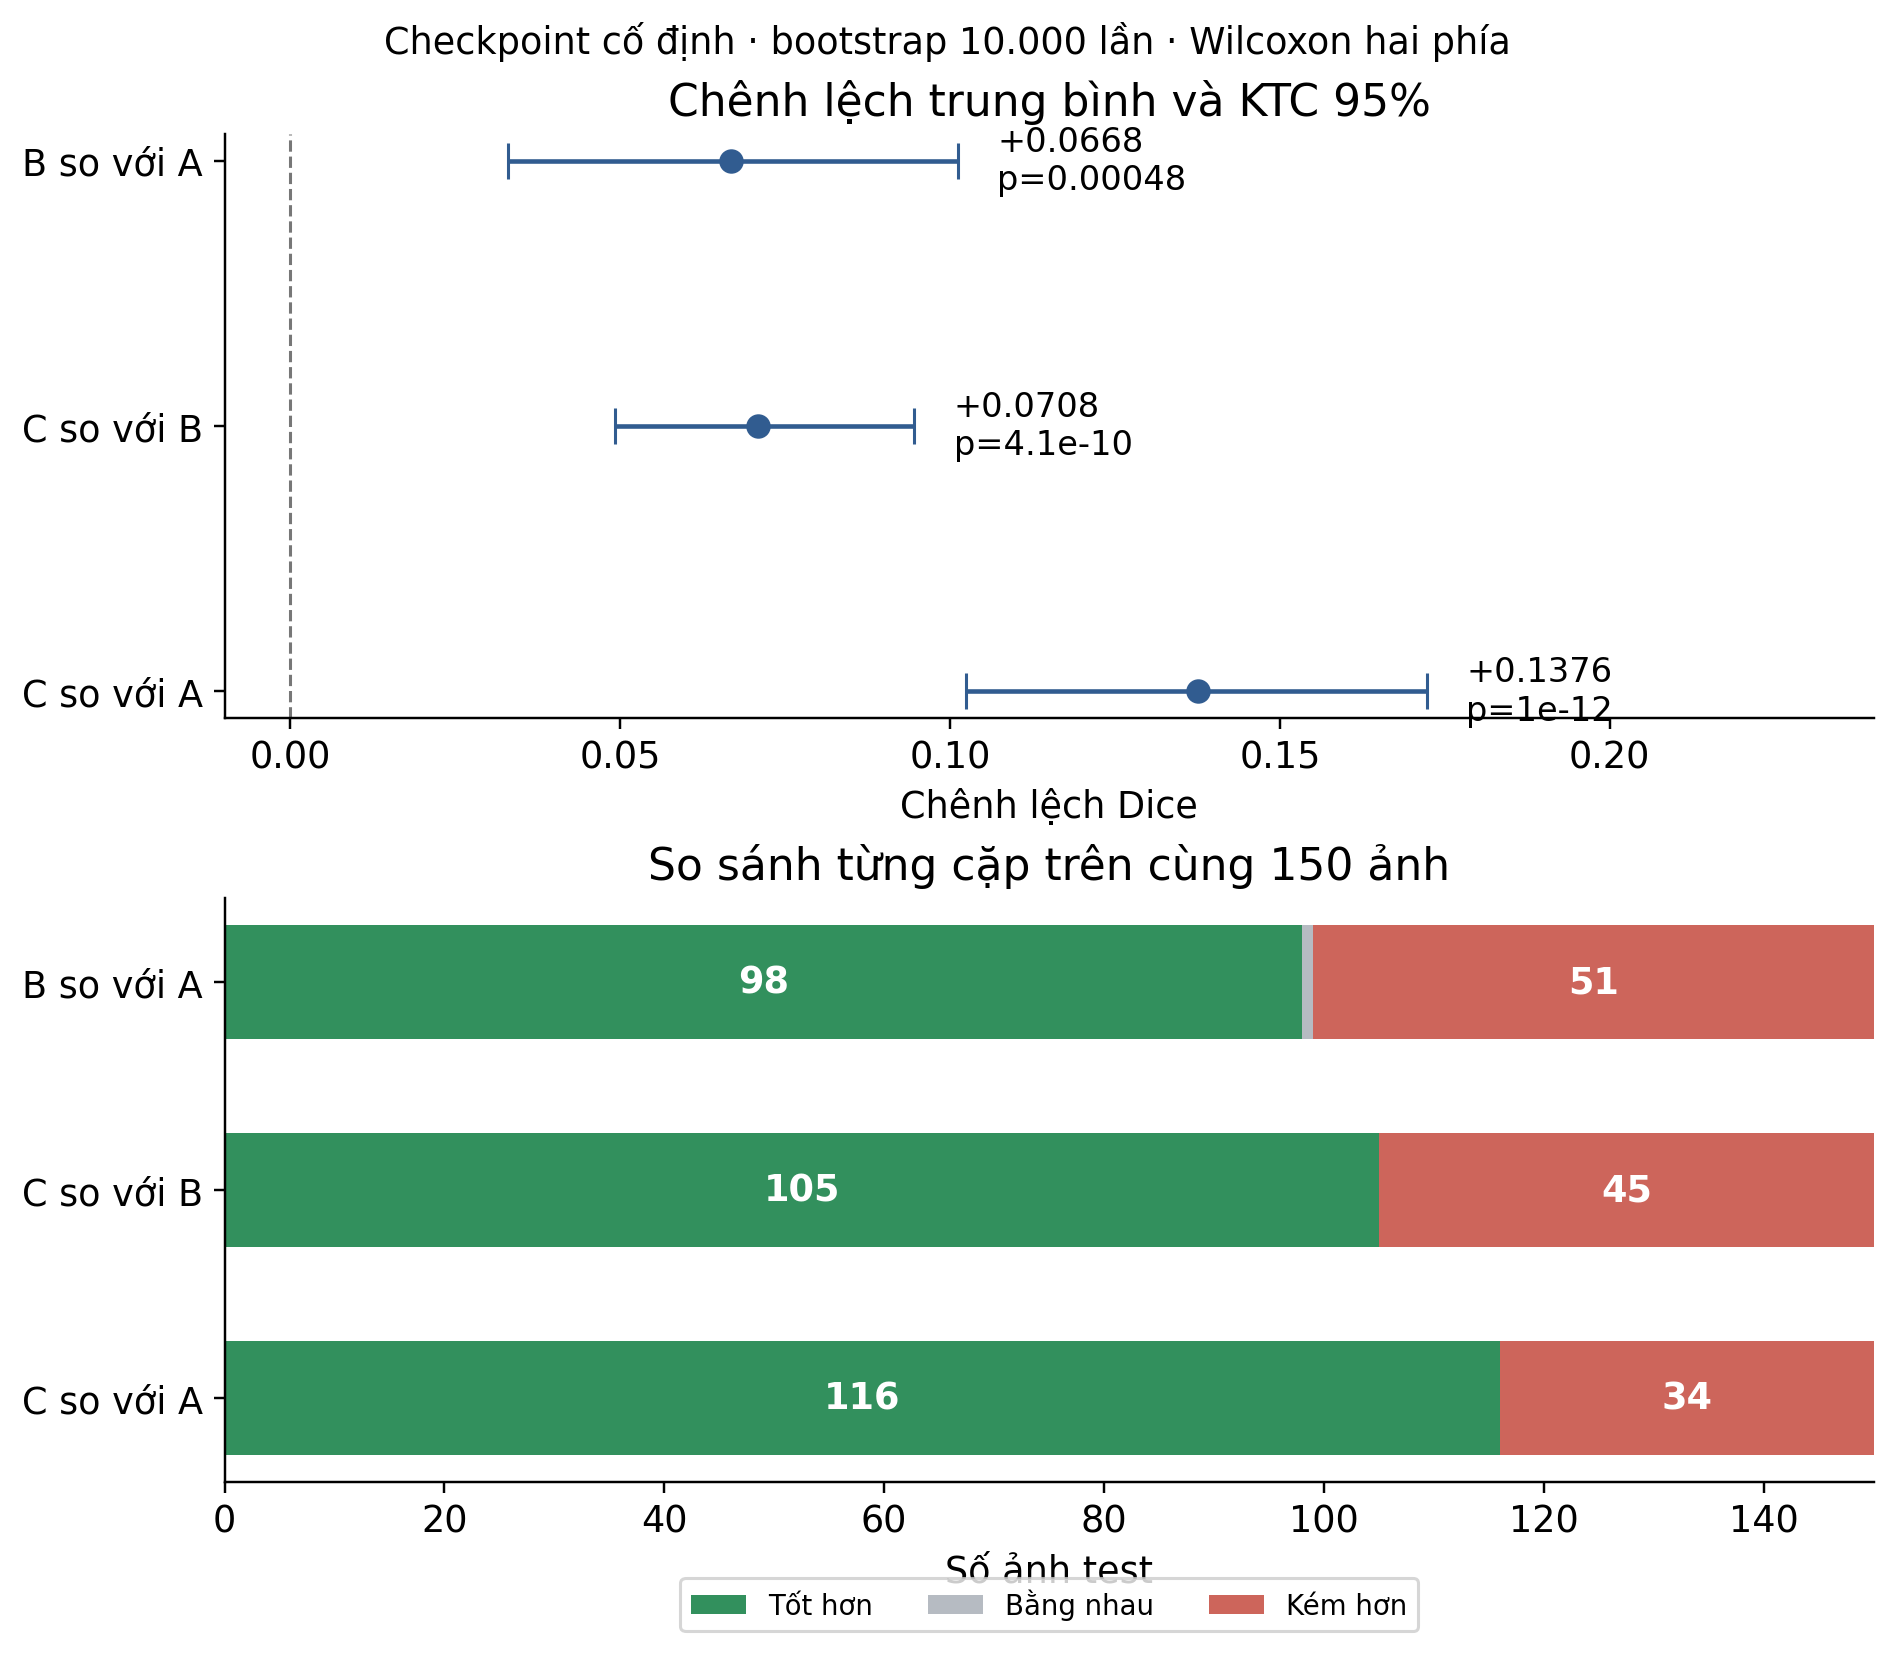

**Biểu đồ tham chiếu:** `deep_supervision_heads.png`

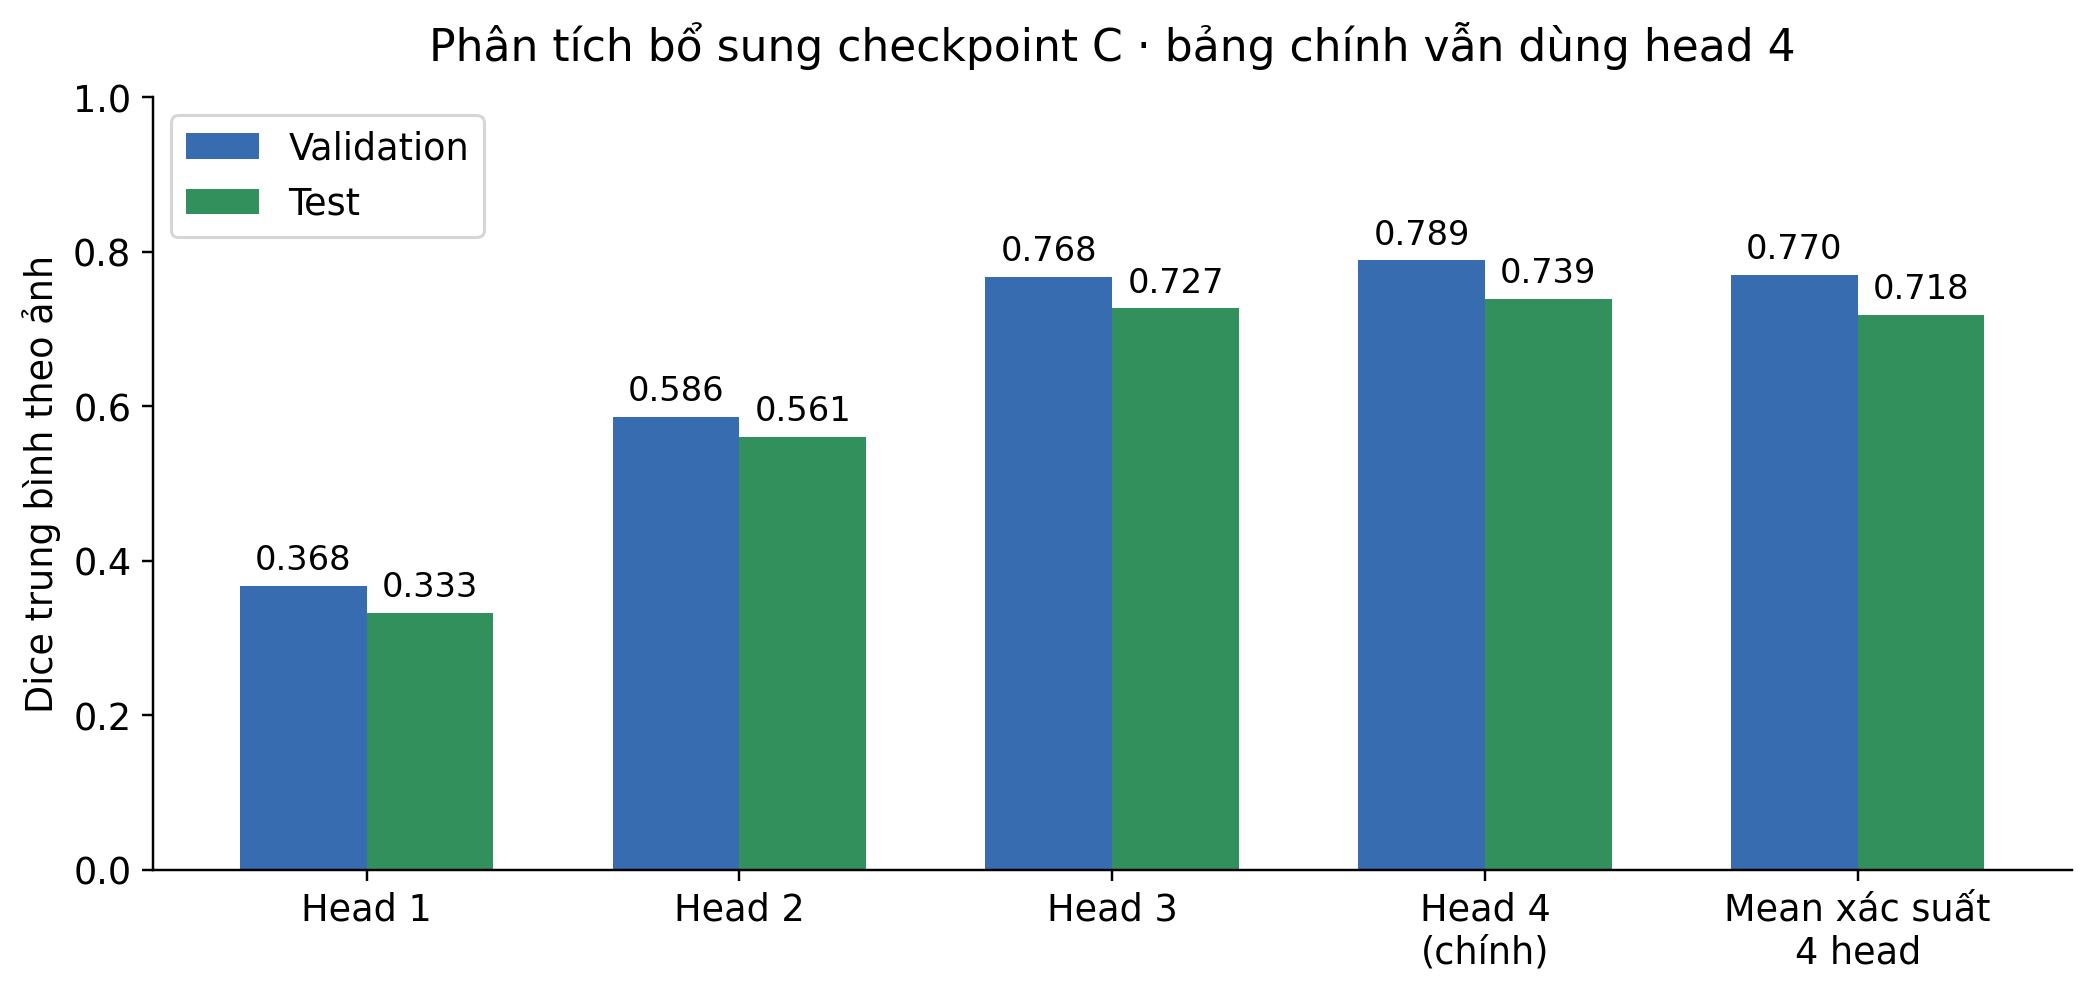

In [77]:
report_assets = ROOT/'results/report_figures'
for path in sorted(report_assets.glob('*.png')):
    display(Markdown('**Hình tham chiếu:** `'+path.name+'`'))
    display(DisplayImage(filename=str(path),width=850))
for name in ['model_parameters.png','paired_dice_uncertainty.png','deep_supervision_heads.png']:
    display(Markdown('**Biểu đồ tham chiếu:** `'+name+'`'))
    display(DisplayImage(filename=str(report_assets/'visual_report_20261114'/name),width=850))

## 9 Dự đoán ảnh và demo

Mask dùng để tính metric ở 256×256. Overlay dưới đây resize xác suất về kích thước ảnh gốc rồi threshold để quan sát. Không dùng Dice ở độ phân giải gốc để thay Dice benchmark. App Streamlit vẫn có thể mở riêng bằng `python project.py demo`; code dự đoán giống phần này.

### 9.1 Code dự đoán một ảnh

Nguồn đối chiếu: `members/tri/works_done/predict.py`. Các định nghĩa dưới đây chạy ngay trong kernel notebook.

In [78]:
def predict_image(model, checkpoint, image: Image.Image, device="cpu"):
    """Probability resize bilinear rồi threshold ở kích thước ảnh gốc.

    Mask được xuất ở hai độ phân giải. Chỉ số benchmark evaluator dùng input
    resolution; mask original ở đây dành cho demo ảnh mới, không trộn hai loại.
    """
    image = ImageOps.exif_transpose(image).convert("RGB")
    rgb = np.asarray(image).copy()
    image_size = tuple(checkpoint["preprocessing"]["image_size"])
    transform = get_transforms("val",image_size)
    tensor = transform(image=rgb)["image"].float().unsqueeze(0).to(device)
    threshold = checkpoint_threshold(checkpoint)
    model.eval()
    with torch.inference_mode():
        logits = last_logits(model(tensor))
        if logits.shape != (1,1,*image_size) or not torch.isfinite(logits).all():
            raise ValueError("Model prediction has incorrect shape or non-finite values")
        probability_input = logits.sigmoid()[0,0].cpu().numpy()
    probability_original = cv2.resize(probability_input,(image.width,image.height),interpolation=cv2.INTER_LINEAR)
    mask_input = probability_input >= threshold
    mask_original = probability_original >= threshold
    overlay = rgb.astype(float).copy()
    overlay[mask_original] = .6 * overlay[mask_original] + .4 * np.array([0,255,0])
    return {"image":image,"probability_input":probability_input,"probability_original":probability_original,
            "mask_input":Image.fromarray(mask_input.astype(np.uint8)*255),
            "mask_original":Image.fromarray(mask_original.astype(np.uint8)*255),
            "overlay":Image.fromarray(overlay.clip(0,255).astype(np.uint8)),"threshold":threshold}

In [79]:
def image_png_bytes(image: Image.Image) -> bytes:
    stream = io.BytesIO()
    image.save(stream,format="PNG")
    return stream.getvalue()

In [80]:
def predict_file(checkpoint_path, input_path, output, device="auto", ground_truth=None):
    output = resolve_project_path(output)
    if output.exists() and any(output.iterdir()):
        raise FileExistsError("Output directory is not empty; choose a fresh directory to preserve prior results")
    device = resolve_device(device)
    checkpoint_path, input_path = resolve_project_path(checkpoint_path), resolve_project_path(input_path)
    model, checkpoint = load_checkpoint(checkpoint_path,device)
    with Image.open(input_path) as opened:
        result = predict_image(model,checkpoint,opened,device)
    output.mkdir(parents=True,exist_ok=True)
    for key in ("mask_input","mask_original","overlay"):
        result[key].save(output / f"{key}.png")
    np.save(output / "probability_original.npy",result["probability_original"])
    summary = {"model_name":checkpoint["model_name"],"checkpoint_sha256":sha256_file(checkpoint_path),
        "input":str(input_path),"original_size_hw":[result["image"].height,result["image"].width],
        "preprocessing":checkpoint["preprocessing"],"threshold":result["threshold"],"head_policy":"last",
        "mask_area_ratio_original":float(np.mean(np.asarray(result["mask_original"]) > 127)),
        "original_resolution_policy":"bilinear resize probability, then threshold", "ground_truth_metrics":None,
        "note":"A prediction alone cannot determine accuracy; no score is invented without a ground truth mask"}
    if ground_truth is not None:
        with Image.open(resolve_project_path(ground_truth)) as opened:
            truth = np.asarray(opened.convert("L")) > 127
        if truth.shape != result["probability_original"].shape:
            raise ValueError("Optional ground truth must match original image height/width")
        predicted = np.asarray(result["mask_original"]) > 127
        metrics = binary_mask_metrics(torch.from_numpy(predicted)[None,None],torch.from_numpy(truth)[None,None])
        summary["ground_truth_metrics"] = {key:float(value.item()) for key,value in metrics.items()}
        summary["ground_truth_metrics_resolution"] = "original_image; not directly comparable to benchmark input-resolution metrics"
    (output / "prediction.json").write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding="utf-8")
    return summary

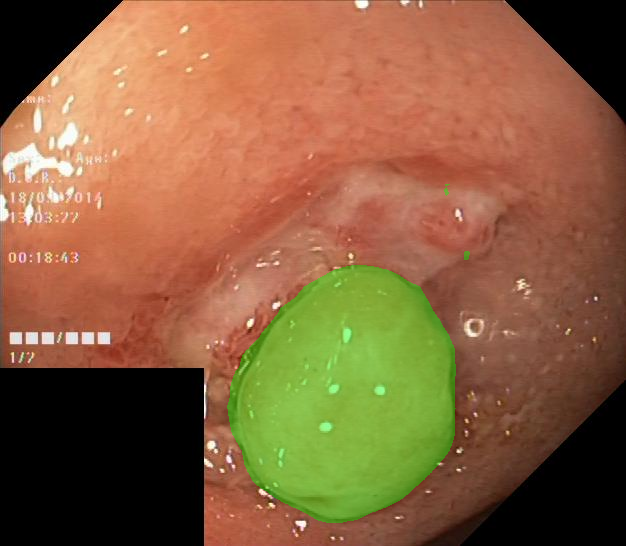

Threshold: 0.5 | Head: last


,image_id,dice,iou,precision,recall
1,cju13cgqmnhwn0988yrainhcp,0.959636,0.922404,0.937405,0.982947


Điểm trên dùng GT và ảnh 256×256. Overlay ở kích thước gốc chỉ để xem vùng dự đoán.


In [81]:
test_row = manifest.loc[manifest.image_id.eq('cju13cgqmnhwn0988yrainhcp')].iloc[0]
assert test_row['split'] == 'test'
prediction_summary = predict_file(run_paths['C']/'best.pt',test_row.image_path,
                                  OUTPUT/'demo',device=DEVICE)
display(DisplayImage(filename=str(OUTPUT/'demo/overlay.png')))
print('Threshold:',prediction_summary['threshold'],'| Head:',prediction_summary['head_policy'])
test_table = pd.read_csv(evaluations['C']/'per_image.csv')
display(test_table.loc[test_table.image_id.eq(test_row.image_id),['image_id','dice','iou','precision','recall']])
print('Điểm trên dùng GT và ảnh 256×256. Overlay ở kích thước gốc chỉ để xem vùng dự đoán.')

## 10 Kết luận và tự kiểm tra trước bảo vệ

Đọc bảng đối chiếu để biết lượt mới đạt gì, không tự thay số liệu báo cáo.
Kết quả chính chỉ có một seed/split, A/B khác dung lượng, chưa xác minh độc lập bệnh nhân/video,
chưa thử dữ liệu ngoài; đường validation ở cuối 50 epoch chưa chứng minh đã hội tụ.
Các ảnh đều có polyp nên chưa kiểm chứng false positive trên ảnh âm tính.
[Notebook thí nghiệm bổ sung](ThiNghiemBoSung_Nhom06.ipynb) chạy riêng phần sàng lọc ảnh tương tự và cắt tỉa từng head của checkpoint C.

Duy cần giải thích được: (1) ảnh/mask khác nhau thế nào; (2) concat theo dim=1;
(3) X(0,2) nhận 96 kênh; (4) logits khác xác suất; (5) mean bốn loss khác mean bốn xác suất;
(6) validation chọn best trước test; (7) mean Dice khác gộp pixel; (8) model tốt trung bình vẫn sai từng ảnh.

In [82]:
receipt = {'status':'completed','execution':'native notebook cells','train_from_scratch':TRAIN_FROM_SCRATCH,
           'training_mode':('reuse_completed_run' if REUSE_COMPLETED_RUN else 'fresh_training') if TRAIN_FROM_SCRATCH else 'report_checkpoints',
           'reuse_completed_run':REUSE_COMPLETED_RUN,
           'notebook_code_sha256':notebook_code_sha,'device':DEVICE,
           'split_counts':manifest.split.value_counts().to_dict(),
           'epochs':{k:v['epochs_completed'] for k,v in training_summaries.items()},
           'training_test_images_read':{k:v['test_images_read'] for k,v in training_summaries.items()},
           'test_image_count':comparison['image_count'],'comparison':comparison['comparison'],
           'report_reference_unchanged':True,'output':str(OUTPUT.relative_to(ROOT)),
           'run_paths':{k:str(v.relative_to(ROOT)) for k,v in run_paths.items()},
           'training_execution':{k:v['provenance'].get('execution',{}) for k,v in training_summaries.items()},
           'completed_at':datetime.now(timezone(timedelta(hours=7))).isoformat()}
(OUTPUT/'execution_receipt.json').write_text(json.dumps(receipt,indent=2,ensure_ascii=False),encoding='utf-8')
print('HOÀN THÀNH TOÀN BỘ NOTEBOOK')
display(pd.DataFrame(receipt['comparison'])[['experiment','dice','iou','parameters']])
print('Minh chứng:',OUTPUT.relative_to(ROOT)/'execution_receipt.json')

HOÀN THÀNH TOÀN BỘ NOTEBOOK


,experiment,dice,iou,parameters
0,A,0.601417,0.487259,7760097
1,B,0.668240,0.542089,9042177
2,C,0.739047,0.630404,9042276


Minh chứng: results\notebook_20261115_052209_244321\execution_receipt.json
